# Perennial Ryegrass Paddock Data (2013-2025): Cleaning and Exploratory Data Analysis

Teagasc PastureBase Ireland on-farm data: one row per paddock per year with grass growth (kg DM/ha), variety, sward age, soil and drainage. The notebook covers setup and helpers, the raw paddock and Met Éireann daily weather data, cleaning, data quality and missing data, exploration and location.

**Analysis decisions** are collected in **section 1.1**. Every place where values are filled in or set to missing is marked with a **MISSING DATA FILLED** or **SET TO MISSING** box in the text and a `MISSING DATA FILLED` / `SET TO MISSING` comment in the code, so they can be found with a search.

**Files written:** `df_clean.csv`, the private farm code key (`farm_code_key.csv`), the duplicate tables (`duplicate_pairs.csv`, `duplicate_pairs_rows.csv`, `duplicate_pairs_history.csv`) and `duplicate_decided_cells.csv`, plus PNG copies of the main plots and two summary tables in `figures/eda_01`.

## 1. Setup

In [1]:
# =============================================================================
# IMPORTS
# =============================================================================
# data handling and plotting
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon, Patch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from matplotlib.collections import PatchCollection, LineCollection
from scipy.stats import chi2_contingency
import plotly.io as pio
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pio.templates.default = "plotly_white"

In [2]:
# =============================================================================
# CONFIG
# =============================================================================
# finding the project folder (the one with data/ in it) so the paths work from any subfolder
def find_project_root(marker: str = "data", start: Path | None = None) -> Path:
    p = (start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / marker).is_dir():
            return parent
    return p

PROJECT_ROOT  = find_project_root()
DATA_PATH     = PROJECT_ROOT / "data" / "12_Year_Data_Set (1).csv"
BOUNDARY_PATH = PROJECT_ROOT / "weather_data" / "boundaries" / "ireland-counties.geojson"
DAILY_DIR     = PROJECT_ROOT / "weather_data" / "met_eireann_daily"   # Met Éireann daily station files
WEATHER_START, WEATHER_END = "2010-01-01", "2025-12-31"
CLEAN_PATH    = PROJECT_ROOT / "data" / "processed" / "df_clean.csv"
DUPLICATES_PATH = PROJECT_ROOT / "data" / "processed" / "duplicate_pairs.csv"
DUPLICATES_ROWS_PATH = PROJECT_ROOT / "data" / "processed" / "duplicate_pairs_rows.csv"
DUPLICATES_HISTORY_PATH = PROJECT_ROOT / "data" / "processed" / "duplicate_pairs_history.csv"
DECIDED_CELLS_PATH = PROJECT_ROOT / "data" / "processed" / "duplicate_decided_cells.csv"
FIG_DIR       = PROJECT_ROOT / "figures" / "eda_01"   # PNG copies of the main plots and the univariate tables
# private folder next to the project folder (not shared): key between farm codes and the original farm numbers and names
PRIVATE_DIR   = PROJECT_ROOT.parent / "final-tes-private"
FARM_KEY_PATH = PRIVATE_DIR / "farm_code_key.csv"
RANDOM_STATE  = 42
TARGET        = "Total_DM_S"   # target: Total_DM_S = Grazing_Total + Silage_Total in every row (section 6, Total_DM vs Total_DM_S)

for name, path in [("Data", DATA_PATH), ("Daily weather", DAILY_DIR), ("Boundaries", BOUNDARY_PATH)]:
    print(f"{name:<14} {path} | exists: {path.exists()}")

Data           C:\Users\Kasia\OneDrive\College\final-tes\data\12_Year_Data_Set (1).csv | exists: True
Daily weather  C:\Users\Kasia\OneDrive\College\final-tes\weather_data\met_eireann_daily | exists: True
Boundaries     C:\Users\Kasia\OneDrive\College\final-tes\weather_data\boundaries\ireland-counties.geojson | exists: True


In [3]:
# =============================================================================
# HELPERS
# =============================================================================
# printing settings for chapters and tables, and small calculations used in several chapters
def section(title: str):
    print("\n" + "=" * 95)
    print(title)
    print("=" * 95)

def print_df(df: pd.DataFrame, name: str, n: int = 10):
    print("\n" + "-" * 95)
    print(f"[DATAFRAME] {name} | shape = {df.shape[0]:,} rows × {df.shape[1]:,} cols")
    print("-" * 95)
    print(df.head(n).to_string())

def pct(x):
    return 100 * x

def save_fig(fig, name: str, width: int = 1400, height: int | None = None):
    # PNG copy of a matplotlib or plotly figure in FIG_DIR
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.png"
    if hasattr(fig, "savefig"):
        fig.savefig(path, dpi=200, bbox_inches="tight")
    else:
        fig.write_image(path, width=width, height=height or fig.layout.height or 700, scale=2)

def target_by(df: pd.DataFrame, col: str, target: str = TARGET) -> pd.DataFrame:
    # count, mean, median and lift vs the overall mean of the target per category
    g = df.groupby(col)[target].agg(count="size", mean="mean", median="median").reset_index()
    g["lift_vs_baseline_x"] = (g["mean"] / df[target].mean()).round(3)
    return g

def mean_se(df: pd.DataFrame, by, col: str) -> pd.DataFrame:
    # mean and standard error of a column per group, for bar charts with error bars
    g = df.groupby(by)[col].agg(mean="mean", std="std", n="size").reset_index()
    g["se"] = g["std"] / np.sqrt(g["n"])
    return g

def year_range(years) -> str:
    # e.g. '14-'20, or one year '25
    first, last = int(min(years)), int(max(years))
    return f"'{str(first)[2:]}" if first == last else f"'{str(first)[2:]}-'{str(last)[2:]}"

### 1.1 Analysis decisions

These settings control every place where the data is changed, or filled in. They are defined once in the cell below and used throughout the notebook; the values shown are the choices explained in the text.

| # | Where | What happens | Decision (default) | Based on | Switch |
|---|---|---|---|---|---|
| 0a | 2.1 Pseudonymisation | `Farm_number` replaced by a random farm code (F001-F121); `FARM_name` dropped | Codes shuffled with `RANDOM_STATE`; the key is saved outside the project folder | Farm names are personal data; the analysis only needs a farm identifier | `FARM_CODE_PREFIX`, `FARM_KEY_PATH` |
| 0b | 2.2 Region | `REGION` added from the county | NUTS 3 regions, with at least 5 farms per region | 10 of the 19 counties have fewer than 5 farms, so county summaries describe single farms | `REGION_BY_COUNTY`, `MIN_FARMS_PER_REGION` |
| 0c | 2. Variety names | Three spelling errors in `PRG_Var` corrected; `SWARD_TYPE` gets a fourth group, **Multispecies** | `Astonenergy (Y)` and `Glenfield ()` read as `(T)`; a stray `-` at the end of a name removed; mixtures with clover, plantain, chicory or timothy = Multispecies | The other records of both varieties are marked `(T)`; `Solas (T)-` has `MONO` = 1 (single variety); a sward with other species is not a ryegrass mixture | `PRG_VAR_FIXES`, `MULTISPECIES_WORDS` |
| 1 | 4. Duplicates, step 3 | A `Total_DM` far from its own `Total_DM_S` is replaced | Gap over 50% = typing error | Paddock 14100 (2023): 1,096 vs 11,010 | `TYPO_GAP_SHARE` |
| 2 | 4. Duplicates, step 5 | 51 near-duplicate paddock-year pairs combined | The **whole entry whose `Total_DM_S` equals its own seasonal sum** (spring + mid-season + autumn) is kept; a pair where neither entry adds up is averaged | The seasonal figures are identical in both entries, so only one annual total is consistent with them (to confirm with Teagasc) | `DUPLICATE_PAIR_RULE`, `SEASON_SUM_TOL`, `SEASON_SUM_FALLBACK` |
| 4 | 5.1 Drainage (before the exploration) | **Filled** from other years of the same paddock, else "Unknown" | Fill within paddock | Drainage never changes within a paddock (section 5) | `DRAINAGE_FILL_WITHIN_PADDOCK`, `DRAINAGE_UNKNOWN_LABEL` |

In [4]:
# =============================================================================
# DECISIONS (SETTINGS USED THROUGHOUT THE NOTEBOOK)
# =============================================================================
# every switch that changes, fills or holds back data; the table above says where each is used
# --- section 2.1: pseudonymisation
FARM_CODE_PREFIX = "F"      # farm codes F001, F002, ...; order shuffled with RANDOM_STATE, reused from FARM_KEY_PATH when it exists

# --- section 2.2: regions (NUTS 3 regions, Border split into North-west and a joint East and North-east group)
REGION_BY_COUNTY = {
    "Cork": "South-west", "Kerry": "South-west",
    "Limerick": "Mid-west", "Tipperary": "Mid-west", "Clare": "Mid-west",
    "Kilkenny": "South-east", "Wexford": "South-east", "Waterford": "South-east", "Carlow": "South-east",
    "Galway": "West", "Mayo": "West", "Roscommon": "West",
    "Donegal": "North-west", "Sligo": "North-west", "Leitrim": "North-west",
    "Westmeath": "Midlands", "Laois": "Midlands", "Longford": "Midlands", "Offaly": "Midlands",
    "Kildare": "East and North-east", "Meath": "East and North-east", "Louth": "East and North-east",
    "Cavan": "East and North-east", "Monaghan": "East and North-east", "Dublin": "East and North-east",
    "Wicklow": "East and North-east",
}
MIN_FARMS_PER_REGION = 5      # every region must hold at least this many farms

# --- section 2: variety names and sward type
PRG_VAR_FIXES = {"Astonenergy (Y)": "Astonenergy (T)",   # (Y) is a typo for (T): all other Astonenergy records are tetraploid or (T)
                 "Glenfield ()": "Glenfield (T)"}         # empty brackets: the other 66 Glenfield records are (T)
MULTISPECIES_WORDS = r"clover|plantain|chicory|timothy|trifol"  # a mixture naming any of these is a multispecies sward

# --- section 4: duplicate paddock-years
TYPO_GAP_SHARE      = 0.5      # Total_DM more than 50% away from Total_DM_S = typing error, replaced by Total_DM_S
DUPLICATE_PAIR_RULE = "season_sum"  # how near-duplicate pairs are combined: "season_sum", "history", "mean", "first", "max" or "min"
                                    # "season_sum": the whole entry whose Total_DM_S equals Spring_total + Mid_total + Aut_total
                                    # "history": the whole entry whose Total_DM_S is closer to the mean of the paddock's
                                    # comparable previous years (same sward, after the sowing year, up to HISTORY_YEARS back)
SEASON_SUM_TOL      = 1          # kg DM/ha; an entry "adds up" when |Total_DM_S - seasonal sum| is below this
SEASON_SUM_FALLBACK = "mean"     # pairs where neither entry (or both) adds up: "mean" (average) or "first" (entry 1)
HISTORY_YEARS       = 3          # previous years looked at by the "history" rule
HISTORY_FALLBACK    = "mean"     # pairs with no comparable previous year: "mean" (average) or "first" (entry 1)

# --- section 5.1: missing data
DRAINAGE_FILL_WITHIN_PADDOCK = True       # fill drainage from other years of the same paddock
DRAINAGE_UNKNOWN_LABEL       = "Unknown"  # category for paddocks with no drainage recorded at all

print(f"Duplicates: typo gap {TYPO_GAP_SHARE:.0%}, pairs combined by '{DUPLICATE_PAIR_RULE}' "
      f"(season sum: tolerance {SEASON_SUM_TOL} kg, fallback '{SEASON_SUM_FALLBACK}')")
print(f"Drainage fill within paddock: {DRAINAGE_FILL_WITHIN_PADDOCK} (otherwise '{DRAINAGE_UNKNOWN_LABEL}')")
print(f"Farm codes: {FARM_CODE_PREFIX}001... | regions: {len(set(REGION_BY_COUNTY.values()))}, at least {MIN_FARMS_PER_REGION} farms each")

Duplicates: typo gap 50%, pairs combined by 'season_sum' (season sum: tolerance 1 kg, fallback 'mean')
Drainage fill within paddock: True (otherwise 'Unknown')
Farm codes: F001... | regions: 7, at least 5 farms each


In [5]:
# =============================================================================
# LOAD RAW DATA
# =============================================================================
# reading the file exactly as it is, before any cleaning
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
print(df_raw.shape)
print(df_raw.columns.tolist())
# preview without FARM_name and Farm_number: farm names and numbers are replaced by codes in section 2.1
df_raw.drop(columns=["FARM_name", "Farm_number"]).head()

(11591, 68)
['FARM_name', 'Farm_number', 'COUNTY', 'YEAR', 'PADDOCK', 'DRAINAGE', 'Variety', 'PRG_Var', 'Grazing_PPI', 'RGH', 'GROUNDSCORE', 'MONO', 'YEAR_SOW', 'age', 'Select', 'RESEED_DATE', 'SOWING_RATE', 'SOILTEST', 'SOILPH', 'SOILPINDEX', 'Pindex', 'SOILKINDEX', 'Kindex', 'SPR_SILAGE', 'Num_spring_gr', 'SPR_GRAZING', 'Spring_Sil', 'Spring_total', 'MID_SILAGE', 'MID_GRAZINGS', 'MID_GRAZING', 'MID_SILAGE.1', 'Mid_total', 'AUT_SILAGE', 'AUT_GRAZINGS', 'AUT_GRAZING', 'AUT_SILAGEYLD', 'Aut_total', 'Num_SILAGE', 'Num_grazings', 'Total_events', 'Grazing_Total', 'Silage_Total', 'Total_DM', 'Total_DM_S', 'spring_cont', 'summer_cont', 'Autumn_Cont', '.', '..1', '..2', '..3', '..4', '..5', '..6', '..7', '..8', '..9', '..10', '..11', '..12', '..13', '..14', '..15', '..16', '..17', '..18', '..19']


,COUNTY,YEAR,PADDOCK,DRAINAGE,Variety,PRG_Var,Grazing_PPI,RGH,GROUNDSCORE,MONO,YEAR_SOW,age,Select,RESEED_DATE,SOWING_RATE,SOILTEST,SOILPH,SOILPINDEX,Pindex,SOILKINDEX,Kindex,SPR_SILAGE,Num_spring_gr,SPR_GRAZING,Spring_Sil,Spring_total,MID_SILAGE,MID_GRAZINGS,MID_GRAZING,MID_SILAGE.1,Mid_total,AUT_SILAGE,AUT_GRAZINGS,AUT_GRAZING,AUT_SILAGEYLD,Aut_total,Num_SILAGE,Num_grazings,Total_events,Grazing_Total,Silage_Total,Total_DM,Total_DM_S,spring_cont,summer_cont,Autumn_Cont,.,..1,..2,..3,..4,..5,..6,..7,..8,..9,..10,..11,..12,..13,..14,..15,..16,..17,..18,..19
0,Cork,2020,12561,Poorly drained,Aberbann,Aberbann,2.3,0,2.5,1,2020,0,0,28/04/2020,40.2,43700,6.5,20.2,.,125,.,0,1,1362,0,1362,0,5,4873,0,4873,0,4,5187,0,5187,0,10,10,11628,0,11628,11628,0.12,0.42,0.45,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.
1,Cork,2024,12561,Poorly drained,Aberbann-Buddy,Aberbann,2.3,0,.,1,2020,4,2,28/04/2020,40.2,.,.,.,.,.,.,0,0,1101,0,1101,0,5,6042,0,6042,0,3,4112,0,4112,0,8,8,11287,0,11287,11287,0.10,0.54,0.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Cork,2023,12561,Poorly drained,Aberbann-Buddy,Aberbann,2.3,0,.,1,2020,3,1,28/04/2020,40.2,16/01/2023,6.2,17.7,4,256,4,0,1,1323,0,1323,0,5,7916,0,7916,0,2,4026,0,4026,0,8,8,13391,0,13391,13391,0.10,0.59,0.30,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.
3,Cork,2022,12561,Poorly drained,Aberbann-Buddy,Aberbann,2.3,0,.,1,2020,2,1,28/04/2020,40.2,25/01/2022,6.7,26.7,4,248,4,0,1,809,0,809,0,7,9246,0,9246,0,2,3382,0,3382,0,10,10,13616,0,13616,13616,0.06,0.68,0.25,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.
4,Cork,2021,12561,Poorly drained,Aberbann-Buddy,Aberbann,2.3,0,2,1,2020,1,1,28/04/2020,40.2,14/12/2020,6.2,20.7,4,.,149,0,1,2570,0,2570,0,5,6239,0,6239,0,3,5869,0,5869,0,9,9,14498,0,14498,14498,0.18,0.43,0.40,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.


**Summary:** the raw file has 11,591 rows and 68 columns. `.` is used as the missing-value code, so most numeric columns load as text, and the last 20 columns (`.`, `..1` … `..19`) have no name: they are empty Excel export columns.

**Seasonal totals against `Total_DM_S`.** The three season totals (`Spring_total`, `Mid_total`, `Aut_total`) are compared with the annual total `Total_DM_S` in the raw data. The difference is kept as a new column, `SEASON_GAP` = `Total_DM_S` minus the seasonal sum (positive when the annual total is above the three seasons together). It is a same-year outcome, not an explanatory variable.

In [6]:
# =============================================================================
# CHECK: DO THE SEASONAL TOTALS ADD UP TO TOTAL_DM_S?
# =============================================================================
section("Spring + mid-season + autumn totals against Total_DM_S (raw data)")
# '.' is the missing-value code in the raw file, so the columns are read as numbers here
season_cols = ["Spring_total", "Mid_total", "Aut_total"]
chk = df_raw[season_cols + [TARGET]].apply(pd.to_numeric, errors="coerce").dropna()
chk["season_sum"] = chk[season_cols].sum(axis=1)
chk["gap"] = chk[TARGET] - chk["season_sum"]          # positive = Total_DM_S above the seasonal sum
# >>> NEW COLUMN: SEASON_GAP = Total_DM_S - (Spring_total + Mid_total + Aut_total), kept in the cleaned data (section 2)
df_raw["SEASON_GAP"] = chk["gap"]
TOL = 1                                              # kg DM/ha, rounding

print(f"Rows with all four values: {len(chk):,} of {len(df_raw):,}")
print(f"Seasons equal Total_DM_S (within {TOL} kg): {(chk['gap'].abs() < TOL).sum():,} ({(chk['gap'].abs() < TOL).mean():.1%})")
print(f"Total_DM_S above the seasonal sum: {(chk['gap'] >= TOL).sum():,} | below: {(chk['gap'] <= -TOL).sum():,}")
print("\nGap (Total_DM_S - seasonal sum), kg DM/ha:")
print(chk["gap"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(0).to_string())
print("\nGap as a share of Total_DM_S:")
print(pd.cut((chk["gap"] / chk[TARGET]).abs(), [-np.inf, 0.001, 0.02, 0.05, 0.10, np.inf],
             labels=["< 0.1%", "0.1-2%", "2-5%", "5-10%", "> 10%"]).value_counts(sort=False).to_string())


Spring + mid-season + autumn totals against Total_DM_S (raw data)
Rows with all four values: 11,591 of 11,591
Seasons equal Total_DM_S (within 1 kg): 309 (2.7%)
Total_DM_S above the seasonal sum: 8,370 | below: 2,912

Gap (Total_DM_S - seasonal sum), kg DM/ha:
count    11591.0
mean       137.0
std        600.0
min      -5092.0
5%        -558.0
25%         -2.0
50%        119.0
75%        247.0
95%        562.0
max       8100.0

Gap as a share of Total_DM_S:
< 0.1%     550
0.1-2%    7236
2-5%      2880
5-10%      516
> 10%      409


In [7]:
# raw table with SEASON_GAP; FARM_name and Farm_number not shown (replaced by farm codes in section 2.1)
print(df_raw.shape)
print(df_raw.drop(columns=["FARM_name", "Farm_number"]))

(11591, 69)
        COUNTY  YEAR  PADDOCK        DRAINAGE              Variety       PRG_Var Grazing_PPI   RGH GROUNDSCORE  MONO YEAR_SOW age Select RESEED_DATE SOWING_RATE    SOILTEST SOILPH SOILPINDEX Pindex  \
0         Cork  2020    12561  Poorly drained             Aberbann      Aberbann         2.3     0         2.5     1     2020   0      0  28/04/2020        40.2       43700    6.5       20.2      .   
1         Cork  2024    12561  Poorly drained       Aberbann-Buddy      Aberbann         2.3     0           .     1     2020   4      2  28/04/2020        40.2           .      .          .      .   
2         Cork  2023    12561  Poorly drained       Aberbann-Buddy      Aberbann         2.3     0           .     1     2020   3      1  28/04/2020        40.2  16/01/2023    6.2       17.7      4   
3         Cork  2022    12561  Poorly drained       Aberbann-Buddy      Aberbann         2.3     0           .     1     2020   2      1  28/04/2020        40.2  25/01/2022    6.7     

**Summary:** the seasons add up exactly to `Total_DM_S` in only 309 of the 11,591 rows (2.7%). In most rows the annual total is slightly higher than the three seasons together (8,370 rows, median gap +119 kg DM/ha), and in 2,912 rows it is lower. The gap is within 2% of `Total_DM_S` in 7,786 rows but above 10% in 409, with extremes of −5,092 and +8,100 kg DM/ha. `SEASON_GAP` keeps this difference for every row.

### 1.2 Raw weather data: Met Éireann daily stations

Daily observations from Met Éireann synoptic stations, 2010-2025 (https://www.met.ie/climate/available-data/historical-data, CC BY 4.0, attribution "Met Éireann"). Each county is linked to its main station for temperature, rain, soil and soil moisture, and to the nearest sunshine station. The files are loaded as they are; they are not yet joined to the paddock data.

In [8]:
# =============================================================================
# LOAD RAW WEATHER DATA
# =============================================================================
section("Met Éireann daily station files")
import io, re
# county -> (main station, sunshine station); station numbers as in the Met Éireann file names (dly<number>.csv)
COUNTY_STATIONS = {
    "Carlow": (375, 3723),   "Cavan": (675, 532),      "Clare": (518, 518),       "Cork": (575, 3904),
    "Donegal": (1575, 1575), "Dublin": (532, 532),     "Galway": (1875, 4935),    "Kerry": (2275, 2275),
    "Kildare": (3723, 3723), "Kilkenny": (375, 3723),  "Laois": (1475, 3723),     "Leitrim": (675, 4935),
    "Limerick": (518, 518),  "Longford": (1975, 4935), "Louth": (1375, 532),      "Mayo": (2175, 4935),
    "Meath": (1375, 532),    "Monaghan": (675, 532),   "Offaly": (1475, 3723),    "Roscommon": (1975, 4935),
    "Sligo": (2175, 4935),   "Tipperary": (1475, 518), "Waterford": (575, 3904),  "Westmeath": (875, 3723),
    "Wexford": (1775, 3723), "Wicklow": (3723, 3723),
}

def read_station(stno: int) -> pd.DataFrame:
    # the file starts with a free-text header; the table begins at the line starting with "date,"
    text = (DAILY_DIR / f"dly{stno}.csv").read_text(encoding="latin-1")
    name = re.search(r"Station Name:\s*(.+)", text).group(1).strip().title()
    d = pd.read_csv(io.StringIO(text[text.index("\ndate,") + 1:]), low_memory=False)
    d = d.loc[:, ~d.columns.str.startswith("i")]             # quality indicator columns
    d["date"] = pd.to_datetime(d["date"], format="%d-%b-%Y")
    for c in d.columns.drop("date"):
        d[c] = pd.to_numeric(d[c], errors="coerce")          # blanks and flags -> missing
    d = d[(d["date"] >= WEATHER_START) & (d["date"] <= WEATHER_END)].copy()
    d.insert(0, "station", stno)
    d.insert(1, "station_name", name)
    return d

stations = sorted({s for pair in COUNTY_STATIONS.values() for s in pair})
weather_daily = pd.concat([read_station(s) for s in stations], ignore_index=True)
measures = ["maxtp", "mintp", "gmin", "rain", "soil", "sun", "glorad", "pe", "smd_wd", "smd_md", "smd_pd"]
for c in measures:
    if c not in weather_daily:
        weather_daily[c] = np.nan
print(f"Stations: {len(stations)} | days: {len(weather_daily):,} | "
      f"{weather_daily['date'].min().date()} to {weather_daily['date'].max().date()}")
print_df(weather_daily[["station", "station_name", "date"] + measures], "weather_daily", 5)

# share of days with a value, per station and measure
# checking the coverage of the weather data: how many days have a value for each measure, per station
coverage = weather_daily.groupby(["station", "station_name"])[measures].apply(lambda g: g.notna().mean().mul(100).round(0))
coverage.insert(0, "days", weather_daily.groupby(["station", "station_name"]).size())
print("\nMeasured days (%) per station:")
print(coverage.astype(int).to_string())

# stations used by the counties in the paddock data
# comparing the counties in the paddock data with the counties that have a Met Éireann station, and printing the station names
paddock_counties = sorted(df_raw["COUNTY"].dropna().astype(str).str.strip().str.title().unique())
names = weather_daily.drop_duplicates("station").set_index("station")["station_name"]
county_map = pd.DataFrame([(c, m, names[m], s, names[s]) for c, (m, s) in COUNTY_STATIONS.items() if c in paddock_counties],
                          columns=["county", "station", "station name", "sun_station", "sun station name"])
print(f"\nPaddock counties: {len(paddock_counties)} | linked to a station: {len(county_map)}")
print(county_map.to_string(index=False))


Met Éireann daily station files


Stations: 17 | days: 99,286 | 2010-01-01 to 2025-12-31

-----------------------------------------------------------------------------------------------
[DATAFRAME] weather_daily | shape = 99,286 rows × 14 cols
-----------------------------------------------------------------------------------------------
   station station_name       date  maxtp  mintp  gmin  rain   soil  sun  glorad   pe  smd_wd  smd_md  smd_pd
0      375     Oak Park 2010-01-01    0.9   -3.8  -7.7   0.0  0.854  NaN   293.0  0.0     0.0     0.0    -9.3
1      375     Oak Park 2010-01-02    4.1   -6.3 -11.5   0.3  0.447  NaN   369.0  0.0     0.0    -0.3    -9.2
2      375     Oak Park 2010-01-03    3.5   -4.6 -10.1   0.0  0.343  NaN   260.0  0.2     0.2     0.2    -8.5
3      375     Oak Park 2010-01-04    1.3   -5.7 -11.6   0.0  0.123  NaN   267.0  0.0     0.2     0.2    -8.0
4      375     Oak Park 2010-01-05    1.3   -1.7  -9.0   0.7  0.186  NaN   355.0  0.0     0.0    -0.5    -8.3

Measured days (%) per station:
  

**Summary:** 17 stations cover 2010-2025 (5,788-5,844 days each), and all 19 paddock counties are linked to a station. Temperature and rain are complete. Sunshine is measured at 7 stations only (Knock 66% of days), radiation is missing at the airports and Casement, and soil temperature and soil moisture have gaps at Claremorris (70%), Athenry (71-85%) and Knock (66%).

## 2. Data Cleaning

In [9]:
# =============================================================================
# CLEAN COLUMN NAMES AND MISSING-VALUE CODES
# =============================================================================
section("Cleaning column names and missing-value codes")
# reloading with '.' as missing, dropping the unnamed export columns, renaming the duplicate MID_SILAGE
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False, na_values=["."])

junk_cols = [c for c in df.columns if c.startswith(".")]
print(f"Unnamed columns dropped: {len(junk_cols)} | non-empty cells in them: {int(df[junk_cols].notna().sum().sum())}")
df = df.drop(columns=junk_cols)

# the second MID_SILAGE is the mid-season silage yield (pandas loads it as MID_SILAGE.1)
df = df.rename(columns={"MID_SILAGE.1": "MID_SILAGEYLD"})

# SEASON_GAP calculated in section 1 (same file, same row order)
df["SEASON_GAP"] = df_raw["SEASON_GAP"]

# removing spaces at the start/end of text values
for c in df.select_dtypes("object").columns:
    df[c] = df[c].str.strip()

print_df(df.drop(columns=["FARM_name", "Farm_number"]), "cleaned names (farm columns not shown, section 2.1)")
print(df.dtypes.value_counts().to_string())


Cleaning column names and missing-value codes
Unnamed columns dropped: 20 | non-empty cells in them: 2

-----------------------------------------------------------------------------------------------
[DATAFRAME] cleaned names (farm columns not shown, section 2.1) | shape = 11,591 rows × 47 cols
-----------------------------------------------------------------------------------------------
     COUNTY  YEAR  PADDOCK        DRAINAGE             Variety   PRG_Var  Grazing_PPI  RGH  GROUNDSCORE  MONO  YEAR_SOW  age  Select RESEED_DATE  SOWING_RATE    SOILTEST  SOILPH  SOILPINDEX  Pindex  SOILKINDEX  Kindex  SPR_SILAGE  Num_spring_gr  SPR_GRAZING  Spring_Sil  Spring_total  MID_SILAGE  MID_GRAZINGS  MID_GRAZING  MID_SILAGEYLD  Mid_total  AUT_SILAGE  AUT_GRAZINGS  AUT_GRAZING  AUT_SILAGEYLD  Aut_total  Num_SILAGE  Num_grazings  Total_events  Grazing_Total  Silage_Total  Total_DM  Total_DM_S  spring_cont  summer_cont  Autumn_Cont  SEASON_GAP
0      Cork  2020    12561  Poorly drained         

**Summary:** 20 unnamed export columns were removed (they hold only `.` apart from two stray `1` values). The second `MID_SILAGE` column is the mid-season silage yield and was renamed `MID_SILAGEYLD`. With `.` read as missing, all measurement columns are numeric. `SEASON_GAP` from section 1 is carried over.

In [10]:
# =============================================================================
# DATES
# =============================================================================
section("Parsing dates")
# RESEED_DATE is dd/mm/yyyy; SOILTEST mixes dd/mm/yyyy, dd-Mon-yy (29-Jan-24) and Excel serial numbers (43700 = 24/08/2019)
def parse_mixed_date(s: pd.Series) -> pd.Series:
    as_number = pd.to_numeric(s, errors="coerce")
    parsed = pd.to_datetime(as_number, unit="D", origin="1899-12-30")
    for fmt in ["%d/%m/%Y", "%d-%b-%y"]:
        parsed = parsed.fillna(pd.to_datetime(s.where(as_number.isna()), format=fmt, errors="coerce"))
    not_parsed = s.notna() & parsed.isna()
    print(f"{s.name}: values not parsed = {int(not_parsed.sum())}")
    return parsed

df["RESEED_DATE"] = parse_mixed_date(df["RESEED_DATE"])
df["SOILTEST"] = parse_mixed_date(df["SOILTEST"])

for c in ["RESEED_DATE", "SOILTEST"]:
    print(f"{c}: {df[c].notna().sum():,} dates | {df[c].min().date()} to {df[c].max().date()}")
print("RESEED_DATE year matches YEAR_SOW:", (df["RESEED_DATE"].dt.year == df["YEAR_SOW"]).mean().round(3))


Parsing dates
RESEED_DATE: values not parsed = 0
SOILTEST: values not parsed = 0
RESEED_DATE: 10,791 dates | 1991-08-01 to 2025-08-28
SOILTEST: 4,858 dates | 2008-01-23 to 2024-12-18
RESEED_DATE year matches YEAR_SOW: 0.931


**Variety names and sward type.** `PRG_Var` holds the sown variety as recorded by the farmer. A tetraploid is marked with `(T)` (written with or without a space); a name without `(T)` is taken as diploid, as no other ploidy label exists in the data. Varieties joined with a hyphen are a mixture. The following rules are applied:

1. **Spelling errors corrected** (`PRG_VAR_FIXES`): `Astonenergy (Y)` and `Glenfield ()` (one row each) become `(T)`, as all other records of both varieties are tetraploid; a stray hyphen at the end of five names is removed, so `Solas (T)-` is read as a single variety.
2. **`VARIETY`**: `PRG_Var` without the `(T)` mark, so that spellings of the same variety are joined.
3. **Ploidy of single varieties**: set by the majority of a variety's records, because Astonenergy and Meiduno are written both with and without `(T)`.
4. **`SWARD_TYPE`**: Diploid, Tetraploid, Mixture (ryegrass varieties only) or **Multispecies** (a mixture that also names clover, plantain, chicory or timothy).

Two limits remain. A tetraploid never marked `(T)` is counted as diploid, as the labels cannot be checked against an official variety list here. In 481 rows `MONO` codes a mixture (4 or 8) while `PRG_Var` names one variety only; these are kept as recorded, as a question for Teagasc.

In [11]:
# =============================================================================
# VARIETY NAMES AND SWARD TYPE
# =============================================================================
section("Variety names and sward type")
# >>> VALUES CORRECTED: decision PRG_VAR_FIXES (section 1.1), spelling errors fixed before variety and ploidy are worked out;
# a stray '-' at the end of a name is removed ('Solas (T)-' is a single variety, MONO = 1)
prg_before = df["PRG_Var"].copy()
df["PRG_Var"] = df["PRG_Var"].replace(PRG_VAR_FIXES).str.rstrip("-").str.strip()
changed = df["PRG_Var"].ne(prg_before) & prg_before.notna()
print(f"PRG_Var values corrected: {int(changed.sum())} rows")
print(pd.DataFrame({"before": prg_before[changed], "after": df.loc[changed, "PRG_Var"]}).value_counts().to_string(), "\n")

# PRG_Var writes some varieties in more than one way (AberGain(T), AberGain (T)); '(T)' marks a tetraploid, '-' a mixture
# it is removing the '(T)' from the variety name, but the ploidy is kept in a separate column
df["VARIETY"] = df["PRG_Var"].str.replace(r"\s*\(T\)", "", regex=True).str.strip()
is_mixture = df["PRG_Var"].str.contains("-")

# ploidy per single variety from the majority of its records (Astonenergy and Meiduno are written both ways)
# its taken from the PRG_Var spelling, not from the VARIETY column (which has the '(T)' removed)
tetraploid_share = df[~is_mixture].groupby("VARIETY")["PRG_Var"].apply(lambda x: x.str.contains(r"\(T\)").mean())
variety_ploidy = pd.Series(np.where(tetraploid_share >= 0.5, "Tetraploid", "Diploid"), index=tetraploid_share.index)

# mixtures naming clover, plantain, chicory or timothy are multispecies swards (decision MULTISPECIES_WORDS, section 1.1)
is_multispecies = is_mixture & df["PRG_Var"].str.contains(MULTISPECIES_WORDS, case=False)
df["SWARD_TYPE"] = np.select([is_multispecies, is_mixture], ["Multispecies", "Mixture"], default=df["VARIETY"].map(variety_ploidy))

print(f"PRG_Var spellings: {df['PRG_Var'].nunique()} -> varieties after cleaning: {df['VARIETY'].nunique()}")
print(f"Single varieties: {df.loc[~is_mixture, 'VARIETY'].nunique()} | mixtures: {df.loc[is_mixture, 'VARIETY'].nunique()}")
print(df["SWARD_TYPE"].value_counts().to_string())


Variety names and sward type
PRG_Var values corrected: 7 rows
before                                                 after                                               
AberChoice-AberGain(T)-AberHerald-Drumbo-Dunluce (T)-  AberChoice-AberGain(T)-AberHerald-Drumbo-Dunluce (T)    1
AberZeus-Cancan-Portstewart-Twystar-Xenon (T)-         AberZeus-Cancan-Portstewart-Twystar-Xenon (T)           1
Astonenergy (T)-Crusader-Meiduno (T)-Rosetta-          Astonenergy (T)-Crusader-Meiduno (T)-Rosetta            1
Astonenergy (Y)                                        Astonenergy (T)                                         1
Glenfield ()                                           Glenfield (T)                                           1
Navan (T)-Portstewart-Twystar-Xenon (T)-               Navan (T)-Portstewart-Twystar-Xenon (T)                 1
Solas (T)-                                             Solas (T)                                               1 

PRG_Var spellings: 466 -> varieties 

In [12]:
# =============================================================================
# FARM IDENTIFIER
# =============================================================================
section("Farm identifier")
# FARM_name has several spellings for the same farm, so Farm_number is used as the farm ID
names_per_farm = df.groupby("Farm_number")["FARM_name"].nunique()
print(f"Farm_number: {df['Farm_number'].nunique()} farms | FARM_name: {df['FARM_name'].nunique()} spellings")
print(f"Farms with more than one name spelling: {(names_per_farm > 1).sum()}")
print(f"Farms with paddocks in two counties: {(df.groupby('Farm_number')['COUNTY'].nunique() > 1).sum()}")
print(f"Paddocks: {df['PADDOCK'].nunique()} | each paddock belongs to one farm: {(df.groupby('PADDOCK')['Farm_number'].nunique() == 1).all()}")


Farm identifier
Farm_number: 121 farms | FARM_name: 167 spellings
Farms with more than one name spelling: 40
Farms with paddocks in two counties: 2
Paddocks: 2194 | each paddock belongs to one farm: True


**Summary:** `SOILTEST` dates stored in three formats are now real dates. `PRG_Var` is cleaned into `VARIETY` and `SWARD_TYPE` (diploid, tetraploid, mixture or multispecies) after seven spelling corrections. The 466 spellings give 453 variety names (54 single varieties and 399 mixtures). Of the 11,591 raw rows, 3,942 are tetraploid, 3,186 diploid, 4,022 ryegrass mixtures and 441 multispecies swards, which appear from 2020 onwards (34 farms). There are **121 farms** (`Farm_number`); the 167 `FARM_name` values are spellings of the same farms, so names are not used and are dropped in section 2.1.

### 2.1 Pseudonymisation: farm codes

Farm names are personal data, and the farm numbers are PastureBase identifiers that can be traced back to a farm. The analysis only needs to know which rows belong to the same farm, so:

1. every `Farm_number` is replaced by a **random farm code** (`F001` to `F121`). The order is shuffled with `RANDOM_STATE`, so the codes do not follow the original numbers;
2. the key (code, original number, most common name, number of name spellings) is saved to **`FARM_KEY_PATH`, a private folder outside the project folder**. When the key already exists it is reused, so a farm keeps the same code every time the notebook runs; a farm not yet in the key gets the next free code;
3. `FARM_name` is **dropped**, so no saved file (`df_clean.csv`, the duplicate tables and every file built from them) contains farm names or the original farm numbers.

The column keeps the name `Farm_number`, so every later step uses the codes without other changes.

In [13]:
# =============================================================================
# PSEUDONYMISATION: FARM CODES
# =============================================================================
section("Pseudonymisation: farm codes")
# random code per farm, key saved outside the project folder, FARM_name dropped
farms = pd.Series(sorted(df["Farm_number"].unique()), name="Farm_number")
if FARM_KEY_PATH.exists():
    farm_key = pd.read_csv(FARM_KEY_PATH)
    print(f"Key reused: {FARM_KEY_PATH} ({len(farm_key)} farms)")
else:
    farm_key = pd.DataFrame(columns=["FARM_CODE", "Farm_number", "FARM_name", "name_spellings"])
    print(f"New key: {FARM_KEY_PATH}")
new_farms = farms[~farms.isin(farm_key["Farm_number"])].sample(frac=1, random_state=RANDOM_STATE).tolist()
if new_farms:
    start = len(farm_key) + 1
    names = df.groupby("Farm_number")["FARM_name"].agg(lambda s: s.value_counts().index[0])
    spellings = df.groupby("Farm_number")["FARM_name"].nunique()
    farm_key = pd.concat([farm_key, pd.DataFrame({
        "FARM_CODE": [f"{FARM_CODE_PREFIX}{k:03d}" for k in range(start, start + len(new_farms))],
        "Farm_number": new_farms, "FARM_name": names[new_farms].values, "name_spellings": spellings[new_farms].values})],
        ignore_index=True)
    PRIVATE_DIR.mkdir(parents=True, exist_ok=True)
    farm_key.to_csv(FARM_KEY_PATH, index=False)
    print(f"Farms added to the key: {len(new_farms)}")

#  PSEUDONYMISED: original farm numbers replaced by the codes, farm names dropped
code_of = farm_key.set_index("Farm_number")["FARM_CODE"]
df["Farm_number"] = df["Farm_number"].map(code_of)
df = df.drop(columns=["FARM_name"])
assert df["Farm_number"].notna().all() and df["Farm_number"].nunique() == len(farms)
assert FARM_KEY_PATH.resolve().parent != PROJECT_ROOT.resolve() and PROJECT_ROOT.resolve() not in FARM_KEY_PATH.resolve().parents
print(f"Farms: {df['Farm_number'].nunique()} | codes {df['Farm_number'].min()} to {df['Farm_number'].max()} | "
      f"FARM_name in the data: {'FARM_name' in df.columns}")
print(f"Key saved outside the project folder: {not FARM_KEY_PATH.resolve().is_relative_to(PROJECT_ROOT.resolve())}")


Pseudonymisation: farm codes
Key reused: C:\Users\Kasia\OneDrive\College\final-tes-private\farm_code_key.csv (121 farms)
Farms: 121 | codes F001 to F121 | FARM_name in the data: False
Key saved outside the project folder: True


**Summary:** the 121 farms now carry the codes F001-F121 in shuffled order, and `FARM_name` is no longer in the data. The key is saved outside the project folder and reused on every run, so the codes stay the same; all later outputs show only the codes.

### 2.2 Region

Ten of the 19 counties in the data have fewer than 5 farms (Cavan and Meath have one each), so a county average there describes one or two farms rather than the county. `REGION` groups the counties into **NUTS 3 regions**, with two changes so that every region holds at least `MIN_FARMS_PER_REGION` farms: the Border region is split into **North-west** (Donegal, Sligo, Leitrim) and the rest joins the Mid-East counties as **East and North-east** (Kildare, Meath, Louth, Cavan; Monaghan, Dublin and Wicklow have no farms in the data). Tipperary is in the Mid-west, as in NUTS 3.

The official Irish NUTS 3 regions (EU NUTS 2016 revision, Commission Delegated Regulation (EU) 2016/2066, also used by the CSO)

`REGION` is used for summaries (sections 6 and 7). It is saved in `df_clean.csv`.

In [14]:
# =============================================================================
# REGION
# =============================================================================
section("Region from county")
# NUTS 3 based regions (REGION_BY_COUNTY, section 1.1); check that every region has at least MIN_FARMS_PER_REGION farms
not_mapped = sorted(set(df["COUNTY"].dropna()) - set(REGION_BY_COUNTY))
assert not not_mapped, f"Counties without a region: {not_mapped}"
df["REGION"] = df["COUNTY"].map(REGION_BY_COUNTY)

region_table = (df.groupby("REGION").agg(farms=("Farm_number", "nunique"), paddocks=("PADDOCK", "nunique"), records=("YEAR", "size"),
                                         counties=("COUNTY", lambda s: ", ".join(f"{c} ({df.loc[df['COUNTY'] == c, 'Farm_number'].nunique()})"
                                                                                for c in s.value_counts().index)))
                .sort_values("farms", ascending=False))
print(region_table.to_string())
print(f"\nSmallest region: {region_table['farms'].min()} farms (minimum {MIN_FARMS_PER_REGION}) | "
      f"counties with fewer than {MIN_FARMS_PER_REGION} farms: {(df.groupby('COUNTY')['Farm_number'].nunique() < MIN_FARMS_PER_REGION).sum()}")
assert (region_table["farms"] >= MIN_FARMS_PER_REGION).all(), "a region has too few farms"


Region from county
                     farms  paddocks  records                                      counties
REGION                                                                                     
South-west              39       797     4377                          Cork (34), Kerry (5)
Mid-west                23       521     2780                 Tipperary (12), Limerick (11)
West                    20       278     1476          Galway (10), Roscommon (5), Mayo (5)
South-east              18       257     1183      Kilkenny (8), Wexford (6), Waterford (4)
East and North-east      8       165      701  Cavan (1), Meath (1), Kildare (4), Louth (2)
Midlands                 8       123      667        Longford (2), Laois (2), Westmeath (4)
North-west               7        73      407                        Sligo (4), Donegal (3)

Smallest region: 7 farms (minimum 5) | counties with fewer than 5 farms: 10


**Summary:** 7 regions, each with at least 7 farms: South-west 39 farms, Mid-west 23, West 20, South-east 18, East and North-east 8, Midlands 8 and North-west 7. 10 of the 19 counties have fewer than 5 farms on their own, and the South-west is close to a Cork average (34 of its 39 farms).

## 3. Dataset Overview

- **Source:** Teagasc PastureBase Ireland, farmer-recorded herbage measurements (plate meter, cut-and-weigh or visual estimate)
- **Unit:** one paddock in one year (paddock-year)
- **Observations:** 11,591 paddock-years, 2,194 paddocks, 121 farms, 19 counties, 2013-2025
- **Target:** `Total_DM_S` - annual dry-matter production (kg DM/ha)
- **Other outcomes:** seasonal totals (spring, mid-season, autumn), grazing and silage yield, number of grazings

### Variable groups

- **Identifiers and location:** FARM_name, Farm_number, COUNTY, YEAR, PADDOCK
- **Variety and sward:** Variety, PRG_Var, Grazing_PPI, RGH, GROUNDSCORE, MONO
- **Establishment:** YEAR_SOW, age, Select, RESEED_DATE, SOWING_RATE
- **Soil and drainage:** DRAINAGE, SOILTEST, SOILPH, SOILPINDEX, Pindex, SOILKINDEX, Kindex
- **Seasonal outcomes:** spring, mid-season and autumn grazings, grazed DM, silage cuts and silage DM
- **Annual outcomes:** Num_SILAGE, Num_grazings, Total_events, Grazing_Total, Silage_Total, Total_DM, Total_DM_S
- **Seasonal shares:** spring_cont, summer_cont, Autumn_Cont

## Data dictionary

| Column | Meaning |
|---|---|
| `FARM_name` | Farm name ("owner - townland"), several spellings per farm; **dropped in section 2.1** (pseudonymisation) |
| `Farm_number` | Farm identifier; **replaced by a random farm code (F001-F121) in section 2.1** |
| `COUNTY` | County of the farm |
| `YEAR` | Measurement year (2013-2025) |
| `PADDOCK` | Paddock ID, repeated across years |
| `DRAINAGE` | Drainage class: Well / Moderately / Poorly drained |
| `Variety` | Variety or mixture as sown |
| `PRG_Var` | Main perennial ryegrass variety; `(T)` = tetraploid, `-` = mixture |
| `Grazing_PPI` | Per-variety Pasture Profit Index value (−15.4 to 19.2), likely grazing utilisation sub-index (€/ha) - to confirm |
| `RGH` | Per-variety value (−0.4 to 0.3) - meaning to confirm |
| `GROUNDSCORE` | Sward ground cover / density score (0-7) - to confirm |
| `MONO` | Sward code 1, 2, 4, 8 (1 = single variety, 2/4 = mixtures, 8 = to confirm) |
| `YEAR_SOW` | Year the paddock was sown |
| `age` | Sward age = YEAR − YEAR_SOW (0 = sowing year) |
| `Select` | Age band: 0 = sowing year, 1 = 1-3, 2 = 4-6, 3 = 7-10, 4 = 11+ years |
| `RESEED_DATE` | Date of reseeding |
| `SOWING_RATE` | Seed rate (kg/ha) |
| `SOILTEST` | Soil test date |
| `SOILPH` | Soil pH |
| `SOILPINDEX`, `Pindex` | Soil phosphorus (mg/L) and P index (1-4) |
| `SOILKINDEX`, `Kindex` | Soil potassium (mg/L) and K index (1-4) |
| `SPR_SILAGE`, `Num_spring_gr`, `SPR_GRAZING`, `Spring_Sil`, `Spring_total` | Spring (1 Feb-10 Apr): silage cuts, grazings, grazed DM, silage DM, total DM |
| `MID_SILAGE`, `MID_GRAZINGS`, `MID_GRAZING`, `MID_SILAGEYLD`, `Mid_total` | Mid-season (11 Apr-6 Aug): same measures |
| `AUT_SILAGE`, `AUT_GRAZINGS`, `AUT_GRAZING`, `AUT_SILAGEYLD`, `Aut_total` | Autumn (7 Aug-30 Nov): same measures |
| `Num_SILAGE`, `Num_grazings`, `Total_events` | Silage cuts, grazings, and both per year |
| `Grazing_Total`, `Silage_Total` | Annual grazed and silage DM |
| `Total_DM` | Annual total DM as recorded; differs from Grazing_Total + Silage_Total in 23 rows; not used as the target |
| `Total_DM_S` | Annual total (grazing + silage), used as the target; `Total_DM` differs from it in 23 rows (section 6) |
| `spring_cont`, `summer_cont`, `Autumn_Cont` | Share of Total_DM_S grown in each season |
| `SEASON_GAP` | Added in section 1: `Total_DM_S` minus `Spring_total` + `Mid_total` + `Aut_total` (kg DM/ha) |

## 4. Data Quality Checks

In [15]:
# =============================================================================
# DATA QUALITY CHECKS
# =============================================================================
section("Data quality checks")
# missing values, duplicates and numeric summary
na = df.isna().sum().sort_values(ascending=False)
print("Missing values per column:")
print(na[na > 0].to_string())

print(f"\nExact duplicate rows:        {df.duplicated().sum()}")
print(f"Duplicate PADDOCK-YEAR rows: {df.duplicated(['PADDOCK', 'YEAR']).sum()}")

section("describe(): numeric")
print(df.describe().T.round(2).to_string())


Data quality checks
Missing values per column:
RGH              9002
Grazing_PPI      9002
GROUNDSCORE      8686
Kindex           8579
Pindex           8579
SOILKINDEX       7961
DRAINAGE         6777
SOILPH           6733
SOILPINDEX       6733
SOILTEST         6733
Select           1097
YEAR_SOW          800
RESEED_DATE       800
age               800
SPR_SILAGE         17
Num_spring_gr      17
AUT_GRAZINGS       13
SOWING_RATE         1
MID_SILAGEYLD       1

Exact duplicate rows:        3
Duplicate PADDOCK-YEAR rows: 54

describe(): numeric


                 count                           mean                  min                  25%                  50%                  75%                  max           std
YEAR           11591.0                    2020.972134               2013.0               2019.0               2021.0               2024.0               2025.0      3.140072
PADDOCK        11591.0                   67171.051247              12183.0              13804.0              23825.0             108903.0             560652.0  83279.222501
Grazing_PPI     2589.0                       1.334608                -15.4                 -5.0                  0.0                 10.5                 19.2      9.058593
RGH             2589.0                       -0.02669                 -0.4                 -0.2                  0.0                  0.1                  0.3      0.188857
GROUNDSCORE     2905.0                       3.747707                  0.0                  3.0                  3.5                  4

### 4.1 Duplicate paddock-years: steps and logic

Each row should be **one paddock in one year**, so `PADDOCK` + `YEAR` must be unique. The check above found 54 extra rows. They are handled in six documented steps, so every change to the data can be seen:

1. **Find** the repeated paddock-years and the farms and years they come from
2. **Exact copies**: rows identical in every column
3. **Target check and typing error**: `Total_DM_S` against grazing + silage in every row, and one typing error in `Total_DM` (1,096 where `Total_DM_S` = 11,010)
4. **Merge rule** for the pairs that differ (decision and alternatives)
5. **Apply** the fix, with row counts at each stage
6. **Before and after** for the same paddocks, and a final check; step 6b lists all 51 pairs with the size of the differences

In [16]:
# =============================================================================
# DUPLICATE PADDOCK-YEAR ROWS
# =============================================================================
section("Duplicate paddock-year rows")
# which farms and years, and which columns differ inside each duplicate pair
dups = df[df.duplicated(["PADDOCK", "YEAR"], keep=False)].sort_values(["PADDOCK", "YEAR"])
print(dups.groupby(["Farm_number", "YEAR"]).size().rename("rows").to_string())

differs = dups.groupby(["PADDOCK", "YEAR"]).apply(lambda g: g.nunique()[g.nunique() > 1].index.tolist())
print("\nColumns that differ inside a pair:", Counter(c for cols in differs for c in cols).most_common(8))
dups[["Farm_number", "PADDOCK", "YEAR", "PRG_Var", "YEAR_SOW", "Grazing_Total", "Total_DM_S"]].head(10)


Duplicate paddock-year rows
Farm_number  YEAR
F037         2023    50
             2024    12
F042         2023    30
F105         2020     2
             2021     4
             2022     4
             2024     2
F111         2023     4



Columns that differ inside a pair: [('Grazing_Total', 51), ('Total_DM', 51), ('Total_DM_S', 51), ('SEASON_GAP', 51), ('summer_cont', 46), ('Autumn_Cont', 41), ('spring_cont', 30), ('Silage_Total', 4)]


,Farm_number,PADDOCK,YEAR,PRG_Var,YEAR_SOW,Grazing_Total,Total_DM_S
1934,F042,13284,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2022.0,13205,17746
1935,F042,13284,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2022.0,12364,16905
1941,F042,13286,2023,Astonconqueror-Astonenergy (T)-Glenfield (T),2022.0,15695,15695
1942,F042,13286,2023,Astonconqueror-Astonenergy (T)-Glenfield (T),2022.0,14848,14848
1950,F042,13289,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2022.0,10540,12784
1951,F042,13289,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2022.0,10461,12705
1971,F042,13294,2023,Astonconqueror-Astonenergy (T)-Glenfield (T),2022.0,11937,11937
1972,F042,13294,2023,Astonconqueror-Astonenergy (T)-Glenfield (T),2022.0,11769,11769
1978,F042,13295,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2021.0,14030,15184
1979,F042,13295,2023,Astonconqueror-Astonenergy (T)-Chieftian-Crusa...,2021.0,13777,14931


**Step 1: Find.** `duplicated(["PADDOCK", "YEAR"], keep=False)` marks both rows of every pair so they can be compared side by side; `nunique()` inside each pair shows which columns hold different values.

In [17]:
# =============================================================================
# STEP 2: EXACT COPIES
# =============================================================================
# rows identical in every column: the second row adds no information
exact_copies = df[df.duplicated(keep=False)].sort_values(["PADDOCK", "YEAR"])
print(f"Exact copies: {df.duplicated().sum()} rows to drop (pairs shown below)")
exact_copies[["Farm_number", "PADDOCK", "YEAR", "PRG_Var", "Grazing_Total", "Silage_Total", "Total_DM_S"]]

Exact copies: 3 rows to drop (pairs shown below)

,Farm_number,PADDOCK,YEAR,PRG_Var,Grazing_Total,Silage_Total,Total_DM_S
3082,F037,14093,2023,AberChoice-AberGain(T),2791,4068,6859
3083,F037,14093,2023,AberChoice-AberGain(T),2791,4068,6859
3111,F037,14097,2023,AberChoice-AberGain(T),2187,4068,6255
3112,F037,14097,2023,AberChoice-AberGain(T),2187,4068,6255
3170,F037,14107,2023,Anurad-Bowie-Nashota-Triwarwic (T),4769,1860,6629
3171,F037,14107,2023,Anurad-Bowie-Nashota-Triwarwic (T),4769,1860,6629


**Step 2 result:** 3 paddocks on farm F037 (2023) appear twice with every value identical. One row of each pair is dropped.

In [18]:
# =============================================================================
# STEP 3: TARGET CHECK AND TYPING ERROR IN TOTAL_DM
# =============================================================================
# 3a) the target: Total_DM_S should equal Grazing_Total + Silage_Total in every row, including both entries of every pair
section("Total_DM_S against Grazing_Total + Silage_Total")
target_gap = df["Total_DM_S"] - (df["Grazing_Total"] + df["Silage_Total"])
in_pair = df.duplicated(["PADDOCK", "YEAR"], keep=False)
print(f"All rows:          {(target_gap.abs() < 1).sum():,} of {len(df):,} equal")
print(f"Rows in a pair:    {(target_gap[in_pair].abs() < 1).sum():,} of {int(in_pair.sum()):,} equal")

# 3b) Total_DM (not the target) should also equal Total_DM_S; a large gap is a typing error in Total_DM
#  VALUE REPLACED: decision TYPO_GAP_SHARE (section 1.1)
typo = (df["Total_DM"] - df["Total_DM_S"]).abs() > TYPO_GAP_SHARE * df["Total_DM_S"]
typo_cols = ["Farm_number", "PADDOCK", "YEAR", "Grazing_Total", "Silage_Total", "Total_DM", "Total_DM_S"]

section("Typing error in Total_DM: before correction")
print(df.loc[df["PADDOCK"].isin(df.loc[typo, "PADDOCK"]) & df["YEAR"].isin(df.loc[typo, "YEAR"]), typo_cols].to_string())

df.loc[typo, "Total_DM"] = df.loc[typo, "Total_DM_S"]

section("After correction (Total_DM_S unchanged)")
print(df.loc[df["PADDOCK"].isin(df.loc[typo, "PADDOCK"]) & df["YEAR"].isin(df.loc[typo, "YEAR"]), typo_cols].to_string())


Total_DM_S against Grazing_Total + Silage_Total
All rows:          11,591 of 11,591 equal
Rows in a pair:    108 of 108 equal

Typing error in Total_DM: before correction
     Farm_number  PADDOCK  YEAR  Grazing_Total  Silage_Total  Total_DM  Total_DM_S
3135        F037    14100  2023           9263          1159     10422       10422
3136        F037    14100  2023          11010             0      1096       11010

After correction (Total_DM_S unchanged)
     Farm_number  PADDOCK  YEAR  Grazing_Total  Silage_Total  Total_DM  Total_DM_S
3135        F037    14100  2023           9263          1159     10422       10422
3136        F037    14100  2023          11010             0     11010       11010


**Step 3 result:** `Total_DM_S` equals `Grazing_Total` + `Silage_Total` in every row, including both entries of every pair, so the target itself has no typing errors. The only error is in `Total_DM`: paddock 14100 (farm F037, 2023) has `Total_DM` = 1,096 in one entry, while its `Total_DM_S` and grazing + silage give 11,010. The value 1,096 is a typing error (a digit missing) and is replaced by 11,010. `Total_DM` is not the target, so this correction does not change `Total_DM_S`; how the 14100 pair is combined is decided in step 5.

**Step 4: Merge rule (decision).** In the remaining 51 pairs the farm, variety, sowing year and every seasonal figure (spring, mid-season and autumn grazing and silage, and all counts) are the same in both rows. Only the annual totals (`Grazing_Total`, `Total_DM`, `Total_DM_S`), the season shares and `SEASON_GAP` calculated from them and, in 4 pairs, `Silage_Total` differ. No column holds a value in one entry and is empty in the other. The pairs come from 4 farms (F042 and F037 in 2023, F105 in 2020-2024, F111 in 2023), which looks like the same paddock-season saved twice in PastureBase with a later edit.

The gaps are not small (step 6b). The median difference in `Total_DM_S` between the two entries is 6.9%, 18 pairs differ by more than 10%, and the largest gap is 43% (paddock 24768, farm F111: 11,727 vs 6,635 kg DM/ha). Farm F042 is the exception, with a median gap of 1.1%. The **second entry is lower in 50 of the 51 pairs**, so the difference is systematic, not random noise.

**Check used: consistency with the entry's own seasons.** `Total_DM_S` is the sum of grazing and silage (`Grazing_Total` + `Silage_Total`) in both entries, so that sum cannot separate them. The seasonal figures, however, are identical in both entries, so only one annual total can agree with spring + mid-season + autumn. The first entry adds up in 43 pairs and the second in 7 (all farm F042, 2023); in one pair (paddock 14100, farm F037, 2023, the pair with the typing error) neither does. The second entry is usually below its seasonal sum (median −1,020 kg DM/ha), which is rare in the rest of the data.

**Rule used: "season_sum".** For each pair, the **whole entry** whose `Total_DM_S` equals its seasonal sum is kept (entry 1 in 43 pairs, entry 2 in 7), so grazing, silage, the total and the seasons stay consistent with each other. Paddock 14100 is **averaged** (`SEASON_SUM_FALLBACK`).

| Option | Effect | Assessment |
|---|---|---|
| **Keep the entry that equals its seasonal sum (chosen)** | Whole entry kept for 50 pairs; 1 averaged | Uses the record's own seasonal figures; every kept total agrees with its seasons |
| Keep the entry closer to the paddock's previous years | Whole entry for the 15 pairs with comparable history; 36 averaged | Independent reference, but disagrees with the seasonal sum in 10 of the 15 pairs |
| Keep the first entry | Whole first entry for all 51 | Same as the chosen rule except for the 7 F042 pairs and paddock 14100 |
| Average the two rows | Values half-way between the entries | Matches neither entry or its seasons |
| Keep the higher / lower value | One entry | Would bias yields up or down |
| Keep both rows | Paddock counted twice | Double-weights these paddocks in every average |

**Question for Teagasc:** which entry is the final record for these farms, and why is the second entry's annual total below its seasonal figures?

In [19]:
# =============================================================================
# STEP 5: APPLY THE FIX
# =============================================================================
# copy kept for the before/after comparison; drop exact copies; combine the remaining pairs by DUPLICATE_PAIR_RULE
df_before_dedup = df.copy()
rows_start = len(df)

df = df.drop_duplicates()
rows_after_exact = len(df)

id_cols = ["PADDOCK", "YEAR"]
mean_cols = [c for c in df.select_dtypes("number").columns
             if c not in id_cols + ["Farm_number", "MONO", "YEAR_SOW", "age", "Select"]]
# averaged version of every pair: the result of the "mean" rule, and the yearly history used by the "history" rule
mean_agg = {c: ("mean" if c in mean_cols else "first") for c in df.columns if c not in id_cols}
df_mean = df.groupby(id_cols, as_index=False, sort=False).agg(mean_agg)[df.columns]

pair_entries = df[df.duplicated(id_cols, keep=False)].copy()
pair_entries["entry"] = pair_entries.groupby(id_cols).cumcount() + 1
pair_choice = []

if DUPLICATE_PAIR_RULE == "season_sum":
    # >>> VALUES COMBINED: decision DUPLICATE_PAIR_RULE = "season_sum" (section 1.1)
    # per pair, the whole entry (all columns) whose Total_DM_S equals Spring_total + Mid_total + Aut_total;
    # the seasonal figures are identical in both entries, so at most one annual total agrees with them
    kept = df_mean.set_index(id_cols)
    value_cols = [c for c in df.columns if c not in id_cols]
    for (p, y), g in pair_entries.groupby(id_cols, sort=False):
        season_sum = g["Spring_total"] + g["Mid_total"] + g["Aut_total"]
        adds_up = (g[TARGET] - season_sum).abs() < SEASON_SUM_TOL
        if adds_up.sum() == 1:
            chosen = g[adds_up].iloc[0]
            kept.loc[(p, y), value_cols] = chosen[value_cols].values
            kept_from = f"entry {int(chosen['entry'])} (equals its seasonal sum)"
        elif SEASON_SUM_FALLBACK == "first":
            kept.loc[(p, y), value_cols] = g.iloc[0][value_cols].values
            kept_from = "entry 1 (neither entry adds up)"
        else:
            kept_from = "average (neither entry adds up)"
        pair_choice.append({"PADDOCK": p, "YEAR": y, "kept from": kept_from,
                            "season sum": float(season_sum.iloc[0]), "Total_DM_S entries": g[TARGET].tolist()})
    df = kept.reset_index()[df_mean.columns]
elif DUPLICATE_PAIR_RULE == "history":
    # >>> VALUES COMBINED: decision DUPLICATE_PAIR_RULE = "history" (section 1.1)
    # per pair, the whole entry (all columns) whose Total_DM_S is closer to the mean of the paddock's comparable previous years:
    # same sward and after the sowing year, up to HISTORY_YEARS back; without such a year, HISTORY_FALLBACK is used
    history_dm = df_mean.set_index(id_cols)[TARGET]
    kept = df_mean.set_index(id_cols)
    for (p, y), g in pair_entries.groupby(id_cols, sort=False):
        sow = g["YEAR_SOW"].iloc[0]
        prev = [history_dm.get((p, y - k)) for k in range(1, HISTORY_YEARS + 1) if y - k > sow]
        prev = [v for v in prev if v is not None and v == v]
        if prev:
            prev_mean = float(np.mean(prev))
            chosen = g.loc[(g[TARGET] - prev_mean).abs().idxmin()]
            kept.loc[(p, y), [c for c in df.columns if c not in id_cols]] = chosen[[c for c in df.columns if c not in id_cols]].values
            kept_from = f"entry {int(chosen['entry'])} (closer to previous years)"
        else:
            prev_mean = np.nan
            if HISTORY_FALLBACK == "first":
                kept.loc[(p, y), [c for c in df.columns if c not in id_cols]] = g.iloc[0][[c for c in df.columns if c not in id_cols]].values
                kept_from = "entry 1 (no comparable history)"
            else:
                kept_from = "average (no comparable history)"
        pair_choice.append({"PADDOCK": p, "YEAR": y, "kept from": kept_from, "previous years used": len(prev),
                            "previous years mean": round(prev_mean, 1) if prev else np.nan})
    df = kept.reset_index()[df_mean.columns]
elif DUPLICATE_PAIR_RULE == "mean":
    df = df_mean
    pair_choice = [{"PADDOCK": p, "YEAR": y, "kept from": "average"} for (p, y) in pair_entries.groupby(id_cols, sort=False).groups]
else:
    # "first", "max" or "min" applied column by column
    agg = {c: (DUPLICATE_PAIR_RULE if c in mean_cols else "first") for c in df.columns if c not in id_cols}
    df = df.groupby(id_cols, as_index=False, sort=False).agg(agg)[df.columns]
    pair_choice = [{"PADDOCK": p, "YEAR": y, "kept from": DUPLICATE_PAIR_RULE} for (p, y) in pair_entries.groupby(id_cols, sort=False).groups]
pair_choice = pd.DataFrame(pair_choice)

print(f"Rows at start:                 {rows_start:,}")
print(f"After dropping exact copies:   {rows_after_exact:,}  (-{rows_start - rows_after_exact})")
print(f"After combining the pairs:     {len(df):,}  (-{rows_after_exact - len(df)})  rule: '{DUPLICATE_PAIR_RULE}'")
print("\nWhat was kept for the 51 pairs:")
print(pair_choice["kept from"].value_counts().to_string())
if DUPLICATE_PAIR_RULE == "season_sum":
    print("\nPairs not kept from entry 1:")
    print(pair_choice[~pair_choice["kept from"].str.startswith("entry 1")].to_string(index=False))

Rows at start:                 11,591
After dropping exact copies:   11,588  (-3)
After combining the pairs:     11,537  (-51)  rule: 'season_sum'

What was kept for the 51 pairs:
kept from
entry 1 (equals its seasonal sum)    43
entry 2 (equals its seasonal sum)     7
average (neither entry adds up)       1

Pairs not kept from entry 1:
 PADDOCK  YEAR                         kept from  season sum Total_DM_S entries
   13314  2023 entry 2 (equals its seasonal sum)     12520.0     [12547, 12520]
   13315  2023 entry 2 (equals its seasonal sum)     12198.0     [12298, 12198]
   14100  2023   average (neither entry adds up)     12169.0     [10422, 11010]
   22636  2023 entry 2 (equals its seasonal sum)     13255.0     [13402, 13255]
   53715  2023 entry 2 (equals its seasonal sum)     12763.0     [12813, 12763]
   53719  2023 entry 2 (equals its seasonal sum)     14104.0     [14257, 14104]
  307508  2023 entry 2 (equals its seasonal sum)      6852.0       [6923, 6852]
  307515  2023 entry

In [20]:
# =============================================================================
# STEP 6: BEFORE AND AFTER
# =============================================================================
# the same paddock-years before (two rows) and after (one row), and checks that nothing else changed
show_cols = ["Farm_number", "PADDOCK", "YEAR", "YEAR_SOW", "Grazing_Total", "Silage_Total", "Total_DM_S",
             "spring_cont", "summer_cont", "Autumn_Cont"]
dup_keys = df_before_dedup[df_before_dedup.duplicated(["PADDOCK", "YEAR"], keep=False)][["PADDOCK", "YEAR"]].drop_duplicates()

section("Before: first 5 duplicate paddock-years (two rows each)")
print(df_before_dedup.merge(dup_keys)[show_cols].sort_values(["PADDOCK", "YEAR"]).head(10).to_string(index=False))
section("After: the same 5 paddock-years (one row each)")
print(df.merge(dup_keys)[show_cols].sort_values(["PADDOCK", "YEAR"]).head(5).to_string(index=False))

section("Checks")
print(f"Duplicate PADDOCK-YEAR left:              {df.duplicated(['PADDOCK', 'YEAR']).sum()}")
print(f"Paddock-years before / after:             {df_before_dedup[['PADDOCK', 'YEAR']].drop_duplicates().shape[0]:,} / {len(df):,}")
untouched = df_before_dedup.merge(dup_keys, how="left", indicator=True).query("_merge == 'left_only'").drop(columns="_merge")
print(f"Rows not in a pair, unchanged:            {len(untouched):,}")
print(f"Mean Total_DM_S before / after:             {df_before_dedup['Total_DM_S'].mean():,.1f} / {df['Total_DM_S'].mean():,.1f}")


Before: first 5 duplicate paddock-years (two rows each)
Farm_number  PADDOCK  YEAR  YEAR_SOW  Grazing_Total  Silage_Total  Total_DM_S  spring_cont  summer_cont  Autumn_Cont
       F042    13284  2023    2022.0          13205          4541       17746         0.07         0.59         0.34
       F042    13284  2023    2022.0          12364          4541       16905         0.07         0.62         0.36
       F042    13286  2023    2022.0          15695             0       15695         0.06         0.59         0.35
       F042    13286  2023    2022.0          14848             0       14848         0.06         0.62         0.38
       F042    13289  2023    2022.0          10540          2244       12784         0.08         0.60         0.33
       F042    13289  2023    2022.0          10461          2244       12705         0.08         0.60         0.33
       F042    13294  2023    2022.0          11937             0       11937         0.04         0.69         0.27
       

In [21]:
# =============================================================================
# STEP 6b: ALL PADDOCK-YEARS SAVED TWICE WITH DIFFERENT VALUES
# =============================================================================
section("Paddock-years saved twice with different values (both entries and the row kept)")
# both entries of every pair (exact copies removed first) next to the row kept in df, for all main columns
ID_COLS = ["Farm_number", "PADDOCK", "YEAR"]
INFO_COLS = ["COUNTY", "VARIETY", "SWARD_TYPE", "YEAR_SOW", "age", "DRAINAGE"]
MEASURE_COLS = ["Spring_total", "Mid_total", "Aut_total", "SPR_GRAZING", "MID_GRAZING", "AUT_GRAZING",
                "Spring_Sil", "MID_SILAGEYLD", "AUT_SILAGEYLD", "Grazing_Total", "Silage_Total", "Total_DM", "Total_DM_S",
                "Num_spring_gr", "MID_GRAZINGS", "AUT_GRAZINGS", "SPR_SILAGE", "MID_SILAGE", "AUT_SILAGE",
                "Num_grazings", "Num_SILAGE", "Total_events", "spring_cont", "summer_cont", "Autumn_Cont"]

pairs = df_before_dedup.drop_duplicates()
pairs = pairs[pairs.duplicated(["PADDOCK", "YEAR"], keep=False)].sort_values(ID_COLS).copy()
pairs["entry"] = (pairs.groupby(["PADDOCK", "YEAR"]).cumcount() + 1).astype(str)
pair_keys = pairs[["PADDOCK", "YEAR"]].drop_duplicates()
kept_rows = df.merge(pair_keys, on=["PADDOCK", "YEAR"]).assign(entry="kept")
print(f"Pairs: {len(pair_keys)} | rows in the file: {len(pairs)}")

# 1) long view: entry 1, entry 2 and the row kept, one under the other, all main columns
long_view = (pd.concat([pairs, kept_rows])[ID_COLS + ["entry"] + INFO_COLS + MEASURE_COLS]
               .sort_values(ID_COLS + ["entry"]))
long_view["Total_DM_S minus season sum"] = long_view["Total_DM_S"] - (long_view["Spring_total"] + long_view["Mid_total"] + long_view["Aut_total"])
section("Entry 1, entry 2 and the row kept (all main columns)")
print(long_view.to_string(index=False))

# second table: every row of every pair (entry 1, entry 2 and the row kept), all main columns
DUPLICATES_ROWS_PATH.parent.mkdir(parents=True, exist_ok=True)
long_view.to_csv(DUPLICATES_ROWS_PATH, index=False)
print(f"Saved: {DUPLICATES_ROWS_PATH} | {len(long_view)} rows x {long_view.shape[1]} columns")

# 2) which main columns differ between the two entries of each pair
differs = pairs.groupby(["PADDOCK", "YEAR"])[INFO_COLS + MEASURE_COLS].nunique(dropna=False).gt(1)
differs_list = differs.apply(lambda r: ", ".join(r.index[r]), axis=1).rename("columns that differ").reset_index()
section("Columns that differ between the two entries (number of pairs)")
counts = differs.sum()
print(counts[counts > 0].sort_values(ascending=False).to_string())
print(f"Identifying columns ({', '.join(INFO_COLS)}) differ in {int(differs[INFO_COLS].any(axis=1).sum())} pairs")

# 3) one line per pair: every measurement column for entry 1, entry 2 and the value kept
wide = pairs.pivot_table(index=ID_COLS, columns="entry", values=MEASURE_COLS, aggfunc="first", dropna=False)
wide.columns = [f"{col} ({e})" for col, e in wide.columns]
kept = kept_rows.set_index(ID_COLS)[MEASURE_COLS].add_suffix(" (kept)")
info = pairs[pairs["entry"] == "1"].set_index(ID_COLS)[INFO_COLS]
side = info.join(wide).join(kept)
side = side[INFO_COLS + [f"{col} ({s})" for col in MEASURE_COLS for s in ["1", "2", "kept"]]].reset_index()
side["Total_DM_S difference"] = side["Total_DM_S (2)"] - side["Total_DM_S (1)"]
side["difference %"] = (side["Total_DM_S difference"] / side["Total_DM_S (1)"] * 100).round(1)
side["silage differs"] = side["Silage_Total (1)"] != side["Silage_Total (2)"]
side = side.merge(differs_list, on=["PADDOCK", "YEAR"], how="left")

# the same paddock's Total_DM_S in the three previous years (from df, where earlier duplicates are already averaged)
paddock_dm = df.set_index(["PADDOCK", "YEAR"])["Total_DM_S"]
for k in [1, 2, 3]:
    side[f"Total_DM_S year-{k}"] = [paddock_dm.get((p, y - k), float("nan")) for p, y in zip(side["PADDOCK"], side["YEAR"])]
# comparable years only: same sward and after the sowing year (the sowing year grows little, earlier years are another sward)
prev_cols = [f"Total_DM_S year-{k}" for k in [1, 2, 3]]
comparable = side[prev_cols].where([[y - k > sow for k in [1, 2, 3]] for y, sow in zip(side["YEAR"], side["YEAR_SOW"])])
side["comparable years"] = comparable.notna().sum(axis=1)
side["comparable years mean"] = comparable.mean(axis=1).round(1)
gap_1 = (side["Total_DM_S (1)"] - side["comparable years mean"]).abs()
gap_2 = (side["Total_DM_S (2)"] - side["comparable years mean"]).abs()
side["entry closer to comparable years"] = [("1" if a < b else "2") if b == b else "no comparable history" for a, b in zip(gap_1, gap_2)]

# consistency check: the seasonal totals are identical in both entries, so each annual total can be compared with their sum
side["season sum"] = side["Spring_total (1)"] + side["Mid_total (1)"] + side["Aut_total (1)"]
side["Total_DM_S (1) - season sum"] = side["Total_DM_S (1)"] - side["season sum"]
side["Total_DM_S (2) - season sum"] = side["Total_DM_S (2)"] - side["season sum"]
side["entry matching its seasons"] = ["1" if abs(a) < abs(b) else "2" if abs(b) < abs(a) else "same"
                                      for a, b in zip(side["Total_DM_S (1) - season sum"], side["Total_DM_S (2) - season sum"])]

# which entry is higher and how large the gap is, for reading the one-line table
side["higher entry"] = np.select([side["Total_DM_S (1)"] > side["Total_DM_S (2)"], side["Total_DM_S (2)"] > side["Total_DM_S (1)"]], ["1", "2"], "same")
side["gap size"] = pd.cut(side["difference %"].abs(), [0, 5, 10, 20, 100], right=False,
                          labels=["under 5%", "5-10%", "10-20%", "20% or more"]).astype(str)
print("Pairs by gap size:", side["gap size"].value_counts().reindex(["under 5%", "5-10%", "10-20%", "20% or more"]).to_dict(),
      "| higher entry:", side["higher entry"].value_counts().to_dict())

# one line per pair: both entries, the value kept, the difference and the previous years
ONE_LINE_COLS = ID_COLS + ["YEAR_SOW", "Grazing_Total (1)", "Grazing_Total (2)", "Grazing_Total kept",
                           "Silage_Total (1)", "Silage_Total (2)", "Silage_Total kept",
                           "Total_DM_S (1)", "Total_DM_S (2)", "Total_DM_S kept", "kept from", "Total_DM_S difference", "difference %",
                           "higher entry", "gap size", "season sum", "entry matching its seasons",
                           "Total_DM_S year-1", "Total_DM_S year-2", "Total_DM_S year-3",
                           "comparable years", "comparable years mean", "entry closer to comparable years"]
side = side.merge(pair_choice[["PADDOCK", "YEAR", "kept from"]], on=["PADDOCK", "YEAR"], how="left")
one_line = side.rename(columns={"Grazing_Total (kept)": "Grazing_Total kept", "Silage_Total (kept)": "Silage_Total kept",
                                "Total_DM_S (kept)": "Total_DM_S kept"})[ONE_LINE_COLS]
section("One line per pair")
print(one_line.to_string(index=False))

DUPLICATES_PATH.parent.mkdir(parents=True, exist_ok=True)
one_line.to_csv(DUPLICATES_PATH, index=False)
print(f"Saved: {DUPLICATES_PATH} | {len(one_line)} rows x {one_line.shape[1]} columns")

# every column that differs between the entries, compared with the same column in the paddock's three previous years
section("Columns that differ, compared with the paddock's previous years")
HISTORY_COLS = ["Grazing_Total", "Silage_Total", "Total_DM_S"]
history_rows = []
for col in HISTORY_COLS:
    col_history = df.set_index(["PADDOCK", "YEAR"])[col]
    for _, r in side.iterrows():
        prev = {k: col_history.get((r["PADDOCK"], r["YEAR"] - k), np.nan) for k in [1, 2, 3]}
        comparable_values = [prev[k] for k in [1, 2, 3] if r["YEAR"] - k > r["YEAR_SOW"] and prev[k] == prev[k]]
        m = float(np.mean(comparable_values)) if comparable_values else np.nan
        a, b = r[f"{col} (1)"], r[f"{col} (2)"]
        closer = ("same in both entries" if a == b else "no comparable history" if not comparable_values
                  else "1" if abs(a - m) < abs(b - m) else "2")
        history_rows.append({"Farm_number": r["Farm_number"], "PADDOCK": r["PADDOCK"], "YEAR": r["YEAR"], "YEAR_SOW": r["YEAR_SOW"],
                             "column": col, "entry 1": a, "entry 2": b, "year-1": prev[1], "year-2": prev[2], "year-3": prev[3],
                             "comparable years": len(comparable_values), "comparable years mean": round(m, 1) if comparable_values else np.nan,
                             "entry closer": closer, "kept from": r["kept from"]})
history_table = pd.DataFrame(history_rows)
print(history_table.pivot_table(index="column", columns="entry closer", values="PADDOCK", aggfunc="size", fill_value=0).to_string())
with_history = history_table[history_table["comparable years"] > 0].pivot_table(index=["PADDOCK", "YEAR"], columns="column", values="entry closer", aggfunc="first")
print(f"\nPairs with comparable history: {len(with_history)} | Grazing_Total and Total_DM_S point to the same entry in "
      f"{int((with_history['Grazing_Total'] == with_history['Total_DM_S']).sum())} of them")
DUPLICATES_HISTORY_PATH.parent.mkdir(parents=True, exist_ok=True)
history_table.to_csv(DUPLICATES_HISTORY_PATH, index=False)
print(f"Saved: {DUPLICATES_HISTORY_PATH} | {len(history_table)} rows x {history_table.shape[1]} columns")

# size and direction of the differences between the two entries
section("How different are the two entries?")
diff_pct = side["difference %"]
print(f"Entry 2 lower than entry 1: {(side['Total_DM_S difference'] < 0).sum()} of {len(side)} pairs")
print(f"|Total_DM_S difference|: median {diff_pct.abs().median():.1f}% | max {diff_pct.abs().max():.1f}% | pairs over 10%: {(diff_pct.abs() > 10).sum()}")
print(f"Silage differs between the entries in {int(side['silage differs'].sum())} pairs")
all_gap = df["Total_DM_S"] - (df["Spring_total"] + df["Mid_total"] + df["Aut_total"])
print(f"Total_DM_S equal to the sum of its seasons: entry 1 in {int((side['Total_DM_S (1) - season sum'].abs() < 1).sum())} pairs, "
      f"entry 2 in {int((side['Total_DM_S (2) - season sum'].abs() < 1).sum())} pairs")
print(f"Median Total_DM_S minus season sum: entry 1 {side['Total_DM_S (1) - season sum'].median():,.0f}, entry 2 {side['Total_DM_S (2) - season sum'].median():,.0f} "
      f"(all paddock-years: {all_gap.median():,.0f}; more than 500 below in {(all_gap < -500).mean():.1%} of them)")
print("What the kept row was taken from:")
print(side["kept from"].value_counts().to_string())
print("Kept entry vs the entry matching its own seasons (pairs where an entry was chosen):")
chosen_pairs = side[side["kept from"].str.startswith("entry")]
print(pd.crosstab(chosen_pairs["kept from"].str[:7], chosen_pairs["entry matching its seasons"]).to_string())
print("Entry whose Total_DM_S matches its own seasonal totals better:")
print(side["entry matching its seasons"].value_counts().to_string())
print("Entry closer to the mean of the comparable previous years (same sward, after the sowing year):")
print(side["entry closer to comparable years"].value_counts().to_string())
print(side.groupby("Farm_number")["difference %"].agg(pairs="size", median_pct="median", max_abs_pct=lambda s: s.abs().max()).round(1).to_string())


Paddock-years saved twice with different values (both entries and the row kept)
Pairs: 51 | rows in the file: 102

Entry 1, entry 2 and the row kept (all main columns)
Farm_number  PADDOCK  YEAR entry COUNTY                                                 VARIETY   SWARD_TYPE  YEAR_SOW  age           DRAINAGE  Spring_total  Mid_total  Aut_total  SPR_GRAZING  MID_GRAZING  AUT_GRAZING  Spring_Sil  MID_SILAGEYLD  AUT_SILAGEYLD  Grazing_Total  Silage_Total  Total_DM  Total_DM_S  Num_spring_gr  MID_GRAZINGS  AUT_GRAZINGS  SPR_SILAGE  MID_SILAGE  AUT_SILAGE  Num_grazings  Num_SILAGE  Total_events  spring_cont  summer_cont  Autumn_Cont  Total_DM_S minus season sum
       F037    14063  2023     1 Galway                              Astonenergy-Liflex-Oakpark      Mixture    2022.0  1.0       Well drained        1774.0     7965.0     7295.0       1774.0       7965.0       7295.0         0.0            0.0            0.0        17034.0           0.0   17034.0     17034.0            1.0        

**Summary:** 54 paddock-years appeared twice. Three exact copies were dropped and one typing error in `Total_DM` (1,096 instead of 11,010) was corrected; `Total_DM_S` itself had no errors. Of the other 51 pairs, the whole entry whose `Total_DM_S` equals its seasonal sum was kept in 50 (entry 1 in 43, entry 2 in 7) and paddock 14100, where neither adds up, was averaged, giving **11,591 to 11,537 rows**, one per paddock-year; the rule is to be confirmed with Teagasc.

### 4.2 Cleaned data saved

The cleaning steps end here: unnamed export columns removed, missing-value codes (`.`) read as missing, dates parsed, variety names unified with a sward type added, one typing error corrected and duplicate paddock-years combined. This cleaned table is saved as `data/processed/df_clean.csv` (one row per paddock-year, all original columns plus `VARIETY`, `SWARD_TYPE` and `SEASON_GAP`).

It is the data **before** any missing values are filled or features are built: missing values stay empty, and the impossible sowing rates (above 100 kg/ha) and the mixed `Kindex` scale are still in it, because those are handled when the analysis dataset is built.

In [22]:
# =============================================================================
# SAVE CLEANED DATA
# =============================================================================
section("Cleaned data saved")
# one row per paddock-year after cleaning and duplicate handling; nothing filled in, no features added
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_PATH, index=False, date_format="%Y-%m-%d")
print(f"Saved: {CLEAN_PATH} | {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Duplicate paddock-years: {df.duplicated(['PADDOCK', 'YEAR']).sum()} | empty cells kept as missing: {int(df.isna().sum().sum()):,}")
print(f"Columns: {df.columns.tolist()}")

# cells decided in section 4: columns that differ between the two entries of a pair, and the typing-error fix
decided = []
for (pad, yr), g in pair_entries.groupby(["PADDOCK", "YEAR"]):
    decided += [{"PADDOCK": pad, "YEAR": yr, "column": c, "reason": "duplicate pair"}
                for c in df.columns if c in g and g[c].astype(str).nunique() > 1]
decided += [{"PADDOCK": pad, "YEAR": yr, "column": "Total_DM", "reason": "typing error"}
            for pad, yr in df_before_dedup.loc[typo[typo].index, ["PADDOCK", "YEAR"]].itertuples(index=False)]
decided = pd.DataFrame(decided)
decided.to_csv(DECIDED_CELLS_PATH, index=False)
print(f"Saved: {DECIDED_CELLS_PATH} | {len(decided)} cells ({decided['reason'].value_counts().to_dict()})")


Cleaned data saved


Saved: C:\Users\Kasia\OneDrive\College\final-tes\data\processed\df_clean.csv | 11,537 rows × 51 columns
Duplicate paddock-years: 0 | empty cells kept as missing: 81,922
Columns: ['Farm_number', 'COUNTY', 'YEAR', 'PADDOCK', 'DRAINAGE', 'Variety', 'PRG_Var', 'Grazing_PPI', 'RGH', 'GROUNDSCORE', 'MONO', 'YEAR_SOW', 'age', 'Select', 'RESEED_DATE', 'SOWING_RATE', 'SOILTEST', 'SOILPH', 'SOILPINDEX', 'Pindex', 'SOILKINDEX', 'Kindex', 'SPR_SILAGE', 'Num_spring_gr', 'SPR_GRAZING', 'Spring_Sil', 'Spring_total', 'MID_SILAGE', 'MID_GRAZINGS', 'MID_GRAZING', 'MID_SILAGEYLD', 'Mid_total', 'AUT_SILAGE', 'AUT_GRAZINGS', 'AUT_GRAZING', 'AUT_SILAGEYLD', 'Aut_total', 'Num_SILAGE', 'Num_grazings', 'Total_events', 'Grazing_Total', 'Silage_Total', 'Total_DM', 'Total_DM_S', 'spring_cont', 'summer_cont', 'Autumn_Cont', 'SEASON_GAP', 'VARIETY', 'SWARD_TYPE', 'REGION']


Saved: C:\Users\Kasia\OneDrive\College\final-tes\data\processed\duplicate_decided_cells.csv | 326 cells ({'duplicate pair': 325, 'typing error': 1})


## 5. Missing Data Analysis

In [23]:
# =============================================================================
# MISSING VALUES TABLE
# =============================================================================
section("Missing values")
# count and % missing per column
missing = df.isna().sum()
missing = pd.DataFrame({"missing": missing, "missing_pct": pct(missing / len(df)).round(1)})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
print(missing.to_string())

fig = px.bar(missing.reset_index(), x="index", y="missing_pct", text="missing",
             title="Missing values per column (%)", labels={"index": "column", "missing_pct": "missing (%)"})
fig.update_traces(marker_color="indianred")
fig.show()


Missing values
               missing  missing_pct
Grazing_PPI       8951         77.6
RGH               8951         77.6
GROUNDSCORE       8632         74.8
Kindex            8540         74.0
Pindex            8540         74.0
SOILKINDEX        7922         68.7
DRAINAGE          6762         58.6
SOILPINDEX        6694         58.0
SOILPH            6694         58.0
SOILTEST          6694         58.0
Select            1093          9.5
YEAR_SOW           800          6.9
RESEED_DATE        800          6.9
age                800          6.9
SPR_SILAGE          17          0.1
Num_spring_gr       17          0.1
AUT_GRAZINGS        13          0.1
SOWING_RATE          1          0.0
MID_SILAGEYLD        1          0.0


In [24]:
# =============================================================================
# MISSING DATA GROUPS
# =============================================================================
section("Columns that are missing together")
# columns with exactly the same missing rows form one group
mask = df[missing.index].isna()
groups = {}
for col in missing.index:
    groups.setdefault(mask[col].values.tobytes(), []).append(col)
missing_groups = pd.DataFrame([{"columns": ", ".join(cols), "missing_rows": int(mask[cols[0]].sum())}
                               for cols in groups.values()]).sort_values("missing_rows", ascending=False)
print(missing_groups.to_string(index=False))

# correlation of the missing indicators: close to 1 = missing in the same rows
miss_corr = mask[[c for c in missing.index if missing.loc[c, "missing"] > 100]].astype(int).corr()
fig = px.imshow(miss_corr.round(2), text_auto=True, color_continuous_scale="Blues", aspect="auto",
                title="Correlation of missing-value indicators")
fig.show()


Columns that are missing together
                     columns  missing_rows
            Grazing_PPI, RGH          8951
                 GROUNDSCORE          8632
              Kindex, Pindex          8540
                  SOILKINDEX          7922
                    DRAINAGE          6762
SOILPINDEX, SOILPH, SOILTEST          6694
                      Select          1093
  YEAR_SOW, RESEED_DATE, age           800
   SPR_SILAGE, Num_spring_gr            17
                AUT_GRAZINGS            13
                 SOWING_RATE             1
               MID_SILAGEYLD             1


In [25]:
# =============================================================================
# MISSING DATA BY YEAR
# =============================================================================
section("Missing % by year")
# shows columns that were not recorded at all in some years
cols_main = [c for c in missing.index if missing.loc[c, "missing"] > 100]
miss_year = (df[cols_main].isna().groupby(df["YEAR"]).mean() * 100).round(0)
print(miss_year.to_string())

fig = px.imshow(miss_year.T, text_auto=True, color_continuous_scale="Reds", aspect="auto",
                title="Missing values (%) per column and year", labels={"x": "Year", "y": "Column", "color": "% missing"})
fig.show()


Missing % by year
      Grazing_PPI   RGH  GROUNDSCORE  Kindex  Pindex  SOILKINDEX  DRAINAGE  SOILPINDEX  SOILPH  SOILTEST  Select  YEAR_SOW  RESEED_DATE   age
YEAR                                                                                                                                         
2013         46.0  46.0         29.0    39.0    39.0        39.0      42.0        39.0    39.0      39.0     8.0       8.0          8.0   8.0
2014         50.0  50.0         13.0    34.0    34.0        34.0      43.0        34.0    34.0      34.0     9.0       9.0          9.0   9.0
2015         48.0  48.0         12.0    26.0    26.0        26.0      45.0        26.0    26.0      26.0     9.0       9.0          9.0   9.0
2016         49.0  49.0         21.0   100.0   100.0        31.0      50.0        31.0    31.0      31.0     8.0       8.0          8.0   8.0
2017         52.0  52.0         59.0   100.0   100.0        23.0      57.0        23.0    23.0      23.0     0.0       0.0       

In [26]:
# =============================================================================
# MISSING DATA BY FARM, PADDOCK AND VARIETY
# =============================================================================
section("Can missing values be filled from the same paddock, variety or farm?")
# for each column: missing rows where the same paddock / variety / farm has the value in another row
def fillable(col, key):
    known = df.groupby(key)[col].transform(lambda s: s.notna().any())
    return int((df[col].isna() & known).sum())

fill_rows = []
for col in ["DRAINAGE", "SOILPH", "SOILKINDEX", "Pindex", "GROUNDSCORE", "Grazing_PPI", "YEAR_SOW", "Select"]:
    fill_rows.append({"column": col, "missing": int(df[col].isna().sum()),
                      "same paddock": fillable(col, "PADDOCK"), "same variety": fillable(col, "VARIETY"),
                      "same farm": fillable(col, "Farm_number"),
                      "farms never recorded": int(df.groupby("Farm_number")[col].apply(lambda s: s.isna().all()).sum())})
fill_table = pd.DataFrame(fill_rows)
print(fill_table.to_string(index=False))

print("\nDrainage constant within a paddock:", (df.groupby("PADDOCK")["DRAINAGE"].nunique() <= 1).all())
print("Grazing_PPI constant within a variety:", (df.groupby("VARIETY")["Grazing_PPI"].nunique() <= 1).all())
print("Varieties with a PPI value:", df.groupby("VARIETY")["Grazing_PPI"].apply(lambda s: s.notna().any()).sum(), "of", df["VARIETY"].nunique())
print("Select missing but age known:", int((df["Select"].isna() & df["age"].notna()).sum()))


Can missing values be filled from the same paddock, variety or farm?


     column  missing  same paddock  same variety  same farm  farms never recorded
   DRAINAGE     6762            24          5114       2897                    57
     SOILPH     6694          3724          5747       5026                    32
 SOILKINDEX     7922          4218          6630       6022                    35
     Pindex     8540          5228          7466       6834                    37
GROUNDSCORE     8632          4232          5632       7343                    17
Grazing_PPI     8951           462           635       8482                    13
   YEAR_SOW      800           135           472        800                     0
     Select     1093           965           977       1093                     0

Drainage constant within a paddock: True
Grazing_PPI constant within a variety: True
Varieties with a PPI value: 19 of 453
Select missing but age known: 359


In [27]:
# =============================================================================
# IS THE DATA MISSING AT RANDOM?
# =============================================================================
section("Total_DM_S where a value is missing vs recorded")
# if Total_DM_S differs between missing and recorded rows, the missingness is not completely random
check = []
for col in ["DRAINAGE", "SOILPH", "Pindex", "GROUNDSCORE", "Grazing_PPI", "YEAR_SOW"]:
    m = df.groupby(df[col].isna())[TARGET].mean()
    check.append({"column": col, "Total_DM_S recorded": round(m.get(False, np.nan)), "Total_DM_S missing": round(m.get(True, np.nan)),
                  "difference": round(m.get(True, np.nan) - m.get(False, np.nan))})
print(pd.DataFrame(check).to_string(index=False))


Total_DM_S where a value is missing vs recorded
     column  Total_DM_S recorded  Total_DM_S missing  difference
   DRAINAGE                13481               13310        -171
     SOILPH                13837               13050        -787
     Pindex                13579               13311        -268
GROUNDSCORE                14059               13152        -907
Grazing_PPI                13405               13374         -32
   YEAR_SOW                13411               12969        -442


**Summary:** 12 columns have missing values. They fall into **six groups**, each with its own cause and treatment:

| Group | Columns | Missing | Pattern (why) | Treatment |
|---|---|---|---|---|
| **1. Soil test** | `SOILTEST`, `SOILPH`, `SOILPINDEX` (+ `SOILKINDEX`) | 58% (69%) | Paddocks are not tested every year; the same rows are missing in all three | Kept as recorded (PastureBase already repeats the last test into later years); `MISSING_SOIL` flag |
| **2. Soil indices** | `Pindex`, `Kindex` | 74% | Not recorded at all in 2016-2020; `Kindex` also holds raw K values (> 4) | Recalculate from `SOILPINDEX`/`SOILKINDEX` instead of using these columns |
| **3. Variety index** | `Grazing_PPI`, `RGH` | 78% | Structural: only varieties on the PPI list have a value; all mixtures and 434 of 453 variety names have none | Not imputed; `HAS_PPI` flag, value kept for listed varieties |
| **4. Sward score** | `GROUNDSCORE` | 75% | Not recorded at all in 2022-2025 and patchy before | Not used as a predictor; kept for description only |
| **5. Drainage** | `DRAINAGE` | 59% | Recorded once per paddock (it never changes), but 57 farms never recorded it | Fill within paddock; otherwise "Unknown" category (section 5.1, before the exploration) |
| **6. Establishment** | `YEAR_SOW`, `age`, `RESEED_DATE` (+ `Select`) | 7% (9%) | 22 farms did not record sowing; `Select` is also missing for ages 11+ | `Select` recalculated from `age`; rows without age kept but excluded from age analysis |
| Small gaps | `SPR_SILAGE`, `Num_spring_gr`, `AUT_GRAZINGS`, `SOWING_RATE`, `MID_SILAGEYLD` | < 20 rows | Single entry errors | Derived from the other seasonal columns or left missing |

The data is **not missing completely at random**: rows with no soil test or ground score have about 800-900 kg DM/ha lower `Total_DM_S`, so rows are not dropped and missing indicators are kept as features.

### 5.1 Missing data: drainage filled before the exploration

Drainage is filled here, **after** the missing-data analysis (which needs the original blanks) and **before** the exploration, so sections 6 and 7 show the final drainage categories. `df_clean.csv` (section 4.2) keeps the original blanks. Drainage is the only fill made at this point because it copies a permanent property of the paddock; the other fills are made when the analysis dataset is built, after the leakage checks.

> **MISSING DATA FILLED: `DRAINAGE`**
> **What:** a paddock's missing drainage is taken from another year of the same paddock; paddocks with no drainage in any year get the category `"Unknown"`. A flag `MISSING_DRAINAGE` records which rows were originally missing.
> **Why:** drainage never changes within a paddock, so another year's value is the same fact recorded once. 57 farms never recorded it, so there is nothing to copy from for them.
> **Leakage?** No: drainage is a permanent property of the field, so a value recorded in a later year says nothing about that year's growth.

In [28]:
# =============================================================================
# MISSING DATA: DRAINAGE (GROUP 5)
# =============================================================================
section("Missing data: drainage")
# drainage is constant within a paddock, so other years of the same paddock are used; otherwise 'Unknown'
df["MISSING_DRAINAGE"] = df["DRAINAGE"].isna().astype(int)
drainage_before = df["DRAINAGE"].fillna("(blank)").value_counts()
# >>> MISSING DATA FILLED: within the paddock, then the 'Unknown' category (decisions in section 1.1)
if DRAINAGE_FILL_WITHIN_PADDOCK:
    df["DRAINAGE"] = df.groupby("PADDOCK")["DRAINAGE"].transform(lambda s: s.ffill().bfill())
drainage_from_paddock = int(df["MISSING_DRAINAGE"].sum() - df["DRAINAGE"].isna().sum())
drainage_unknown = int(df["DRAINAGE"].isna().sum())
df["DRAINAGE"] = df["DRAINAGE"].fillna(DRAINAGE_UNKNOWN_LABEL)

print(f"Missing drainage: {int(df['MISSING_DRAINAGE'].sum()):,} rows")
print(f"  filled from the same paddock: {drainage_from_paddock:,}")
print(f"  set to '{DRAINAGE_UNKNOWN_LABEL}':           {drainage_unknown:,} ({drainage_unknown / len(df):.1%} of all rows)")
print("\nRecords per drainage class, before and after:")
print(pd.DataFrame({"before": drainage_before, "after": df["DRAINAGE"].value_counts()}).fillna(0).astype(int).to_string())


Missing data: drainage


Missing drainage: 6,762 rows
  filled from the same paddock: 24
  set to 'Unknown':           6,738 (58.4% of all rows)

Records per drainage class, before and after:
                    before  after
DRAINAGE                         
(blank)               6762      0
Moderately drained     785    785
Poorly drained         707    715
Unknown                  0   6738
Well drained          3283   3299


## 6. Exploratory Data Analysis

In [29]:
# =============================================================================
# TARGET DISTRIBUTION
# =============================================================================
section("Target distribution: Total_DM_S")
# distribution of annual growth and its mean per year
print(df[TARGET].describe().round(0).to_string())

fig = px.histogram(df, x=TARGET, nbins=60, title="Total_DM_S: histogram")
fig.update_traces(marker_color="seagreen")
fig.update_layout(bargap=0.1)
save_fig(fig, "01_total_dm_s_histogram")
fig.show()

year_dm = target_by(df, "YEAR")
fig = px.bar(year_dm, x="YEAR", y="mean", text=year_dm["mean"].round(0), title="Mean Total_DM_S by year (kg DM/ha)")
fig.add_hline(y=df[TARGET].mean(), line_dash="dash", line_color="red", annotation_text="overall mean")
fig.update_traces(marker_color="seagreen")
save_fig(fig, "02_total_dm_s_by_year")
fig.show()


Target distribution: Total_DM_S
count    11537.0
mean     13381.0
std       2832.0
min       4608.0
25%      11573.0
50%      13504.0
75%      15296.0
max      22463.0


In [30]:
# =============================================================================
# TOTAL_DM vs TOTAL_DM_S
# =============================================================================
section("Total_DM vs Total_DM_S")
# the two annual totals differ in a few rows only
diff = df[df["Total_DM"] != df["Total_DM_S"]]
print(f"Rows where they differ: {len(diff)}")
print(f"Total_DM = Grazing_Total + Silage_Total: {(df['Total_DM'].round() == (df['Grazing_Total'] + df['Silage_Total']).round()).mean():.3f}")
diff[["Farm_number", "YEAR", "age", "Grazing_Total", "Silage_Total", "Total_DM", "Total_DM_S"]].head(10)


Total_DM vs Total_DM_S
Rows where they differ: 23
Total_DM = Grazing_Total + Silage_Total: 0.998


,Farm_number,YEAR,age,Grazing_Total,Silage_Total,Total_DM,Total_DM_S
16,F089,2024,1.0,9197.0,0.0,9609.0,9197.0
18,F089,2024,1.0,9947.0,0.0,10417.0,9947.0
420,F114,2022,5.0,10588.0,0.0,10595.0,10588.0
616,F080,2021,4.0,15373.0,0.0,15378.0,15373.0
1540,F119,2021,4.0,10883.0,0.0,11191.0,10883.0
1631,F030,2021,4.0,6319.0,0.0,6434.0,6319.0
1639,F030,2022,4.0,10081.0,0.0,10121.0,10081.0
2156,F027,2021,1.0,17386.0,0.0,17441.0,17386.0
2625,F080,2022,5.0,9431.0,0.0,9465.0,9431.0
3257,F030,2021,1.0,8713.0,0.0,8728.0,8713.0


**Summary:** `Total_DM_S` is close to normal (mean 13,381 kg DM/ha, range 4,608-22,463). Growth peaks in 2017 and drops sharply in 2018 (drought), so year is a major source of variation.

**Target decision:** `Total_DM_S` equals `Grazing_Total` + `Silage_Total` in every row, while `Total_DM` differs from that sum in 23 rows and held the typing error fixed in section 4. `Total_DM_S` is therefore the target and `Total_DM` is not used as the target.


Categorical variables: counts per level

--------------------------------------------------------------------------------
COUNTY: 19 levels
           count     %
COUNTY                
Cork        3852  33.4
Tipperary   1432  12.4
Limerick    1348  11.7
Galway      1020   8.8
Kilkenny     624   5.4
Kerry        519   4.5
Wexford      413   3.6
Cavan        375   3.3
Roscommon    313   2.7
Longford     243   2.1
Sligo        241   2.1
Laois        229   2.0
Westmeath    195   1.7
Donegal      166   1.4
Meath        153   1.3
Waterford    146   1.3
Mayo         110   1.0
Kildare       95   0.8
Louth         63   0.5

--------------------------------------------------------------------------------
DRAINAGE: 4 levels
                    count     %
DRAINAGE                       
Unknown              6738  58.4
Well drained         3299  28.6
Moderately drained    785   6.8
Poorly drained        715   6.2

--------------------------------------------------------------------------------
S

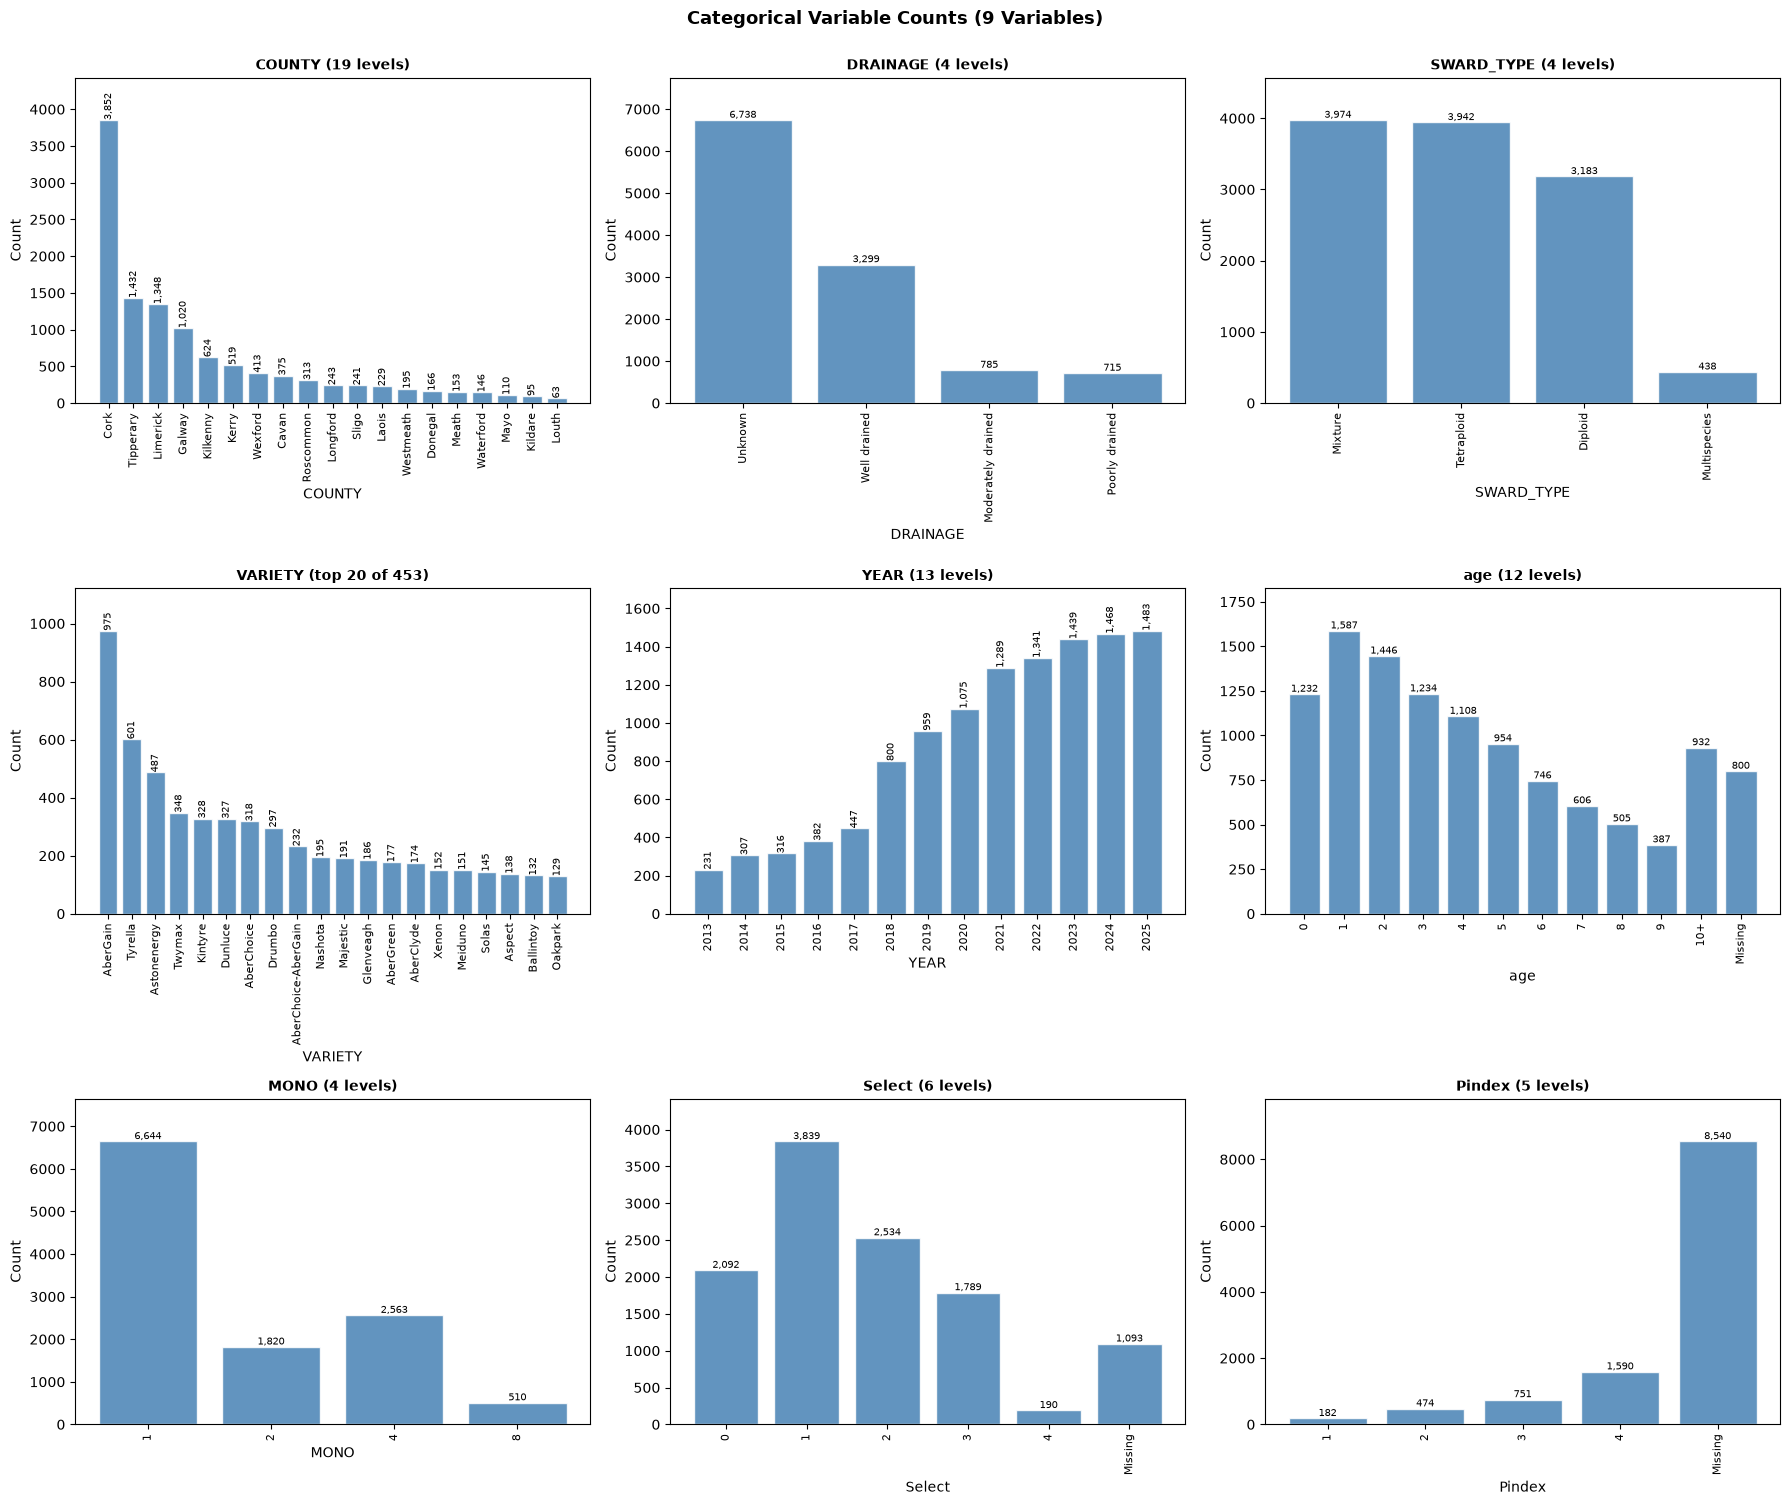

In [31]:
# =============================================================================
# CATEGORICAL VARIABLES: COUNTS
# =============================================================================
section("Categorical variables: counts per level")
# number of records per level, in the same grid style as the histograms
# level can be number of paddocks per County, drainage, sward type and so on
TOP_VARIETIES = 20
cat_cols = ["COUNTY", "DRAINAGE", "SWARD_TYPE", "VARIETY", "YEAR", "age", "MONO", "Select", "Pindex"]
natural_order = {"YEAR", "age", "MONO", "Select", "Pindex"}   # ordered codes keep their order, the rest are sorted by count

def cat_levels(col: str) -> pd.Series:
    # categorical version of a column: missing as its own level, age grouped as 0-9 and 10+, numeric codes as text
    s = df[col]
    if col == "age":
        s = s.clip(upper=10).map(lambda a: "10+" if a == 10 else f"{a:.0f}", na_action="ignore")
    elif s.dtype != "object":
        s = s.map(lambda v: f"{v:.0f}", na_action="ignore")
    return s.fillna("Missing")

def level_order(col: str, levels) -> list:
    # numeric order for ordered codes (Missing last); otherwise as given
    if col not in natural_order:
        return list(levels)
    return sorted(levels, key=lambda v: (v == "Missing", float(v.replace("+", "")) if v != "Missing" else 0))

n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
axes = axes.flatten()
for i, c in enumerate(cat_cols):
    counts = cat_levels(c).value_counts()
    print("\n" + "-" * 80)
    print(f"{c}: {len(counts)} levels" + (f" (top {TOP_VARIETIES} shown)" if c == "VARIETY" else ""))
    shown = counts.head(TOP_VARIETIES) if c == "VARIETY" else counts
    table = pd.DataFrame({"count": shown, "%": (shown / len(df) * 100).round(1)})
    print(table.to_string())

    order = level_order(c, shown.index)
    axes[i].bar(range(len(order)), shown[order].values, color="steelblue", edgecolor="white", alpha=0.85)
    for x, v in enumerate(shown[order].values):
        axes[i].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=7, rotation=90 if len(order) > 12 else 0)
    axes[i].set_xticks(range(len(order)))
    axes[i].set_xticklabels(order, rotation=90, fontsize=8)
    title = f"top {TOP_VARIETIES} of {len(counts)}" if c == "VARIETY" else f"{len(counts)} levels"
    axes[i].set_title(f"{c} ({title})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel(c)
    axes[i].set_ylabel("Count")
    axes[i].set_ylim(0, shown.max() * 1.15)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"Categorical Variable Counts ({len(cat_cols)} Variables)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()


In [32]:
# =============================================================================
# Sward types ?
# =============================================================================
section("Codes that need checking")
# MONO only has 1, 2, 4, 8; Kindex should be 1-4; Select should follow age
 # check the relationship between MONO and SWARD_TYPE, and the age range per Select band
print("MONO vs sward type:")
print(pd.crosstab(df["MONO"], df["SWARD_TYPE"]).to_string())
print("\nExample PRG_Var per MONO code:", df.groupby("MONO")["PRG_Var"].first().to_dict())

print(f"\nKindex values above 4 (should be an index 1-4): {(df['Kindex'] > 4).sum()} | max {df['Kindex'].max()}")
print("\nage range per Select band:")
print(df.groupby("Select")["age"].agg(["min", "max", "count"]).to_string())


Codes that need checking
MONO vs sward type:
SWARD_TYPE  Diploid  Mixture  Multispecies  Tetraploid
MONO                                                  
1              2702        0             0        3942
2                 0     1814             6           0
4               152     2016           395           0
8               329      144            37           0

Example PRG_Var per MONO code: {1: 'Aberbann', 2: 'Magella-Navan (T)', 4: 'AberHerald-Oakpark-Solas (T)', 8: 'Coolfin'}

Kindex values above 4 (should be an index 1-4): 845 | max 410.0

age range per Select band:
         min   max  count
Select                   
0.0      0.0  19.0   2026
1.0      1.0   3.0   3839
2.0      4.0   6.0   2534
3.0      7.0  10.0   1789
4.0     11.0  29.0    190


**Summary:** records are spread unevenly: **Cork has a third of all records (3,852)**, and records grow from 231 in 2013 to about 1,480 in 2024-2025. **Drainage is unknown for 58% of rows** and `Pindex` for 74%, and most of the 453 variety names have only a few records (AberGain 975, Tyrella 601). `MONO` is not a 0/1 flag, so `SWARD_TYPE` is used instead, and `Kindex` (raw potassium values up to 410) and `Select` (missing for ages 11+) are recalculated in feature engineering.


Histograms - all numeric variables


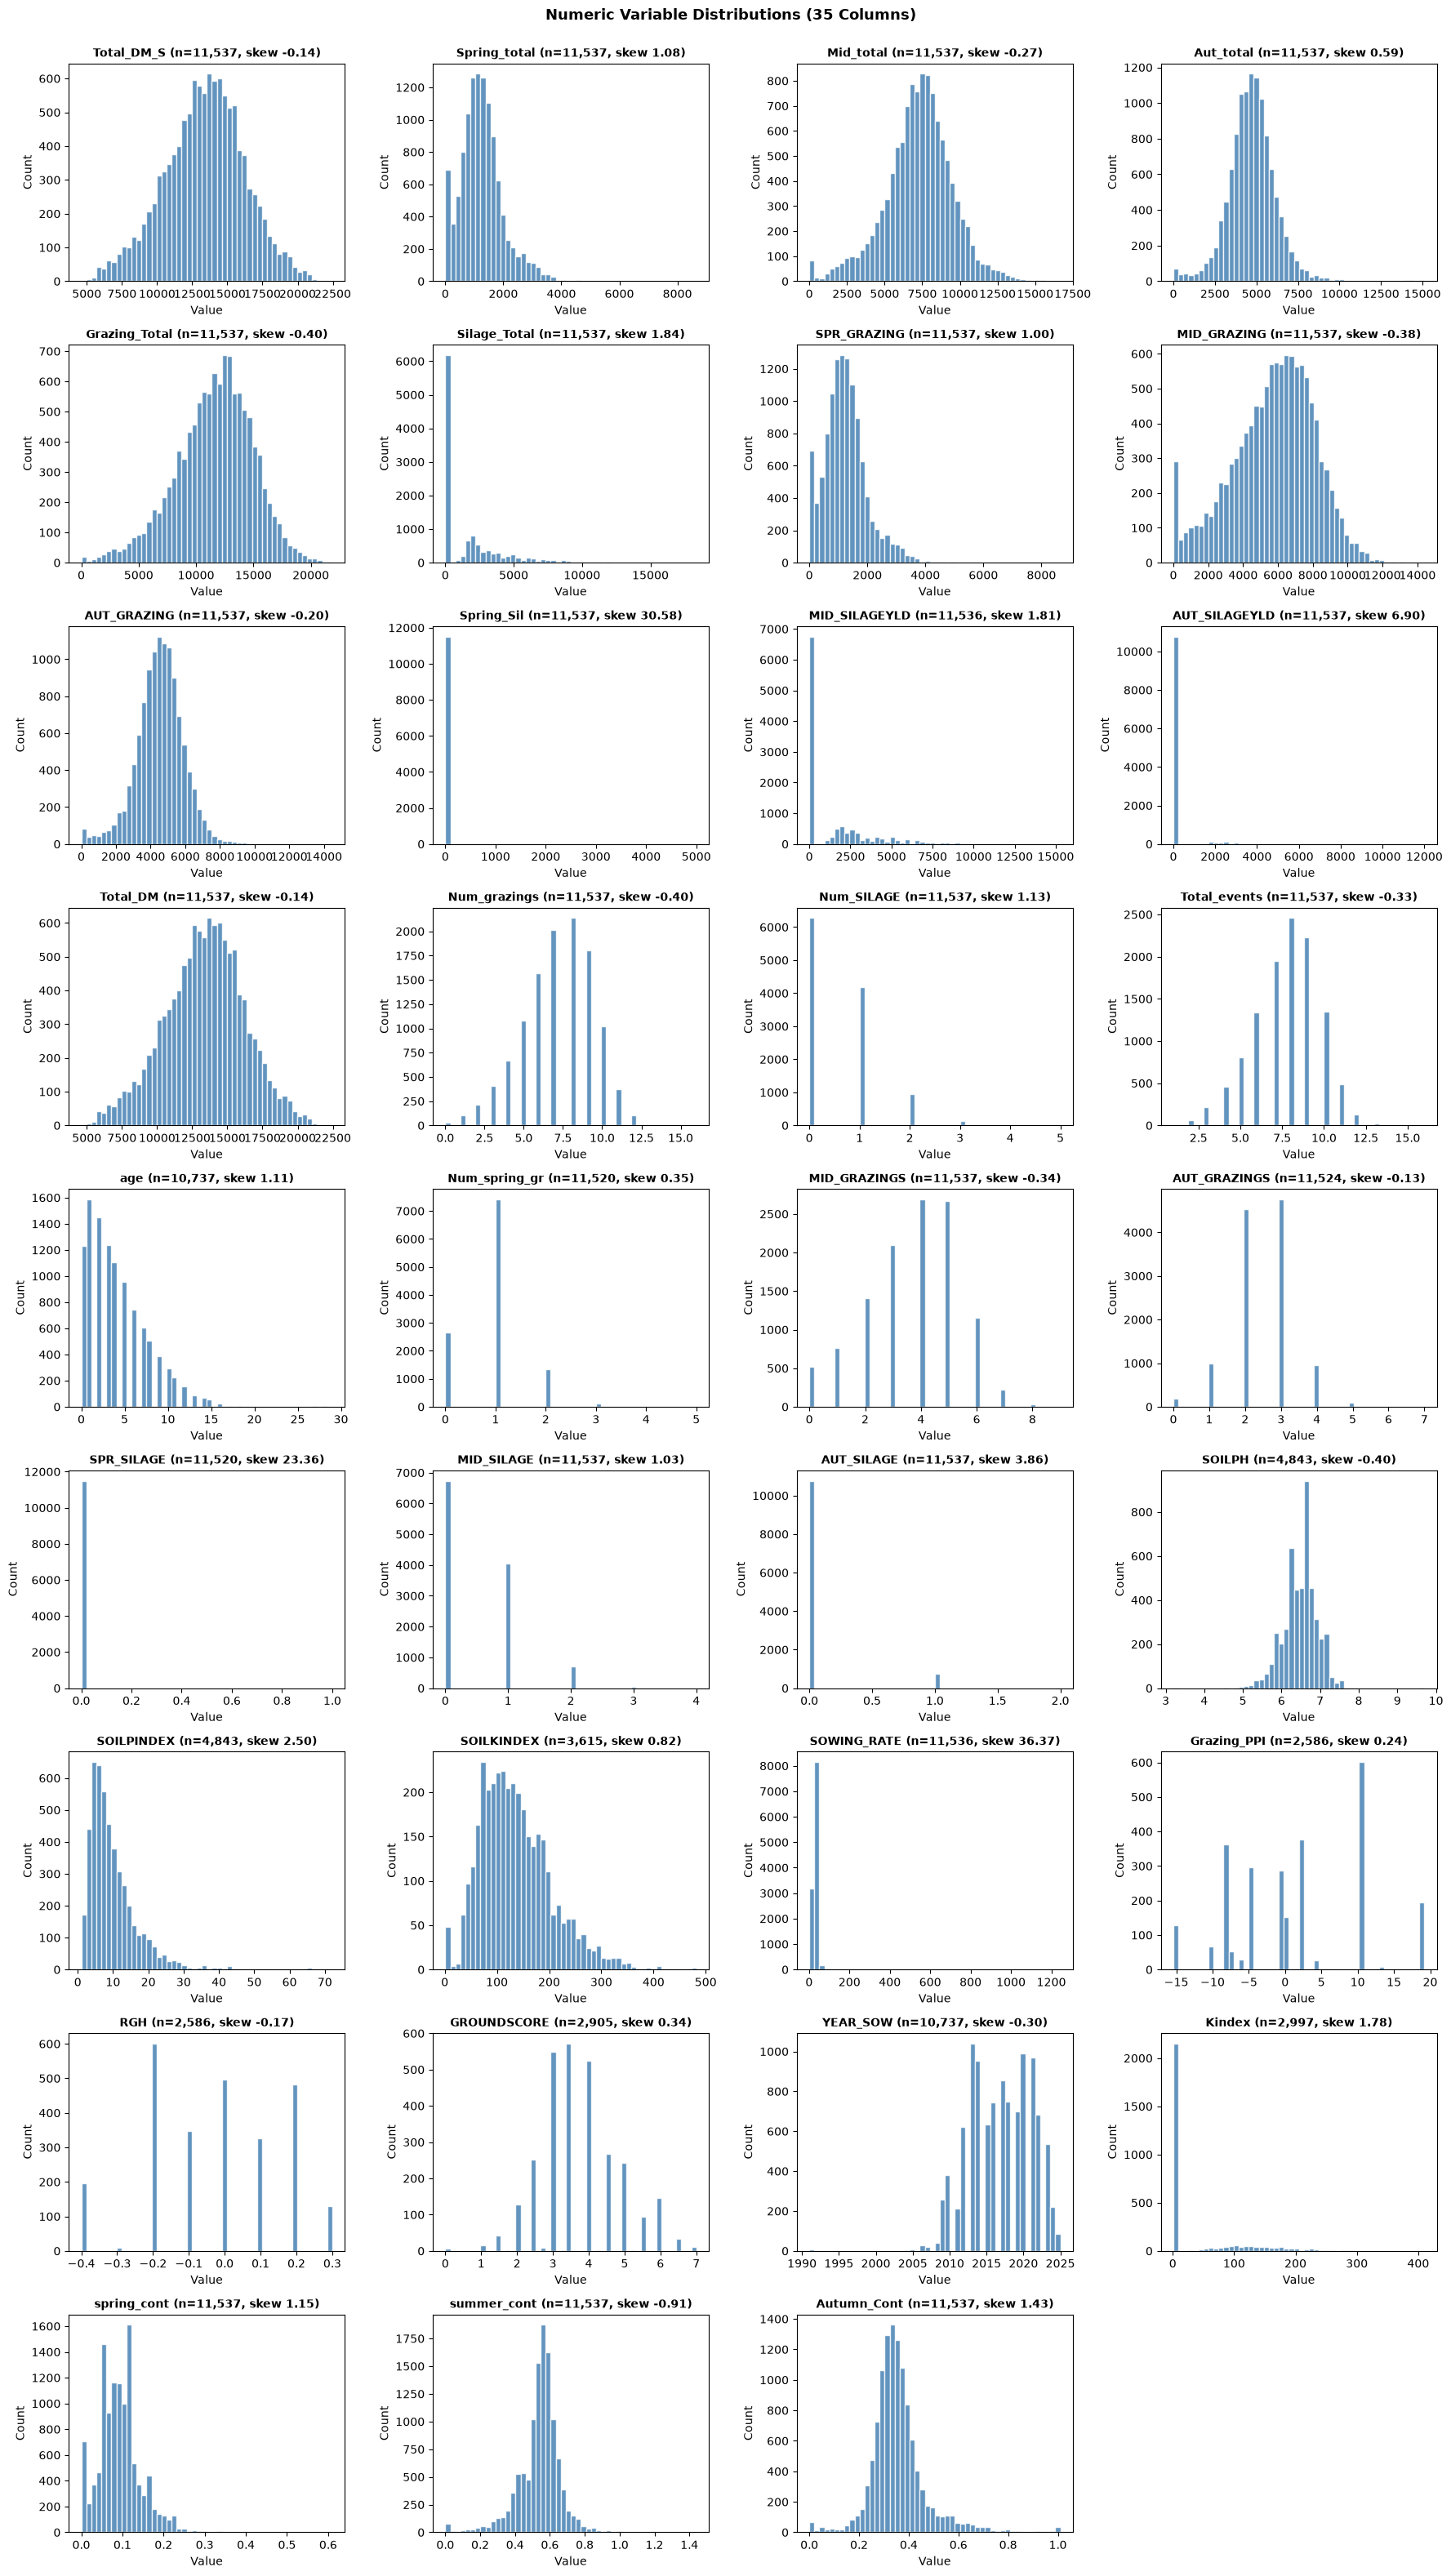

                   n  missing %  zeros %   skew
SOWING_RATE    11536        0.0      0.0  36.37
Spring_Sil     11537        0.0     99.8  30.58
SPR_SILAGE     11520        0.1     99.7  23.36
AUT_SILAGEYLD  11537        0.0     93.4   6.90
AUT_SILAGE     11537        0.0     93.4   3.86
SOILPINDEX      4843       58.0      0.0   2.50
Silage_Total   11537        0.0     53.6   1.84
MID_SILAGEYLD  11536        0.0     58.4   1.81
Kindex          2997       74.0      0.0   1.78
Autumn_Cont    11537        0.0      0.5   1.43
spring_cont    11537        0.0      4.9   1.15
Num_SILAGE     11537        0.0     54.4   1.13
age            10737        6.9     10.7   1.11
Spring_total   11537        0.0      4.6   1.08
MID_SILAGE     11537        0.0     58.4   1.03
SPR_GRAZING    11537        0.0      4.6   1.00
SOILKINDEX      3615       68.7      0.0   0.82
Aut_total      11537        0.0      0.5   0.59
Num_spring_gr  11520        0.1     23.0   0.35
GROUNDSCORE     2905       74.8      0.1

In [33]:
# =============================================================================
# HISTOGRAMS: ALL NUMERIC VARIABLES
# =============================================================================
section("Histograms - all numeric variables")
# one picture with every numeric measurement column, grouped by topic
# (the first lists are also used by the outlier and correlation cells below)
growth_cols = ["Total_DM_S", "Spring_total", "Mid_total", "Aut_total", "Grazing_Total", "Silage_Total"]
event_cols  = ["Num_grazings", "Num_SILAGE", "Total_events", "age"]
soil_cols   = ["SOILPH", "SOILPINDEX", "SOILKINDEX", "SOWING_RATE"]
share_cols  = ["spring_cont", "summer_cont", "Autumn_Cont"]
all_num_cols = growth_cols + event_cols + soil_cols + share_cols

# remaining numeric columns: seasonal parts of grazing and silage, seasonal counts, variety index and other scores
component_cols    = ["SPR_GRAZING", "MID_GRAZING", "AUT_GRAZING", "Spring_Sil", "MID_SILAGEYLD", "AUT_SILAGEYLD", "Total_DM"]
season_event_cols = ["Num_spring_gr", "MID_GRAZINGS", "AUT_GRAZINGS", "SPR_SILAGE", "MID_SILAGE", "AUT_SILAGE"]
other_num_cols    = ["Grazing_PPI", "RGH", "GROUNDSCORE", "YEAR_SOW", "Kindex"]
hist_cols = growth_cols + component_cols + event_cols + season_event_cols + soil_cols + other_num_cols + share_cols
# not plotted here: identifiers (Farm_number, PADDOCK) and codes shown as categories in the boxplots below (YEAR, MONO, Select, Pindex)

n_cols = 4
n_rows = int(np.ceil(len(hist_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(hist_cols):
    values = df[col].dropna()
    axes[i].hist(values, bins=50, color="steelblue", edgecolor="white", alpha=0.85)
    axes[i].set_title(f"{col} (n={len(values):,}, skew {values.skew():.2f})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Count")
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"Numeric Variable Distributions ({len(hist_cols)} Columns)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "19_all_numeric_histograms")
plt.show()

skew_table = pd.DataFrame({"n": df[hist_cols].notna().sum(), "missing %": df[hist_cols].isna().mean().mul(100).round(1),
                           "zeros %": df[hist_cols].eq(0).mean().mul(100).round(1), "skew": df[hist_cols].skew().round(2)})
print(skew_table.sort_values("skew", ascending=False).to_string())


**Summary:** `Total_DM_S`, `Mid_total`, `Aut_total` and `Grazing_Total` are close to normal, while `Spring_total`, `SOILPINDEX` (skew 2.5), sward age and the seasonal shares are right-skewed. **Silage columns are mostly zero** (no silage in 54% of paddock-years). `SOWING_RATE` has impossible values up to 1,245 kg/ha (skew 36) and `Kindex` mixes the index (1-4) with raw potassium values up to 410; both are handled when the analysis dataset is built.

The same numeric columns as **boxplots**: the box is the middle 50% of values, the red line the median, the whiskers reach 1.5 × the box width, and dots beyond them are outliers by that rule. An outlier here is only a statistical flag, not necessarily an error.


Boxplots - all numeric variables


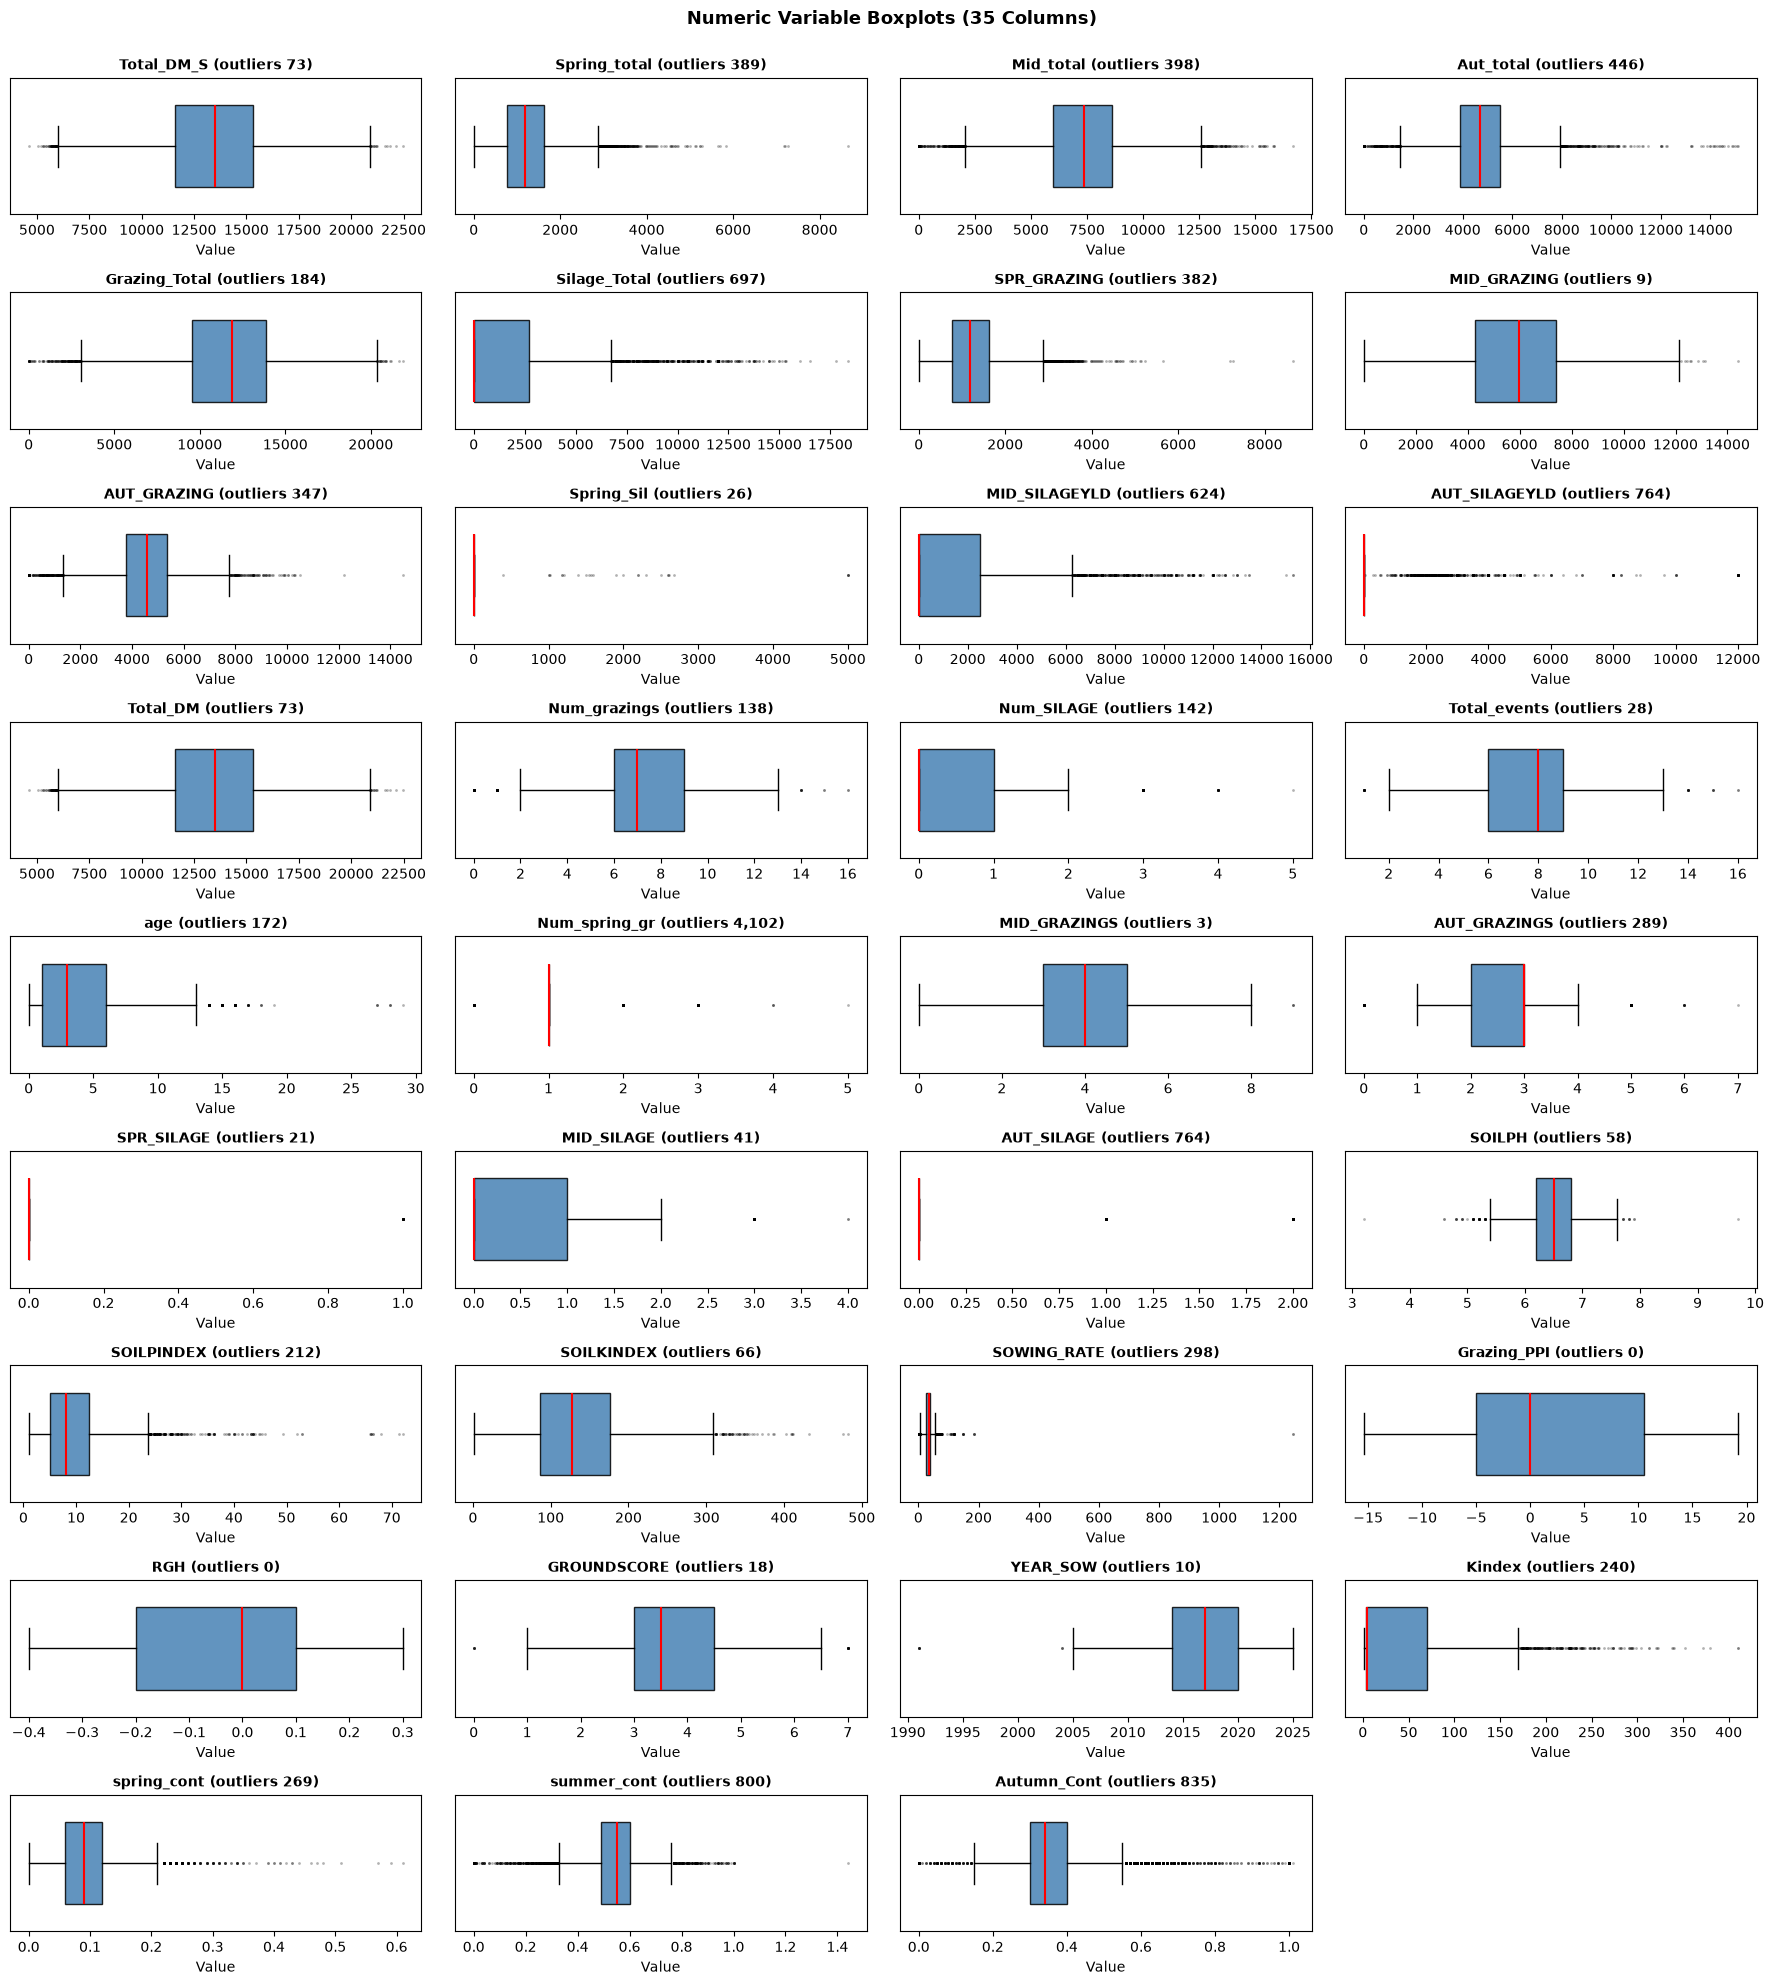

       column     n  median    IQR  outliers  outliers %
Num_spring_gr 11520     1.0    0.0      4102        35.6
       Kindex  2997     4.0   66.9       240         8.0
  Autumn_Cont 11537     0.3    0.1       835         7.2
  summer_cont 11537     0.6    0.1       800         6.9
   AUT_SILAGE 11537     0.0    0.0       764         6.6
AUT_SILAGEYLD 11537     0.0    0.0       764         6.6
 Silage_Total 11537     0.0 2700.0       697         6.0
MID_SILAGEYLD 11536     0.0 2500.0       624         5.4
   SOILPINDEX  4843     8.0    7.4       212         4.4
    Aut_total 11537  4710.0 1617.0       446         3.9
 Spring_total 11537  1186.0  843.0       389         3.4
    Mid_total 11537  7368.0 2628.0       398         3.4
  SPR_GRAZING 11537  1184.0  843.0       382         3.3
  AUT_GRAZING 11537  4573.0 1605.0       347         3.0
  SOWING_RATE 11536    34.6   13.0       298         2.6
 AUT_GRAZINGS 11524     3.0    1.0       289         2.5
  spring_cont 11537     0.1    

In [34]:
# =============================================================================
# BOXPLOTS: ALL NUMERIC VARIABLES
# =============================================================================
section("Boxplots - all numeric variables")
# same columns and grid as the histograms; outliers counted with the 1.5 × IQR rule
n_cols = 4
n_rows = int(np.ceil(len(hist_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 2.2))
axes = axes.flatten()
outlier_rows = []
for i, col in enumerate(hist_cols):
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())
    outlier_rows.append({"column": col, "n": len(values), "median": values.median(), "IQR": iqr,
                         "outliers": n_out, "outliers %": round(n_out / len(values) * 100, 1)})
    axes[i].boxplot(values, vert=False, patch_artist=True, widths=0.6,
                    boxprops=dict(facecolor="steelblue", alpha=0.85, edgecolor="black"),
                    medianprops=dict(color="red", lw=1.5), flierprops=dict(marker=".", markersize=2, alpha=0.3))
    axes[i].set_title(f"{col} (outliers {n_out:,})", fontsize=10, fontweight="bold")
    axes[i].set_yticks([])
    axes[i].set_xlabel("Value")
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"Numeric Variable Boxplots ({len(hist_cols)} Columns)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "20_all_numeric_boxplots")
plt.show()

outlier_table = pd.DataFrame(outlier_rows).sort_values("outliers %", ascending=False)
print(outlier_table.round({"median": 1, "IQR": 1}).to_string(index=False))

**Summary:** the target `Total_DM_S` has few outliers (73, 0.6%), all at the high end and plausible. The silage columns are flagged most because most values are zero, so any real cut counts as outlying. The real data problems are **`SOWING_RATE` up to 1,245 kg/ha**, **`Kindex` mixing index values and raw potassium** and seasonal shares above 1 (`summer_cont` up to 1.45); these are handled when the analysis dataset is built, and the other flagged values are kept.

In [35]:
# =============================================================================
# OUTLIER CHECKS
# =============================================================================
section("Outliers: real or data errors?")
# values outside a realistic range
print(f"SOWING_RATE > 100 kg/ha:    {(df['SOWING_RATE'] > 100).sum()} (max {df['SOWING_RATE'].max()})")
print(f"Seasonal share > 1:         {((df[share_cols] > 1).any(axis=1)).sum()}")
print(f"Total_DM_S < 4,000 kg DM/ha:  {(df[TARGET] < 4000).sum()}")
print(f"Total_DM_S > 20,000 kg DM/ha: {(df[TARGET] > 20000).sum()}")

season_sum = df[["Spring_total", "Mid_total", "Aut_total"]].sum(axis=1)
print(f"\nSeasons add up exactly to Total_DM_S: {(season_sum.round() == df[TARGET].round()).mean():.1%}")
print(f"Median Total_DM_S - season sum: {(df[TARGET] - season_sum).median():.0f} kg DM/ha (growth outside the three seasons)")

df[(df[TARGET] < 4000) | (df[TARGET] > 20000)][["Farm_number", "YEAR", "age", "VARIETY", "COUNTY", "Num_grazings", "Total_DM", "Total_DM_S"]]


Outliers: real or data errors?
SOWING_RATE > 100 kg/ha:    34 (max 1244.6)
Seasonal share > 1:         2
Total_DM_S < 4,000 kg DM/ha:  0
Total_DM_S > 20,000 kg DM/ha: 89

Seasons add up exactly to Total_DM_S: 2.7%
Median Total_DM_S - season sum: 120 kg DM/ha (growth outside the three seasons)


,Farm_number,YEAR,age,VARIETY,COUNTY,Num_grazings,Total_DM,Total_DM_S
102,F033,2014,2.0,AberChoice,Laois,10.0,20500.0,20500.0
107,F099,2015,3.0,AberChoice,Cork,6.0,20002.0,20002.0
194,F099,2014,2.0,AberChoice,Cork,8.0,20893.0,20893.0
205,F098,2017,2.0,AberChoice,Longford,10.0,21197.0,21197.0
217,F037,2019,4.0,AberChoice,Galway,3.0,21215.0,21215.0
...,...,...,...,...,...,...,...,...
10507,F037,2025,1.0,Astonconqueror-Astonenergy-Captain Plantain-Ch...,Galway,10.0,21866.0,21866.0
10813,F002,2025,3.0,AberClyde-Astonenergy,Limerick,4.0,22463.0,22463.0
10814,F002,2025,3.0,AberClyde-Astonenergy,Limerick,5.0,22149.0,22149.0
10981,F082,2025,2.0,AberChoice-Astonenergy-Chieftian-Crusader-Glen...,Longford,6.0,20772.0,20772.0


**Summary:** 34 sowing rates above 100 kg/ha (max 1,244.6) are entry errors and are set to missing when the analysis dataset is built. After the typing-error fix no `Total_DM_S` is below 4,000 kg DM/ha (lowest 4,608), and the 89 yields above 20 t come from many farms and years and look real. The seasons add up exactly to `Total_DM_S` in only 2% of rows (median gap 120 kg DM/ha), because some growth falls outside the three season windows.

### Univariate view of the main variables

The grids above hold every numeric column. The charts below show only the main variables: the target `Total_DM_S`, its parts, the main predictors and the main categories, each with a summary table. Last year's growth (`PREV_YEAR_DM`) is the `Total_DM_S` of the same paddock and the same sowing in the year before. Sowing rates above 100 kg/ha and soil pH outside 4.5-8.5 are left out of these charts and tables only; the data itself is not changed.


Main numeric variables: histograms, boxplots and summary table


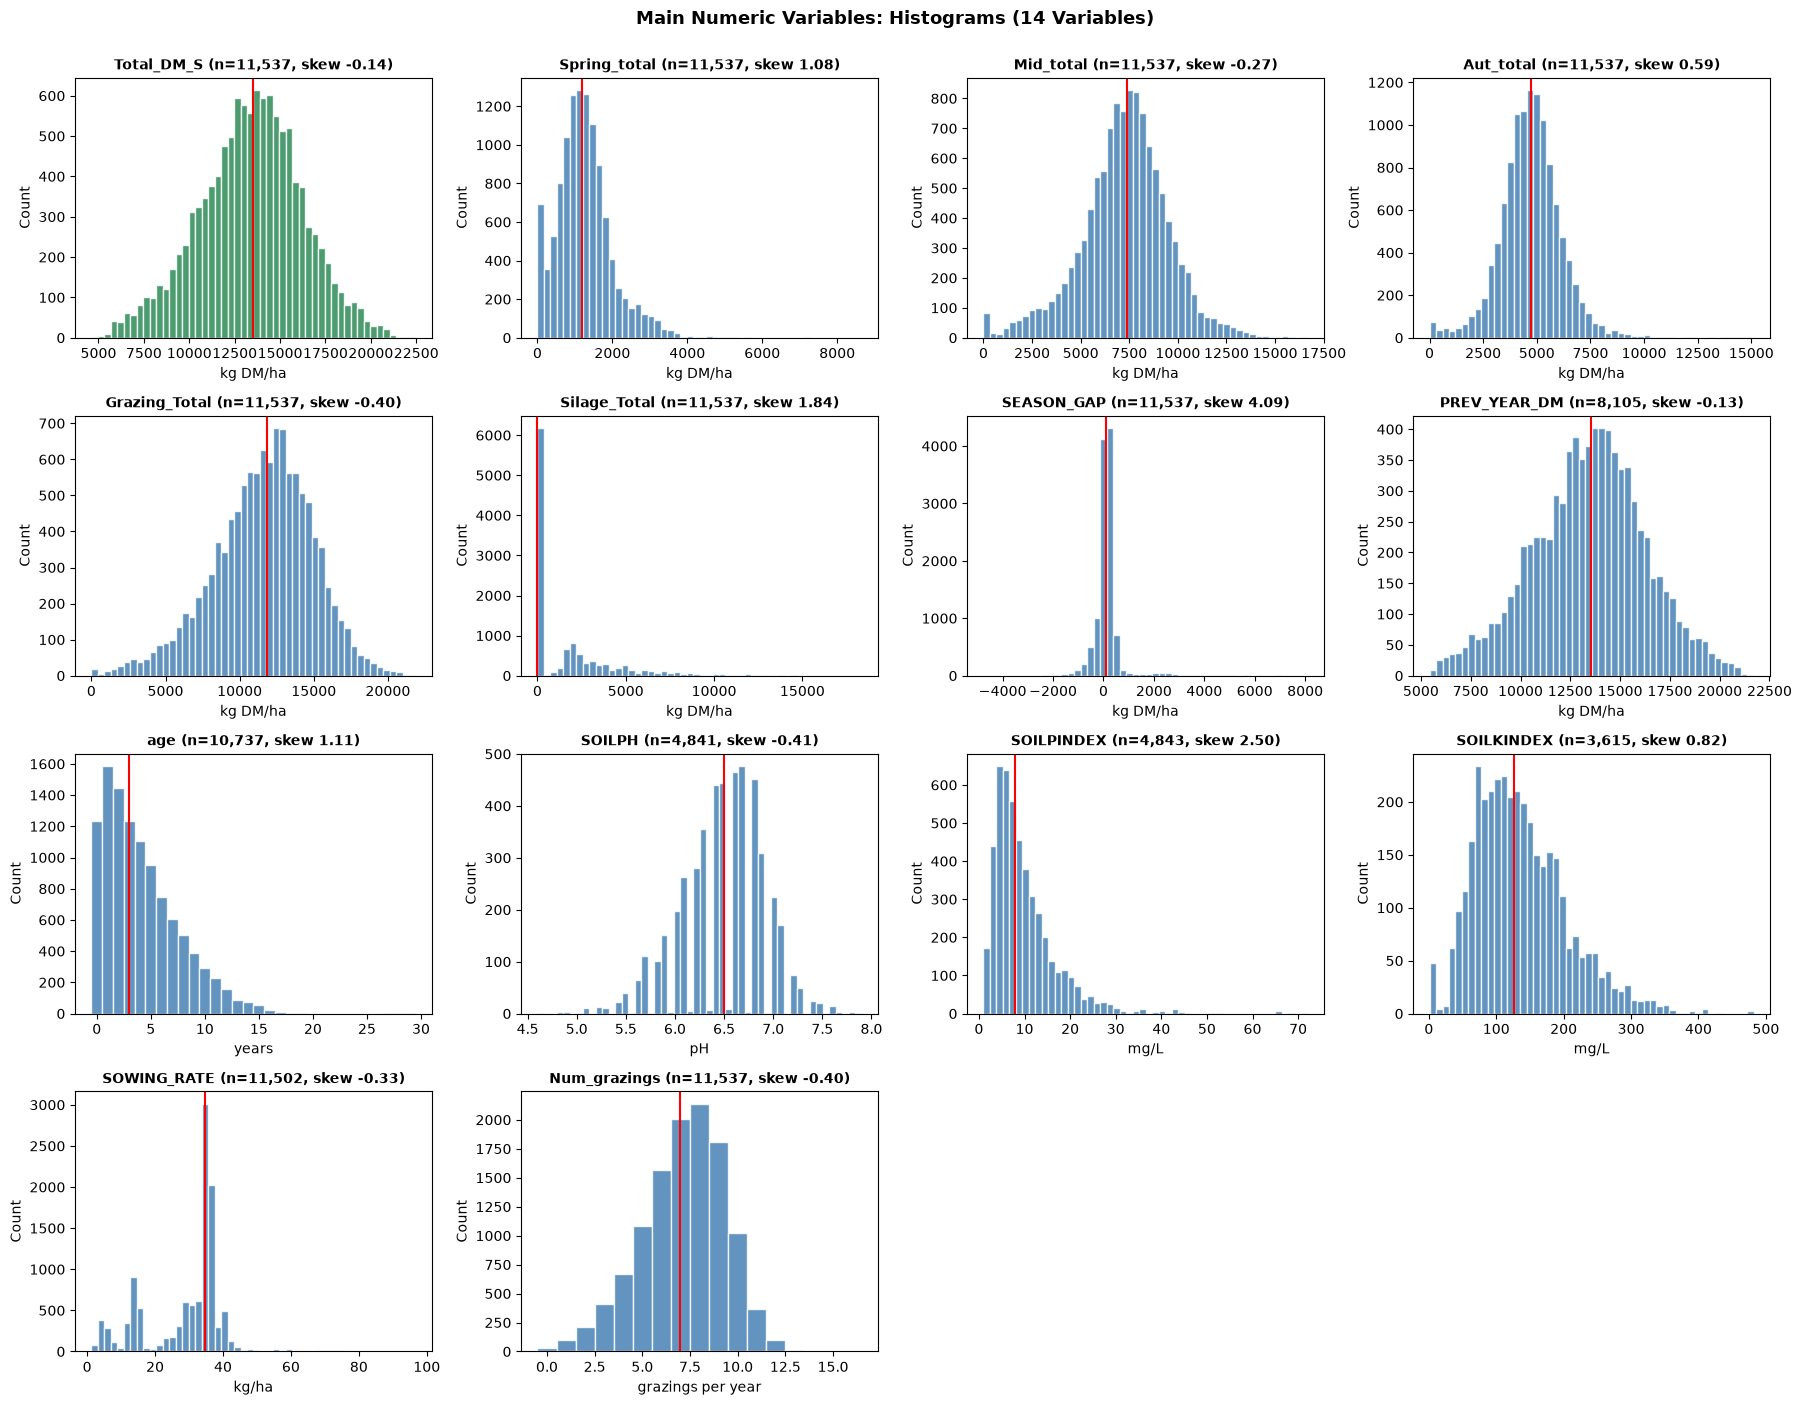

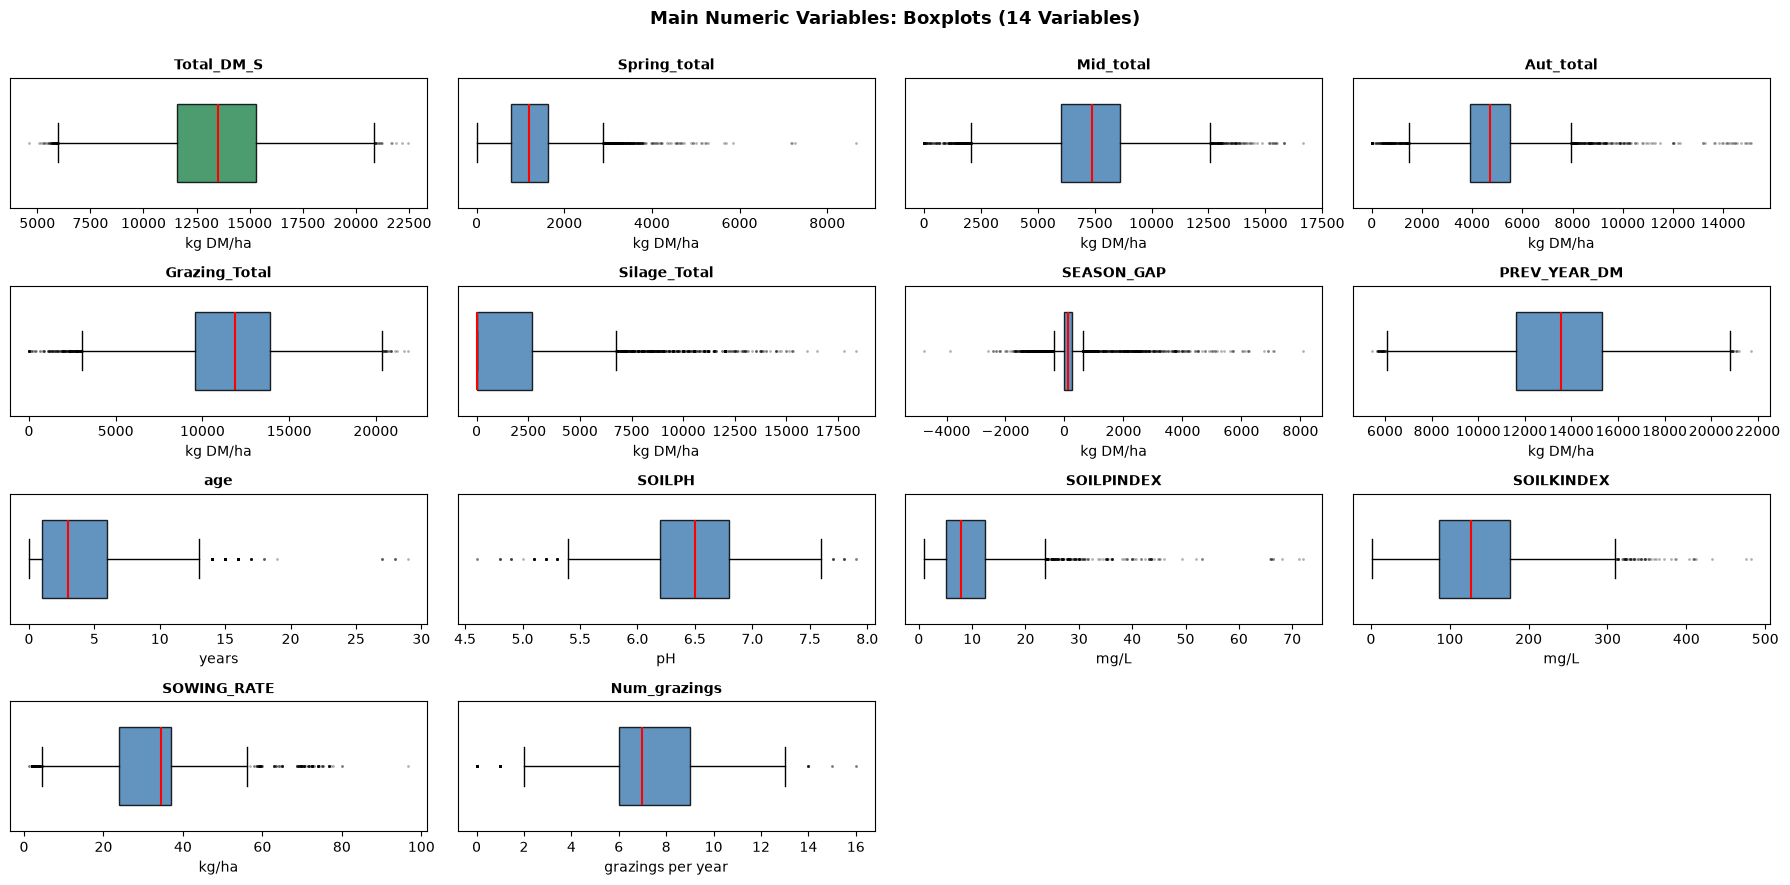

                            unit      n missing %     mean   median      SD     min      max  skew left out
Total_DM_S              kg DM/ha  11537       0.0  13380.7  13504.0  2831.9  4608.0  22463.0 -0.14        0
Spring_total            kg DM/ha  11537       0.0   1251.8   1186.0   740.0     0.0   8652.0  1.08        0
Mid_total               kg DM/ha  11537       0.0   7255.9   7368.0  2243.7     0.0  16677.0 -0.27        0
Aut_total               kg DM/ha  11537       0.0   4730.8   4710.0  1468.8     0.0  15113.0  0.59        0
Grazing_Total           kg DM/ha  11537       0.0  11590.4  11867.0  3331.7     0.0  21866.0  -0.4        0
Silage_Total            kg DM/ha  11537       0.0   1790.2      0.0  2596.9     0.0  18355.0  1.84        0
SEASON_GAP              kg DM/ha  11537       0.0    142.2    120.0   592.6 -4758.0   8100.0  4.09        0
PREV_YEAR_DM            kg DM/ha   8105      29.7  13427.1  13557.0  2824.8  5433.0  21710.0 -0.13        0
age                        y

In [36]:
# =============================================================================
# UNIVARIATE: MAIN NUMERIC VARIABLES
# =============================================================================
section("Main numeric variables: histograms, boxplots and summary table")
# copy for charts and tables only: last year's growth added, implausible values set to missing
def chart_inputs(data: pd.DataFrame) -> pd.DataFrame:
    out = data.sort_values(["PADDOCK", "YEAR"]).copy()
    prev = out.groupby(["PADDOCK", "YEAR_SOW"])[[TARGET, "YEAR"]].shift(1)
    out["PREV_YEAR_DM"] = prev[TARGET].where(prev["YEAR"] == out["YEAR"] - 1)
    out.loc[out["SOWING_RATE"] > 100, "SOWING_RATE"] = np.nan        # entry errors, chart only
    out.loc[~out["SOILPH"].between(4.5, 8.5), "SOILPH"] = np.nan     # implausible pH values, chart only
    return out

uni = chart_inputs(df)
uni_vars = {TARGET: "kg DM/ha", "Spring_total": "kg DM/ha", "Mid_total": "kg DM/ha", "Aut_total": "kg DM/ha",
            "Grazing_Total": "kg DM/ha", "Silage_Total": "kg DM/ha", "SEASON_GAP": "kg DM/ha", "PREV_YEAR_DM": "kg DM/ha",
            "age": "years", "SOILPH": "pH", "SOILPINDEX": "mg/L", "SOILKINDEX": "mg/L", "SOWING_RATE": "kg/ha", "Num_grazings": "grazings per year"}
whole_numbers = {"age", "Num_grazings"}   # one bar per value

# histograms; the red line is the median
n_cols = 4
n_rows = int(np.ceil(len(uni_vars) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.5))
axes = axes.flatten()
for i, (col, unit) in enumerate(uni_vars.items()):
    values = uni[col].dropna()
    bins = np.arange(values.min() - 0.5, values.max() + 1.5) if col in whole_numbers else 50
    axes[i].hist(values, bins=bins, color="seagreen" if col == TARGET else "steelblue", edgecolor="white", alpha=0.85)
    axes[i].axvline(values.median(), color="red", lw=1.5)
    axes[i].set_title(f"{col} (n={len(values):,}, skew {values.skew():.2f})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel(unit)
    axes[i].set_ylabel("Count")
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle(f"Main Numeric Variables: Histograms ({len(uni_vars)} Variables)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "16_univariate_numeric_histograms")
plt.show()

# boxplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 2.2))
axes = axes.flatten()
for i, (col, unit) in enumerate(uni_vars.items()):
    axes[i].boxplot(uni[col].dropna(), vert=False, patch_artist=True, widths=0.6,
                    boxprops=dict(facecolor="seagreen" if col == TARGET else "steelblue", alpha=0.85, edgecolor="black"),
                    medianprops=dict(color="red", lw=1.5), flierprops=dict(marker=".", markersize=2, alpha=0.3))
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].set_yticks([])
    axes[i].set_xlabel(unit)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle(f"Main Numeric Variables: Boxplots ({len(uni_vars)} Variables)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "17_univariate_numeric_boxplots")
plt.show()

# summary table; "left out" = values not used in the charts and in this table
numeric_summary = pd.DataFrame({col: {"unit": unit, "n": uni[col].notna().sum(), "missing %": round(uni[col].isna().mean() * 100, 1),
                                      "mean": round(uni[col].mean(), 1), "median": round(uni[col].median(), 1), "SD": round(uni[col].std(), 1),
                                      "min": uni[col].min(), "max": uni[col].max(), "skew": round(uni[col].skew(), 2),
                                      "left out": int(df[col].notna().sum() - uni[col].notna().sum()) if col in df else 0}
                                for col, unit in uni_vars.items()}).T
print(numeric_summary.to_string())
numeric_summary.to_csv(FIG_DIR / "univariate_numeric_summary.csv", index_label="variable")

**Summary:** `Total_DM_S` is close to normal (mean 13,381 kg DM/ha, median 13,504, SD 2,832, skew −0.14), and last year's growth has almost the same shape (skew −0.13, available for 8,105 rows). Mid-season is the largest part of the year (median 7,368 kg DM/ha), ahead of autumn (4,710) and spring (1,186), and 54% of paddock-years have no silage. Soil values are missing in 58-69% of rows, and soil P is the most skewed predictor (skew 2.50). With 34 entry errors left out, sowing rate has two peaks, at about 15 and 35 kg/ha, which may reflect over-sowing and full reseeding.


Main categorical variables: counts and summary tables
--------------------------------------------------------------------------------
YEAR: 13 categories
      paddock-years     %  farms
YEAR                            
2013            231   2.0     52
2014            307   2.7     60
2015            316   2.7     62
2016            382   3.3     75
2017            447   3.9     69
2018            800   6.9     63
2019            959   8.3     83
2020           1075   9.3     90
2021           1289  11.2     92
2022           1341  11.6     88
2023           1439  12.5     91
2024           1468  12.7     84
2025           1483  12.9     86
--------------------------------------------------------------------------------
COUNTY: 19 categories
           paddock-years     %  farms
COUNTY                               
Cork                3852  33.4     34
Tipperary           1432  12.4     12
Limerick            1348  11.7     11
Galway              1020   8.8     10
Kilkenny          

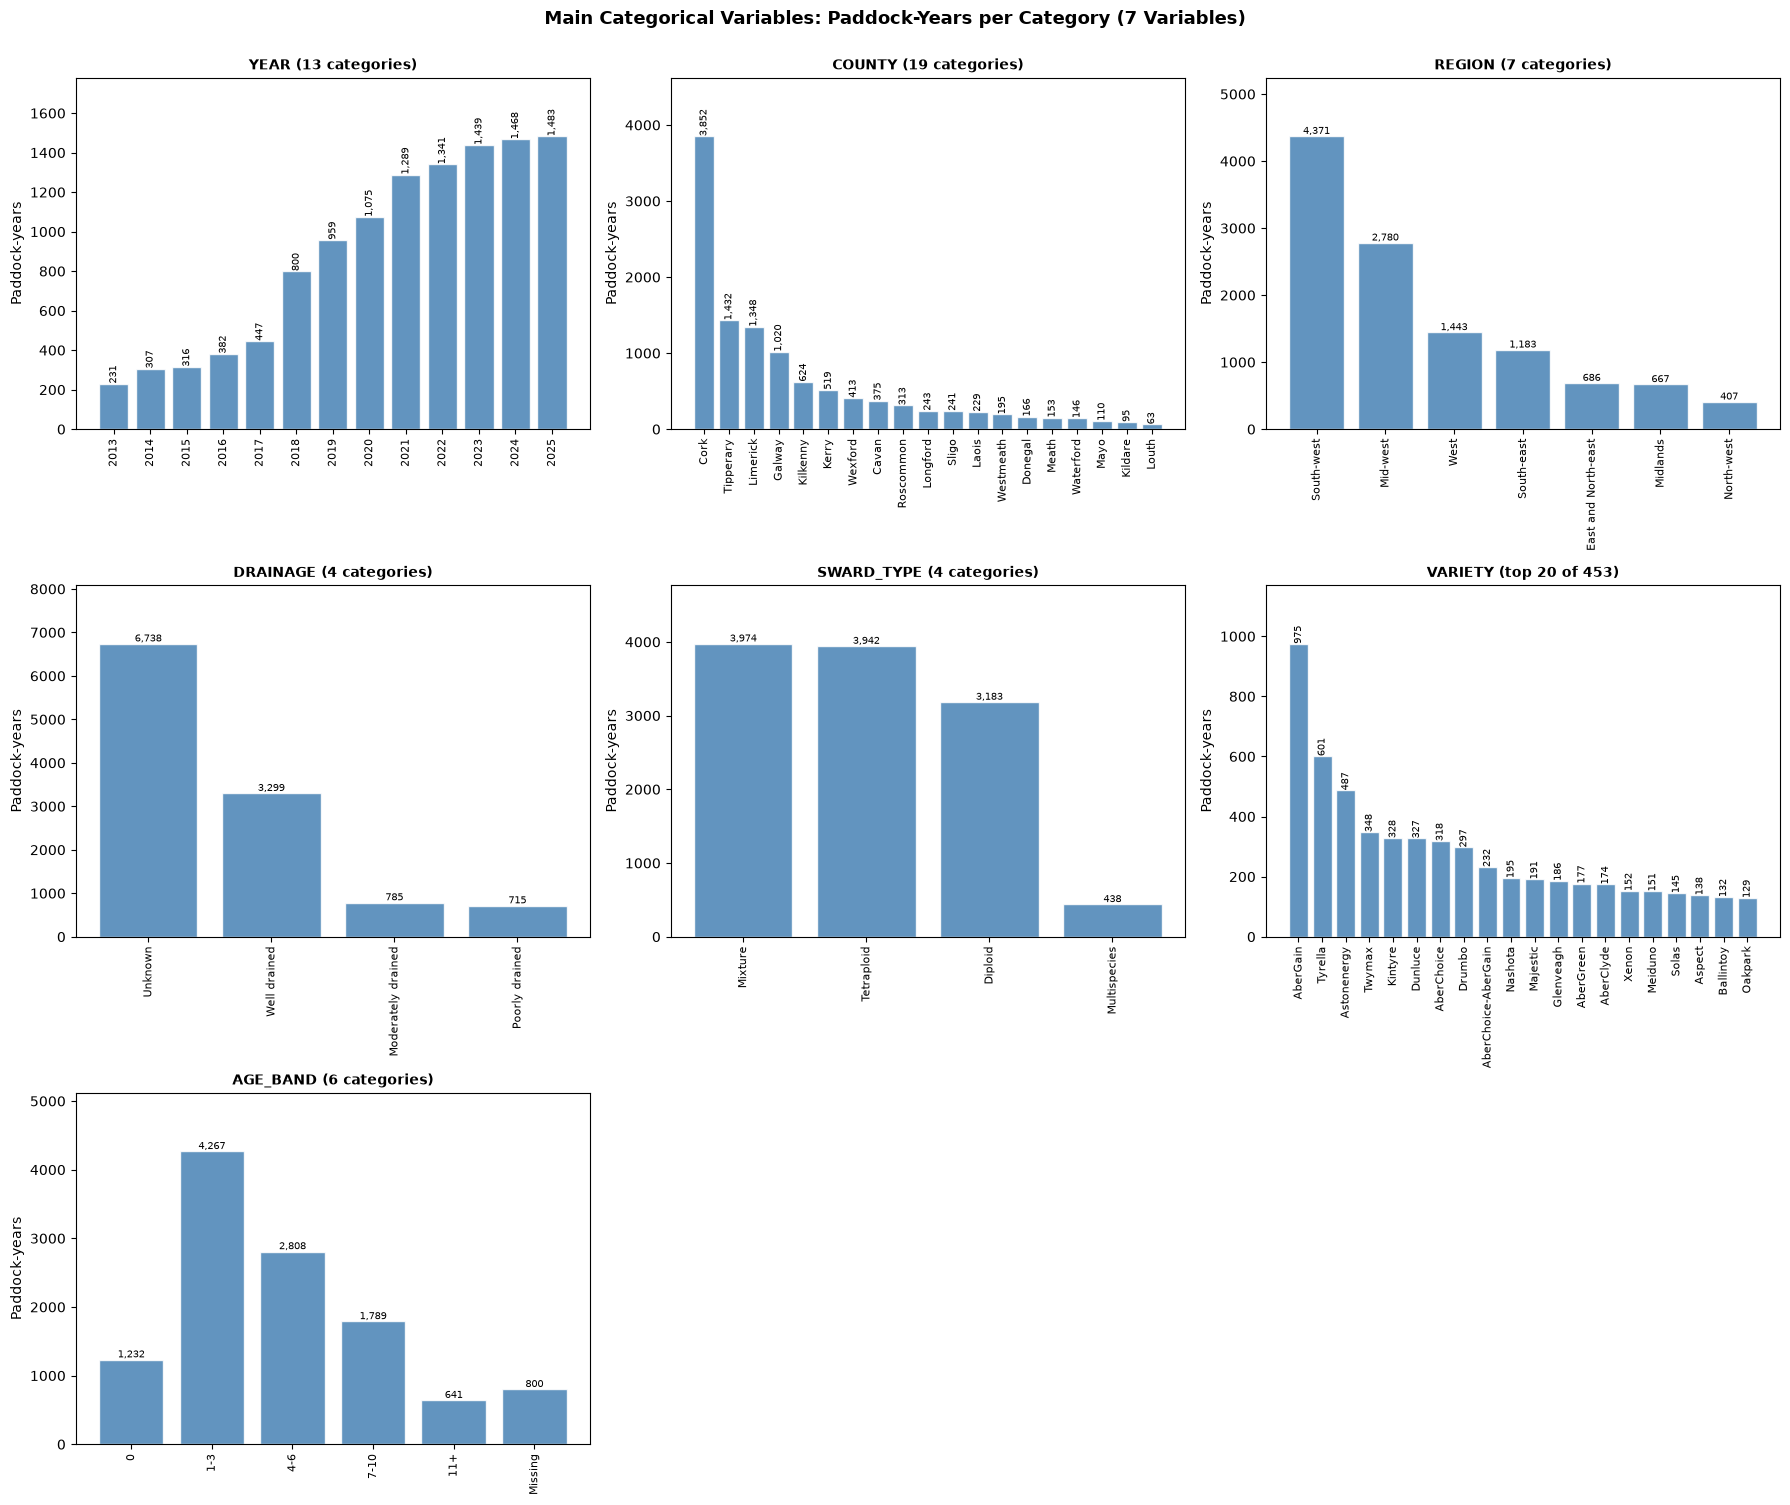

In [37]:
# =============================================================================
# UNIVARIATE: MAIN CATEGORICAL VARIABLES
# =============================================================================
section("Main categorical variables: counts and summary tables")
# paddock-years and farms per category; year and sward age band keep their order, the others are sorted by count
AGE_BANDS = dict(bins=[-1, 0, 3, 6, 10, np.inf], labels=["0", "1-3", "4-6", "7-10", "11+"])
uni["AGE_BAND"] = pd.cut(uni["age"], **AGE_BANDS).astype(object)
uni_cats = ["YEAR", "COUNTY", "REGION", "DRAINAGE", "SWARD_TYPE", "VARIETY", "AGE_BAND"]
ordered_cats = {"YEAR": sorted(uni["YEAR"].unique()), "AGE_BAND": AGE_BANDS["labels"] + ["Missing"]}
TOP_VARIETIES = 20

n_cols = 3
n_rows = int(np.ceil(len(uni_cats) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
axes = axes.flatten()
category_tables = []
for i, c in enumerate(uni_cats):
    level = uni[c].where(uni[c].notna(), "Missing")
    table = pd.DataFrame({"paddock-years": level.value_counts()})
    table["%"] = (table["paddock-years"] / len(uni) * 100).round(1)
    table["farms"] = uni.groupby(level)["Farm_number"].nunique()
    n_levels = len(table)
    if c in ordered_cats:
        table = table.reindex([v for v in ordered_cats[c] if v in table.index])
    if c == "VARIETY":
        table = table.head(TOP_VARIETIES)
    print("-" * 80)
    print(f"{c}: {n_levels} categories" + (f" (top {TOP_VARIETIES} shown)" if c == "VARIETY" else ""))
    print(table.to_string())
    category_tables.append(table.rename_axis("category").reset_index().assign(variable=c))

    x = range(len(table))
    axes[i].bar(x, table["paddock-years"], color="steelblue", edgecolor="white", alpha=0.85)
    for k, v in enumerate(table["paddock-years"]):
        axes[i].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=7, rotation=90 if len(table) > 12 else 0)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(table.index, rotation=90, fontsize=8)
    shown = f"top {TOP_VARIETIES} of {n_levels}" if c == "VARIETY" else f"{n_levels} categories"
    axes[i].set_title(f"{c} ({shown})", fontsize=10, fontweight="bold")
    axes[i].set_ylabel("Paddock-years")
    axes[i].set_ylim(0, table["paddock-years"].max() * 1.2)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle(f"Main Categorical Variables: Paddock-Years per Category ({len(uni_cats)} Variables)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "18_univariate_categorical_counts")
plt.show()

pd.concat(category_tables)[["variable", "category", "paddock-years", "%", "farms"]].to_csv(FIG_DIR / "univariate_categorical_counts.csv", index=False)

**Summary:** paddock-years are spread unevenly. They rise from 231 in 2013 to 1,483 in 2025, Cork alone holds 33.4% (34 farms), and the North-west only 3.5% (7 farms). Drainage is unknown for 58.4% of paddock-years. Ryegrass mixtures (34.4%) and tetraploids (34.2%) are the largest sward types, ahead of diploids (27.6%) and multispecies swards (3.8%). AberGain is the most common variety (975 paddock-years, 92 farms). The most common age band is 1-3 years (37.0%), and 800 paddock-years (6.9%, 22 farms) have no sowing year.

**`Total_DM_S` by categorical variable.** The box is the middle 50% of paddock-years, the red line the median and the red dashed line the overall mean. Levels are ordered by median, except variables with a natural order (year, sward age, codes); only the 15 most common variety names are shown.


Boxplots - Total_DM_S by categorical variable


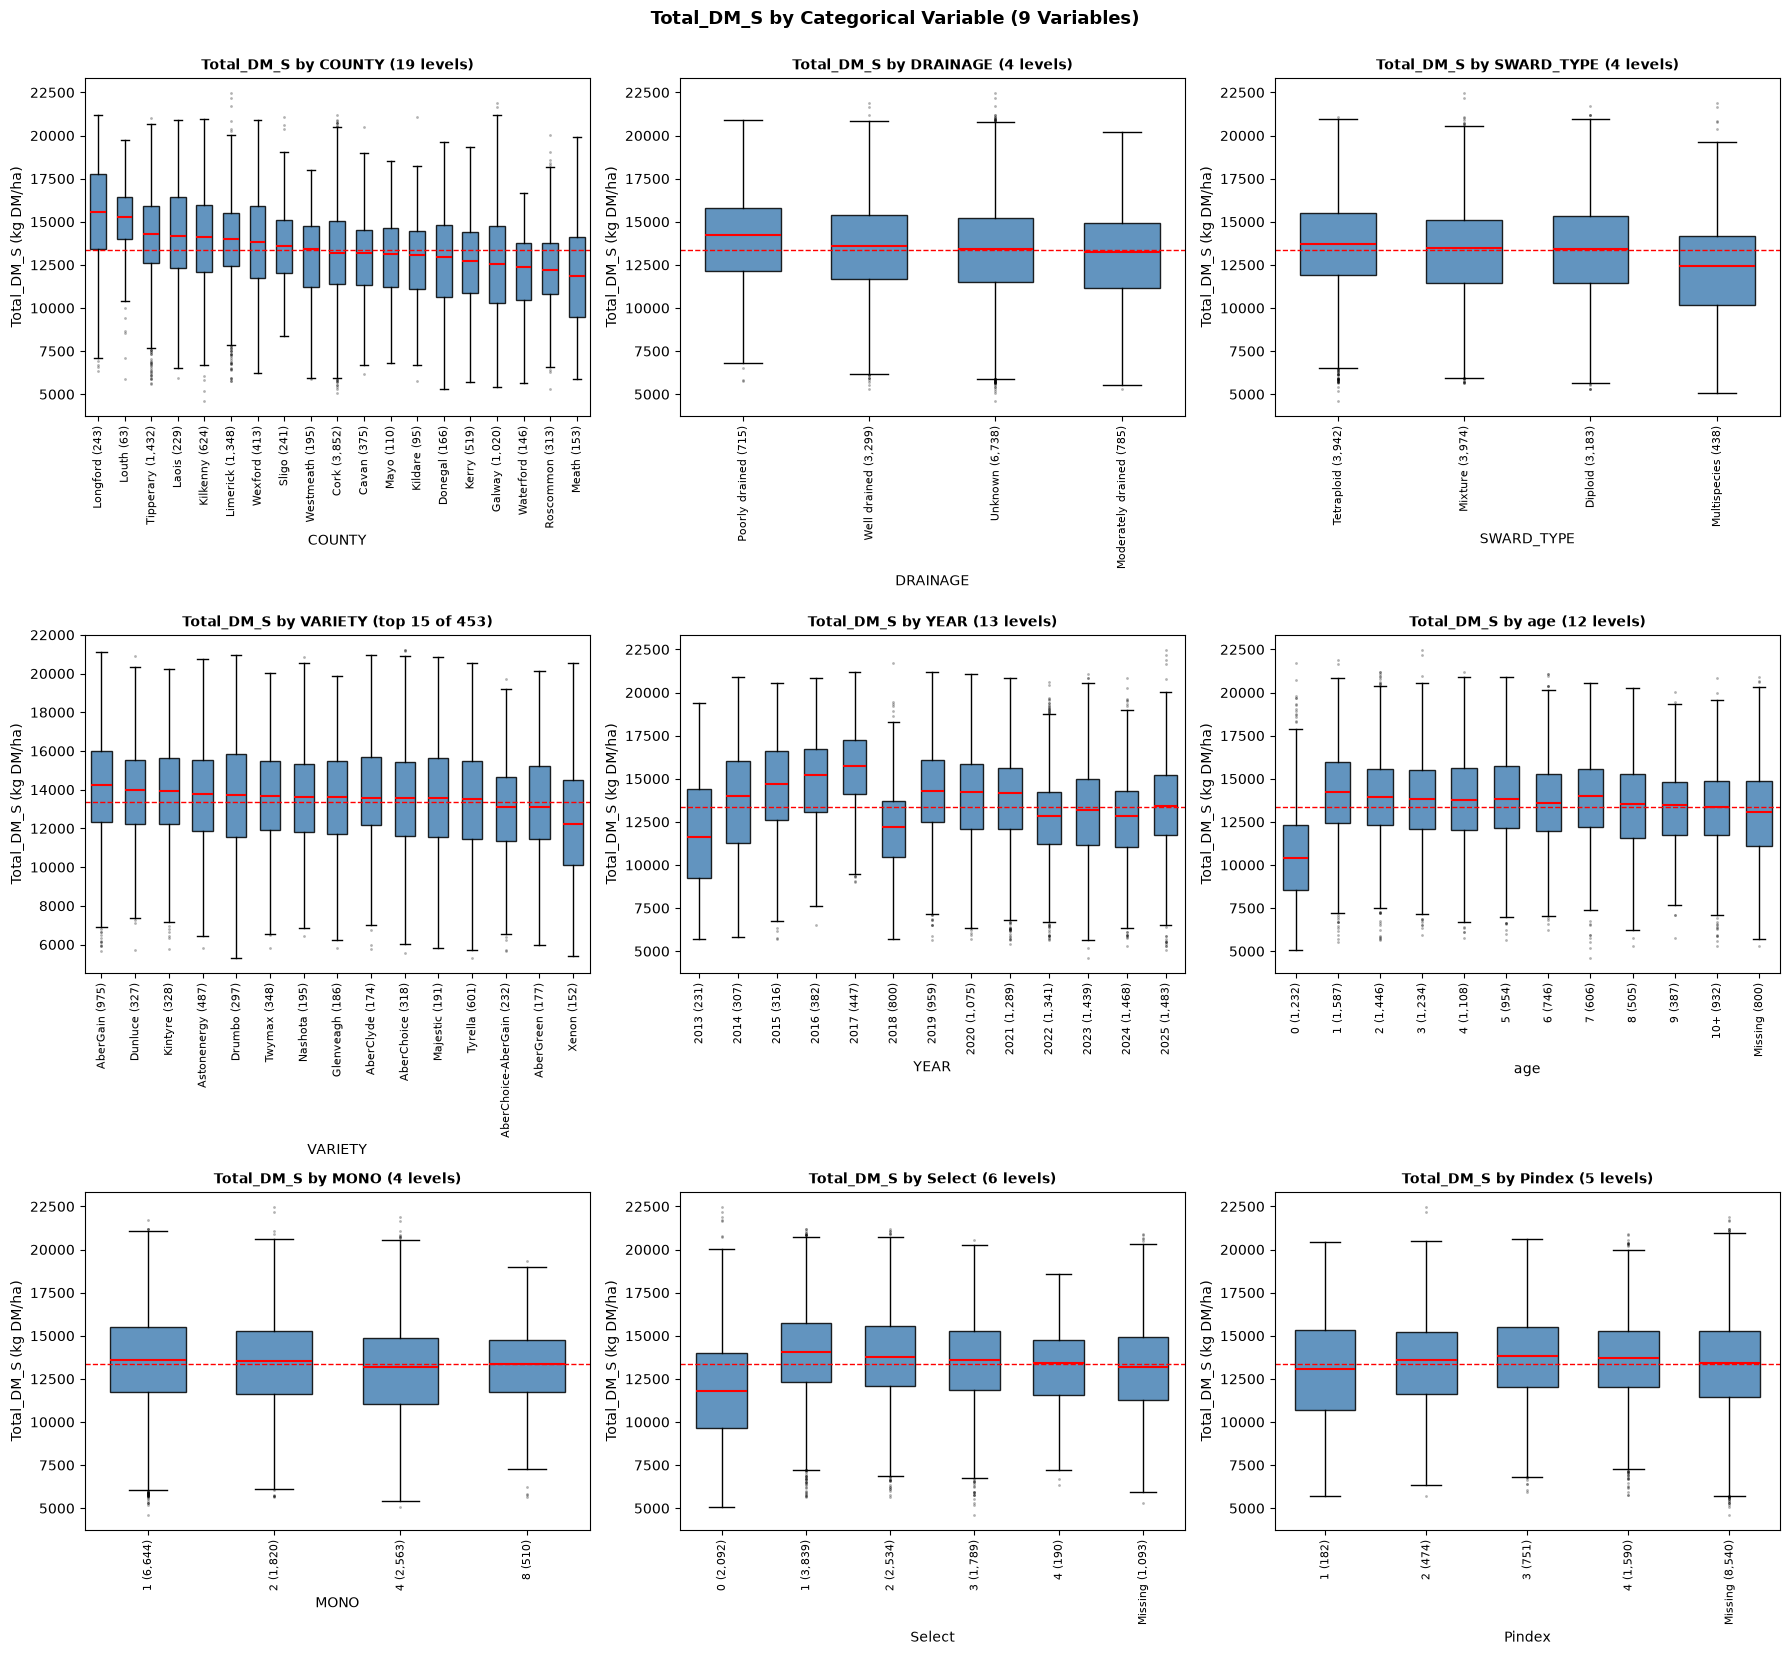

  variable  levels  shown  smallest level (records)          highest median               lowest median  median range (kg DM/ha)
    COUNTY      19     19                        63       Longford (15,588)              Meath (11,870)                     3718
  DRAINAGE       4      4                       715 Poorly drained (14,237) Moderately drained (13,268)                      969
SWARD_TYPE       4      4                       438     Tetraploid (13,736)       Multispecies (12,420)                     1316
   VARIETY     453     15                       152       AberGain (14,219)              Xenon (12,233)                     1986
      YEAR      13     13                       231           2017 (15,721)               2013 (11,617)                     4104
       age      12     12                       387              1 (14,209)                  0 (10,405)                     3804
      MONO       4      4                       510              1 (13,611)                  4 (1

In [38]:
# =============================================================================
# BOXPLOTS: TOTAL_DM BY CATEGORICAL VARIABLE
# =============================================================================
section("Boxplots - Total_DM_S by categorical variable")
# same grid style as the histograms; one panel per categorical variable
TOP_BOX_VARIETIES = 15
box_vars = cat_cols   # same variables as the counts grid

n_cols = 3
n_rows = int(np.ceil(len(box_vars) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5.5))
axes = axes.flatten()
box_summary = []

for i, col in enumerate(box_vars):
    levels = cat_levels(col)
    counts = levels.value_counts()
    keep = counts.head(TOP_BOX_VARIETIES).index if col == "VARIETY" else counts.index
    groups = df[TARGET].groupby(levels)
    medians = groups.median()[keep]
    order = level_order(col, keep) if col in natural_order else medians.sort_values(ascending=False).index.tolist()
    data = [df.loc[levels == lv, TARGET].values for lv in order]

    axes[i].boxplot(data, patch_artist=True, widths=0.6,
                    boxprops=dict(facecolor="steelblue", alpha=0.85, edgecolor="black"),
                    medianprops=dict(color="red", lw=1.5), flierprops=dict(marker=".", markersize=2, alpha=0.3))
    axes[i].axhline(df[TARGET].mean(), color="red", ls="--", lw=1)
    axes[i].set_xticks(range(1, len(order) + 1))
    axes[i].set_xticklabels([f"{lv} ({counts[lv]:,})" for lv in order], rotation=90, fontsize=8)
    shown = f"top {TOP_BOX_VARIETIES} of {len(counts)}" if col == "VARIETY" else f"{len(counts)} levels"
    axes[i].set_title(f"Total_DM_S by {col} ({shown})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Total_DM_S (kg DM/ha)")
    box_summary.append({"variable": col, "levels": len(counts), "shown": len(order),
                        "smallest level (records)": int(counts[order].min()),
                        "highest median": f"{medians.idxmax()} ({medians.max():,.0f})",
                        "lowest median": f"{medians.idxmin()} ({medians.min():,.0f})",
                        "median range (kg DM/ha)": round(medians.max() - medians.min())})
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"Total_DM_S by Categorical Variable ({len(box_vars)} Variables)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "05_total_dm_s_by_category")
plt.show()

print(pd.DataFrame(box_summary).to_string(index=False))


**Summary:** **year and sward age shift `Total_DM_S` the most.** Yearly medians range from 11,617 kg DM/ha (2013) to 15,721 (2017), and the sowing year has a median of only 10,405 against 14,209 in the first full year. In every panel the boxes overlap widely: the spread within a group (about 3,000-4,000 kg DM/ha) is larger than most differences between groups.

In [39]:
# =============================================================================
# SEASONAL PATTERNS: MEAN / MEDIAN
# =============================================================================
section("Seasonal growth over the years")
# mean and median of each season per year, and the season shares
season_cols = ["Spring_total", "Mid_total", "Aut_total"]
season_stats = df.groupby("YEAR")[season_cols].agg(["mean", "median"])
print(season_stats.round(0).to_string())

fig = go.Figure()
for c, colour in zip(season_cols, ["seagreen", "steelblue", "darkorange"]):
    fig.add_trace(go.Scatter(x=season_stats.index, y=season_stats[(c, "mean")], mode="lines+markers", name=f"{c} mean", line=dict(color=colour)))
    fig.add_trace(go.Scatter(x=season_stats.index, y=season_stats[(c, "median")], mode="lines", name=f"{c} median", line=dict(color=colour, dash="dash")))
fig.update_layout(title="Seasonal growth by year (mean vs median)", xaxis_title="Year", yaxis_title="kg DM/ha")
save_fig(fig, "03_seasonal_growth_by_year")
fig.show()

share = df.groupby("YEAR")[share_cols].mean().reset_index().melt(id_vars="YEAR", var_name="season", value_name="share")
fig = px.bar(share, x="YEAR", y="share", color="season", title="Share of Total_DM_S by season and year")
save_fig(fig, "04_season_share_by_year")
fig.show()


Seasonal growth over the years
     Spring_total         Mid_total         Aut_total        
             mean  median      mean  median      mean  median
YEAR                                                         
2013        682.0   639.0    6014.0  6340.0    5079.0  5144.0
2014        987.0   962.0    7707.0  7890.0    4750.0  4821.0
2015       1199.0  1196.0    8187.0  8342.0    4788.0  4869.0
2016        931.0   915.0    8556.0  8794.0    5229.0  5122.0
2017       1560.0  1539.0    8743.0  8580.0    5020.0  5173.0
2018        738.0   739.0    6379.0  6534.0    4826.0  4856.0
2019       1382.0  1385.0    8032.0  8178.0    4567.0  4643.0
2020       1108.0  1087.0    7855.0  8010.0    4779.0  4886.0
2021       2251.0  2413.0    6061.0  6205.0    5529.0  5595.0
2022       1137.0  1155.0    7080.0  7319.0    4286.0  4219.0
2023       1191.0  1210.0    7110.0  7260.0    4715.0  4701.0
2024       1017.0  1035.0    6954.0  7092.0    4544.0  4509.0
2025       1220.0  1282.0    7549.0  7

**Summary:** mid-season is the largest part of the year (about 55%) and drives the drop in 2018. In 2021 spring doubles (16% share) and mid-season drops while the annual total is normal, so the 2021 season dates were probably set differently and 2021 seasonal totals should be used with care.


Seasonal growth by drainage class
                    records  farms  Spring mean  Mid-season mean  Autumn mean  Spring median  Mid-season median  Autumn median
DRAINAGE                                                                                                                      
Well drained           3299     58       1292.0           7347.0       4709.0         1233.0             7418.0         4753.0
Moderately drained      785     32       1067.0           6905.0       4896.0          996.0             7297.0         4682.0
Poorly drained          715     20       1108.0           7699.0       4960.0         1069.0             7823.0         5041.0
Unknown                6738    100       1269.0           7205.0       4698.0         1200.0             7306.0         4658.0


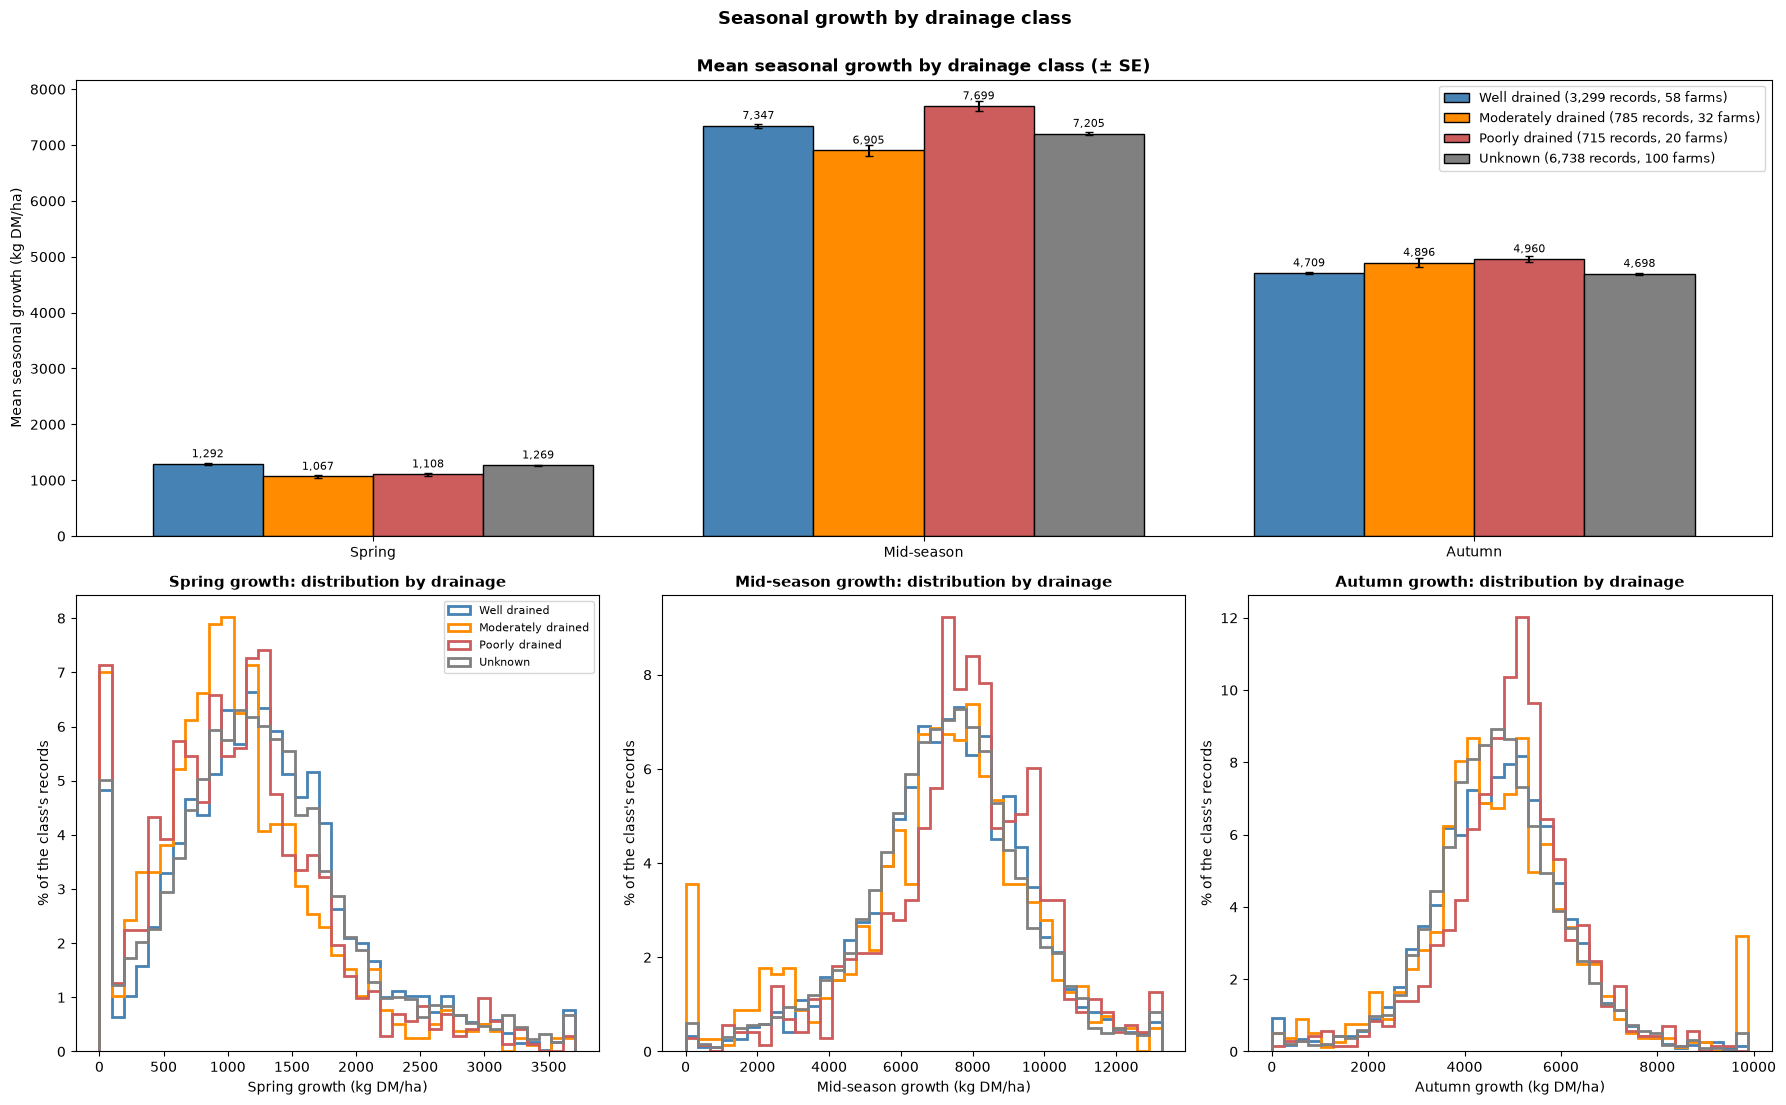

In [40]:
# =============================================================================
# SEASONAL DM BY DRAINAGE
# =============================================================================
section("Seasonal growth by drainage class")
# top: mean ± SE of spring, mid-season and autumn growth per drainage class (drainage filled in section 5.1);
# bottom: distribution of each season within each class, as a share of the class's records
drain_order = ["Well drained", "Moderately drained", "Poorly drained", DRAINAGE_UNKNOWN_LABEL]
drain_colours = {"Well drained": "steelblue", "Moderately drained": "darkorange", "Poorly drained": "indianred",
                 DRAINAGE_UNKNOWN_LABEL: "grey"}
drain_seasons = [("Spring_total", "Spring"), ("Mid_total", "Mid-season"), ("Aut_total", "Autumn")]

drain_stats = df.groupby("DRAINAGE").agg(records=(TARGET, "size"), farms=("Farm_number", "nunique"),
                                         **{f"{name} mean": (col, "mean") for col, name in drain_seasons},
                                         **{f"{name} median": (col, "median") for col, name in drain_seasons}).reindex(drain_order)
print(drain_stats.round(0).to_string())

fig = plt.figure(figsize=(18, 11))
grid = fig.add_gridspec(2, 3, height_ratios=[1, 1])

# top: grouped bars, one group per season, one bar per drainage class
ax = fig.add_subplot(grid[0, :])
width = 0.2
for k, drain in enumerate(drain_order):
    part = df[df["DRAINAGE"] == drain]
    means = [part[col].mean() for col, _ in drain_seasons]
    ses = [part[col].std() / np.sqrt(part[col].notna().sum()) for col, _ in drain_seasons]
    x = np.arange(len(drain_seasons)) + (k - 1.5) * width
    bars = ax.bar(x, means, width, yerr=ses, capsize=3, color=drain_colours[drain], edgecolor="black",
                  label=f"{drain} ({len(part):,} records, {part['Farm_number'].nunique()} farms)")
    for b, v in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, v + 120, f"{v:,.0f}", ha="center", fontsize=8)
ax.set_xticks(range(len(drain_seasons)), [name for _, name in drain_seasons])
ax.set_ylabel("Mean seasonal growth (kg DM/ha)")
ax.set_title("Mean seasonal growth by drainage class (± SE)", fontsize=12, fontweight="bold")
ax.legend(fontsize=9, loc="upper right")

# bottom: one histogram per season, outlines per drainage class
for j, (col, name) in enumerate(drain_seasons):
    ax = fig.add_subplot(grid[1, j])
    upper = df[col].quantile(0.995)
    bins = np.linspace(0, upper, 40)
    for drain in drain_order:
        values = df.loc[df["DRAINAGE"] == drain, col].dropna()
        ax.hist(values.clip(upper=upper), bins=bins, weights=np.full(len(values), 100 / len(values)),
                histtype="step", lw=2, color=drain_colours[drain], label=drain)
    ax.set_title(f"{name} growth: distribution by drainage", fontsize=11, fontweight="bold")
    ax.set_xlabel(f"{name} growth (kg DM/ha)")
    ax.set_ylabel("% of the class's records")
    if j == 0:
        ax.legend(fontsize=8)

plt.suptitle("Seasonal growth by drainage class", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "10_seasonal_growth_by_drainage")
plt.show()

**Summary:** in **spring** well drained paddocks grow the most (1,292 kg DM/ha against 1,067-1,108), while in **mid-season** poorly drained paddocks grow the most (7,699) and moderately drained the least (6,905). These are raw averages from few farms (poorly drained: 20 farms, moderately drained: 32), so they partly reflect where the farms are. About 3.5% of moderately drained records have zero mid-season growth, which looks like a problem with how growth is split between the seasons.

In [41]:
# =============================================================================
# CORRELATIONS
# =============================================================================
section("Correlation heatmap")
# Pearson (linear) and Spearman (monotonic) correlations between numeric columns
num_for_corr = df[all_num_cols + ["YEAR", "Grazing_PPI", "GROUNDSCORE"]]
corr_pearson = num_for_corr.corr(method="pearson")
corr_spearman = num_for_corr.corr(method="spearman")

fig = px.imshow(corr_pearson.round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                aspect="auto", title="Correlation heatmap - Pearson")
save_fig(fig, "08_correlation_pearson", height=1200)
fig.show()
fig = px.imshow(corr_spearman.round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                aspect="auto", title="Correlation heatmap - Spearman")
save_fig(fig, "07_correlation_spearman", height=1200)
fig.show()

for name, corr in [("Pearson", corr_pearson), ("Spearman", corr_spearman)]:
    section(f"Top absolute correlations with Total_DM_S - {name}")
    print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(12).round(3).to_string())


Correlation heatmap



Top absolute correlations with Total_DM_S - Pearson
Mid_total        0.772
Grazing_Total    0.656
Total_events     0.541
Aut_total        0.514
Num_grazings     0.415
Spring_total     0.381
Silage_Total     0.249
Autumn_Cont      0.204
Num_SILAGE       0.203
summer_cont      0.160
YEAR             0.110
age              0.080

Top absolute correlations with Total_DM_S - Spearman
Mid_total        0.775
Grazing_Total    0.674
Aut_total        0.547
Total_events     0.522
Num_grazings     0.405
Spring_total     0.391
Silage_Total     0.220
Num_SILAGE       0.201
Autumn_Cont      0.152
YEAR             0.123
age              0.119
summer_cont      0.107


**Summary:** the strongest correlations with `Total_DM_S` are its own components and the number of grazings, which are **outcomes, not predictors**, and are kept out of the feature set. Among real predictors the correlations are weak (sward age slightly negative, soil and sowing rate close to zero), which supports adding the weather data.

### Why η and Cramér's V instead of a correlation

A correlation (Pearson or Spearman) compares **two numeric variables** and assumes their values have a meaningful order: Pearson uses the distances between values, Spearman their ranks. That holds for yields, soil tests and sward age, but not for categories such as county, variety, drainage or sward type:

- **The codes are arbitrary.** With Cork = 1, Tipperary = 2, Limerick = 3 and so on, the correlation depends on the order in which the counties happen to be numbered; another numbering gives another answer, so the value means nothing.
- **One-hot encoding** (one 0/1 column per county) avoids that, but gives 19 separate correlations instead of one answer for "county".

Two measures answer the same question on the same 0-1 scale without needing an order:

| Pair of variables | Measure | Meaning of the value |
|---|---|---|
| numeric and numeric | Pearson / Spearman correlation (absolute value) | how closely the two move together |
| categorical and numeric | **correlation ratio η** | η² = share of the numeric variable's variation explained by the category means |
| categorical and categorical | **Cramér's V** | strength of the link in a crosstab, from the chi-square statistic |

Both reduce to an ordinary correlation in the simplest case: for a category with two levels coded 0/1, **η equals the absolute correlation** with that 0/1 code, and for two such categories **Cramér's V equals the absolute correlation** between the two 0/1 codes. η and V are therefore the extension of a correlation to variables with more than two unordered levels. Unlike a correlation they have no sign: they say how strong a link is, not in which direction.


**Association of every variable with `Total_DM_S` on one scale:**

- **Unordered categories** (county, variety, drainage): **η = √η²**, where η² = variation in `Total_DM_S` between the levels ÷ total variation; η is on the same 0-1 scale as an absolute correlation.
- **Numeric columns:** |Spearman ρ|, with the sign kept in its own column.
- **Ordered codes and sward age** (`YEAR`, `age`, `Select`, `Pindex`): both ρ and η; the table uses the larger of the two.
- **Levels with fewer than `MIN_LEVEL_ROWS` (30) records are grouped as "Other"** before η is calculated, so a variable with many small levels (453 variety names) does not get a high η from noise. Missing values are their own level.
- Same-year outcome columns are shown in grey: they are outcomes, not explanatory variables.


Association with Total_DM_S: |Spearman rho| for numeric, eta for categorical
     variable                  type      measure  strength  ρ (signed)     η  levels     n  η²  (share explained)
     Total_DM     same-year outcome |Spearman ρ|     1.000       1.000   NaN     NaN 11537                    NaN
    Mid_total     same-year outcome |Spearman ρ|     0.775       0.775   NaN     NaN 11537                    NaN
Grazing_Total     same-year outcome |Spearman ρ|     0.674       0.674   NaN     NaN 11537                    NaN
    Aut_total     same-year outcome |Spearman ρ|     0.547       0.547   NaN     NaN 11537                    NaN
  AUT_GRAZING     same-year outcome |Spearman ρ|     0.534       0.534   NaN     NaN 11537                    NaN
 Total_events     same-year outcome |Spearman ρ|     0.522       0.522   NaN     NaN 11537                    NaN
  MID_GRAZING     same-year outcome |Spearman ρ|     0.490       0.490   NaN     NaN 11537                    NaN
 Num_grazi

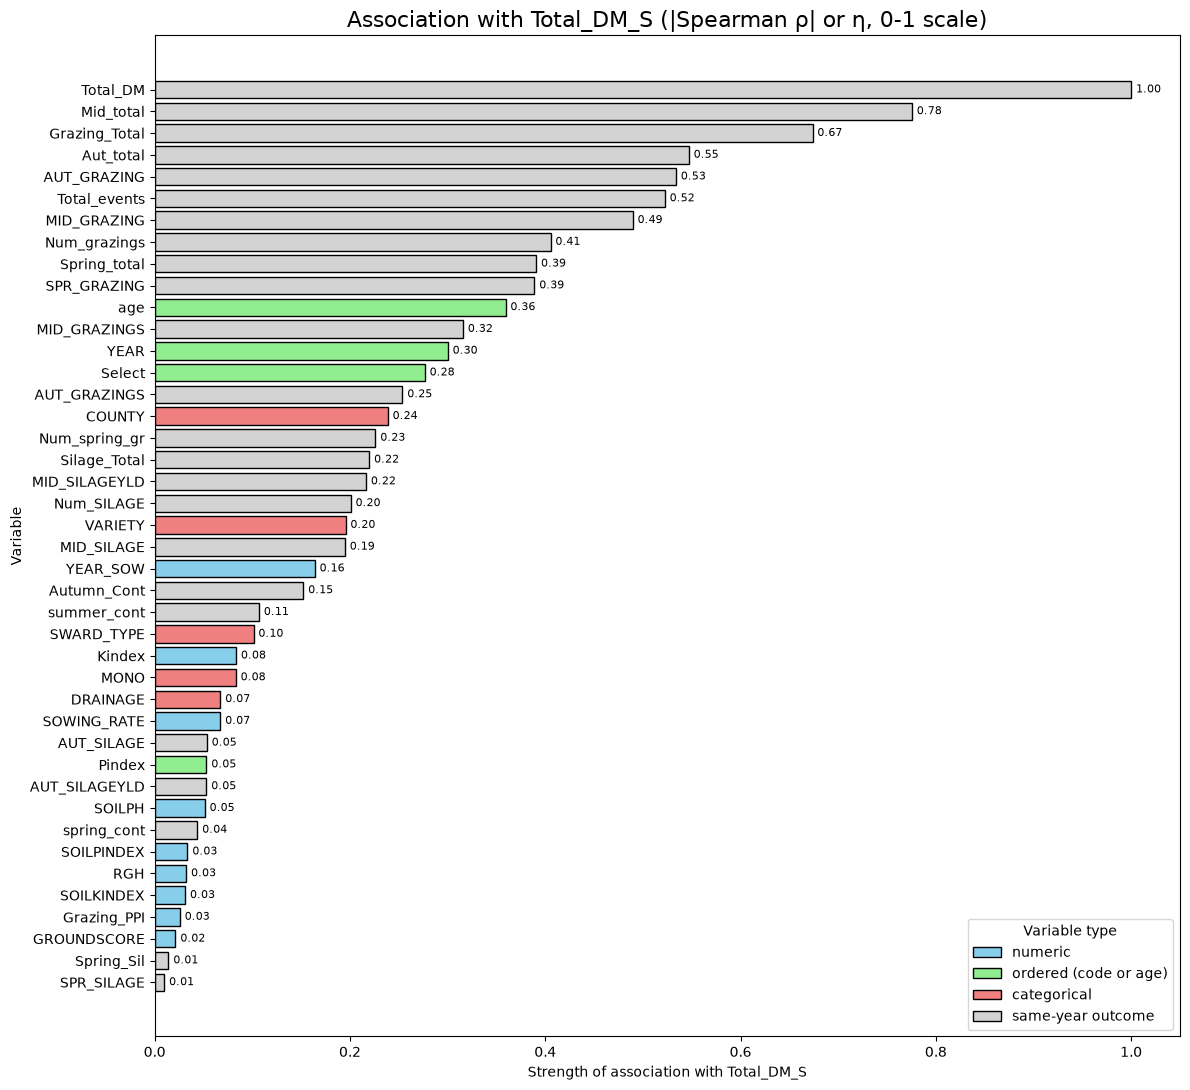

In [42]:
# =============================================================================
# ASSOCIATION WITH TOTAL_DM: SPEARMAN AND ETA
# =============================================================================
section("Association with Total_DM_S: |Spearman rho| for numeric, eta for categorical")
# one 0-1 strength per variable; rare categorical levels grouped as 'Other' so eta is not inflated
MIN_LEVEL_ROWS = 30

def eta(levels: pd.Series, y: pd.Series) -> float:
    # correlation ratio: sqrt(between-level sum of squares / total sum of squares)
    d = pd.DataFrame({"level": levels, "y": y}).dropna(subset=["y"])
    level_means = d.groupby("level")["y"].transform("mean")
    return float(np.sqrt(((level_means - d["y"].mean()) ** 2).sum() / ((d["y"] - d["y"].mean()) ** 2).sum()))

def grouped_levels(col: str) -> pd.Series:
    # categorical levels (missing as 'Missing'), rare levels grouped as 'Other'
    s = cat_levels(col)
    counts = s.value_counts()
    return s.where(s.map(counts) >= MIN_LEVEL_ROWS, "Other")

outcome_cols = [c for c in growth_cols + component_cols + event_cols + season_event_cols + share_cols if c not in [TARGET, "age"]]
outcome_cols += ["Total_DM"]
numeric_vars = [c for c in hist_cols if c not in [TARGET, "age"]]
ordered_vars = ["YEAR", "age", "Select", "Pindex"]   # age: sowing-year dip, peak at year 1, then decline (not a straight line)
nominal_vars = ["COUNTY", "DRAINAGE", "SWARD_TYPE", "VARIETY", "MONO"]

rows = []
for c in numeric_vars:
    d = df[[c, TARGET]].dropna()
    rho = d[c].corr(d[TARGET], method="spearman")
    rows.append({"variable": c, "type": "same-year outcome" if c in outcome_cols else "numeric",
                 "measure": "|Spearman ρ|", "strength": abs(rho), "ρ (signed)": rho, "η": np.nan, "levels": np.nan, "n": len(d)})
for c in ordered_vars:
    d = df[[c, TARGET]].dropna()
    rho = d[c].corr(d[TARGET], method="spearman")
    e = eta(grouped_levels(c), df[TARGET])
    rows.append({"variable": c, "type": "ordered (code or age)", "measure": "max(|ρ|, η)", "strength": max(abs(rho), e),
                 "ρ (signed)": rho, "η": e, "levels": grouped_levels(c).nunique(), "n": len(df)})
for c in nominal_vars:
    lv = grouped_levels(c)
    rows.append({"variable": c, "type": "categorical", "measure": "η", "strength": eta(lv, df[TARGET]),
                 "ρ (signed)": np.nan, "η": eta(lv, df[TARGET]), "levels": lv.nunique(), "n": len(df)})

association = pd.DataFrame(rows).sort_values("strength", ascending=False).reset_index(drop=True)
association["η²  (share explained)"] = association["η"] ** 2
print(association.round(3).to_string(index=False))
print(f"\nVARIETY without grouping (all {df['VARIETY'].nunique()} names): η = {eta(cat_levels('VARIETY'), df[TARGET]):.3f} "
      f"vs {association.loc[association['variable'] == 'VARIETY', 'η'].iloc[0]:.3f} with levels under {MIN_LEVEL_ROWS} rows grouped")

# chart: explanatory variables in colour, same-year outcomes in grey
colours = {"numeric": "skyblue", "ordered (code or age)": "lightgreen", "categorical": "lightcoral", "same-year outcome": "lightgrey"}
plot = association.iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 11))
ax.barh(plot["variable"], plot["strength"], color=plot["type"].map(colours), edgecolor="black")
for y_pos, (v, m) in enumerate(zip(plot["strength"], plot["measure"])):
    ax.text(v + 0.005, y_pos, f"{v:.2f}", va="center", fontsize=8)
ax.set_title("Association with Total_DM_S (|Spearman ρ| or η, 0-1 scale)", fontsize=16)
ax.set_xlabel("Strength of association with Total_DM_S")
ax.set_ylabel("Variable")
ax.legend(handles=[Patch(facecolor=col, edgecolor="black", label=t) for t, col in colours.items()], title="Variable type", loc="lower right")
plt.tight_layout()
save_fig(fig, "06_association_with_total_dm_s")
plt.show()


**Summary:** among the explanatory variables, **sward age has the strongest association (η = 0.36, 13% of the variation in `Total_DM_S`)**, followed by year (0.30), `Select` (0.28, a grouping of sward age), county (0.24) and variety (0.20); sward type explains about 1%, and soil tests, drainage, `MONO`, PPI and ground score each less than 1%. The rank correlations for age and year are much weaker (ρ = 0.12 and −0.12) because neither effect is a straight line. No single explanatory variable explains more than 13%, so the variation in `Total_DM_S` comes from many factors together.

**Cramér's V between the categorical variables.** η compares each category with `Total_DM_S`; Cramér's V compares the categorical variables **with each other**. Two variables with a high V carry largely the same information (for categories this plays the role of the VIF check for numeric inputs), so a linear model should not use both.



Cramér's V between categorical variables


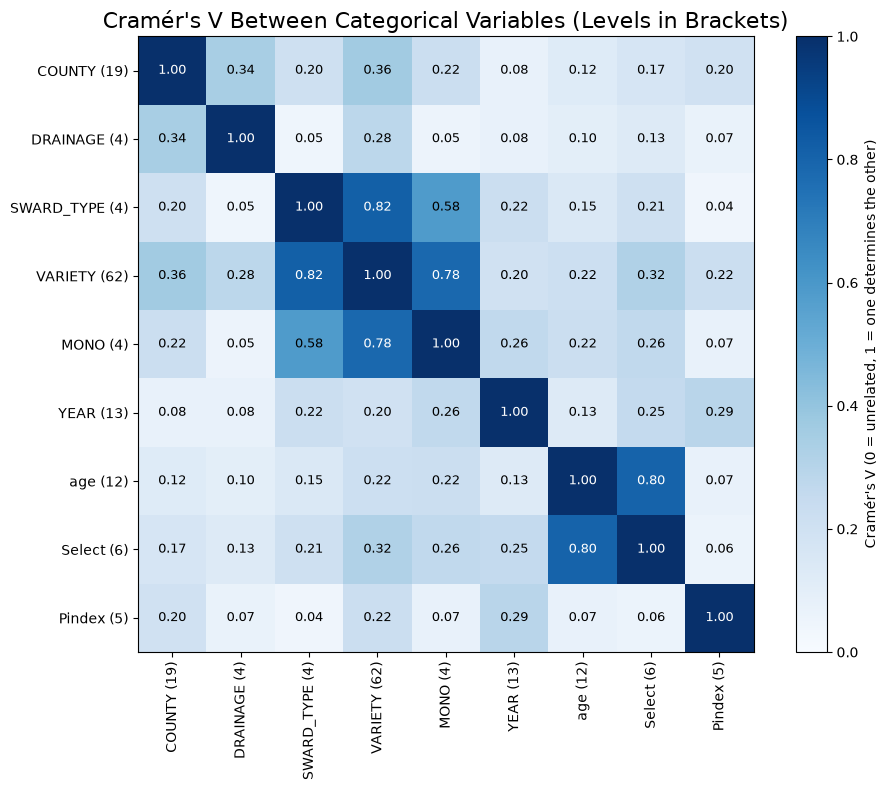

Pairs sorted by Cramér's V:
SWARD_TYPE  VARIETY       0.815
age         Select        0.802
VARIETY     MONO          0.784
SWARD_TYPE  MONO          0.582
COUNTY      VARIETY       0.362
            DRAINAGE      0.343
VARIETY     Select        0.316
YEAR        Pindex        0.291
DRAINAGE    VARIETY       0.279
MONO        Select        0.262
            YEAR          0.262
YEAR        Select        0.255
MONO        age           0.223
COUNTY      MONO          0.221
VARIETY     Pindex        0.221
SWARD_TYPE  YEAR          0.220
VARIETY     age           0.217
SWARD_TYPE  Select        0.205
COUNTY      SWARD_TYPE    0.203
VARIETY     YEAR          0.197
COUNTY      Pindex        0.196
            Select        0.165
SWARD_TYPE  age           0.148
YEAR        age           0.130
DRAINAGE    Select        0.128
COUNTY      age           0.123
DRAINAGE    age           0.098
COUNTY      YEAR          0.078
DRAINAGE    YEAR          0.076
MONO        Pindex        0.073
age         

In [43]:
# =============================================================================
# CRAMÉR'S V: ASSOCIATION BETWEEN CATEGORICAL VARIABLES
# =============================================================================
section("Cramér's V between categorical variables")
# V from the chi-square of each crosstab; same level grouping as for eta (rare levels -> 'Other', missing -> 'Missing')
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    k = min(table.shape)
    if k < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (k - 1))))

v_vars = nominal_vars + ordered_vars
v_levels = {c: grouped_levels(c) for c in v_vars}
cramer = pd.DataFrame(np.eye(len(v_vars)), index=v_vars, columns=v_vars)
for i, a in enumerate(v_vars):
    for b in v_vars[i + 1:]:
        cramer.loc[a, b] = cramer.loc[b, a] = cramers_v(v_levels[a], v_levels[b])

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cramer.values, cmap="Blues", vmin=0, vmax=1)
for i in range(len(v_vars)):
    for j in range(len(v_vars)):
        ax.text(j, i, f"{cramer.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if cramer.iloc[i, j] > 0.6 else "black")
ax.set_xticks(range(len(v_vars)))
ax.set_xticklabels([f"{c} ({v_levels[c].nunique()})" for c in v_vars], rotation=90)
ax.set_yticks(range(len(v_vars)))
ax.set_yticklabels([f"{c} ({v_levels[c].nunique()})" for c in v_vars])
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Cramér's V (0 = unrelated, 1 = one determines the other)")
ax.set_title("Cramér's V Between Categorical Variables (Levels in Brackets)", fontsize=16)
plt.tight_layout()
plt.show()

pairs = (cramer.where(np.triu(np.ones(cramer.shape, dtype=bool), k=1)).stack()
               .rename("Cramér's V").sort_values(ascending=False).round(3))
print("Pairs sorted by Cramér's V:")
print(pairs.to_string())


**Summary:** three groups of categorical variables largely repeat each other: **`VARIETY` and `SWARD_TYPE` (V = 0.82)**, **`MONO` with `VARIETY` (0.78) and `SWARD_TYPE` (0.58)**, and **`age` and `Select` (0.80)**. County is moderately linked to variety (0.36) and drainage (0.34), and year is only weakly linked to the paddock variables (all below 0.30). One variable from each group is enough, so `Select` and `MONO` are left out of the analysis dataset.

### Combined views of the main predictors

Sward age, year, sward type and region each shift `Total_DM_S` on their own (boxplots above). The charts below show them **together**: whether the decline with age differs between diploids, tetraploids, mixtures and multispecies swards, and whether the 2018 drought hit every sward age and every region in the same way. Sward age is grouped into bands (0 = sowing year, 1-3, 4-6, 7-10, 11+); rows without a sowing year are left out of the age charts.


Total_DM_S by sward age band and sward type


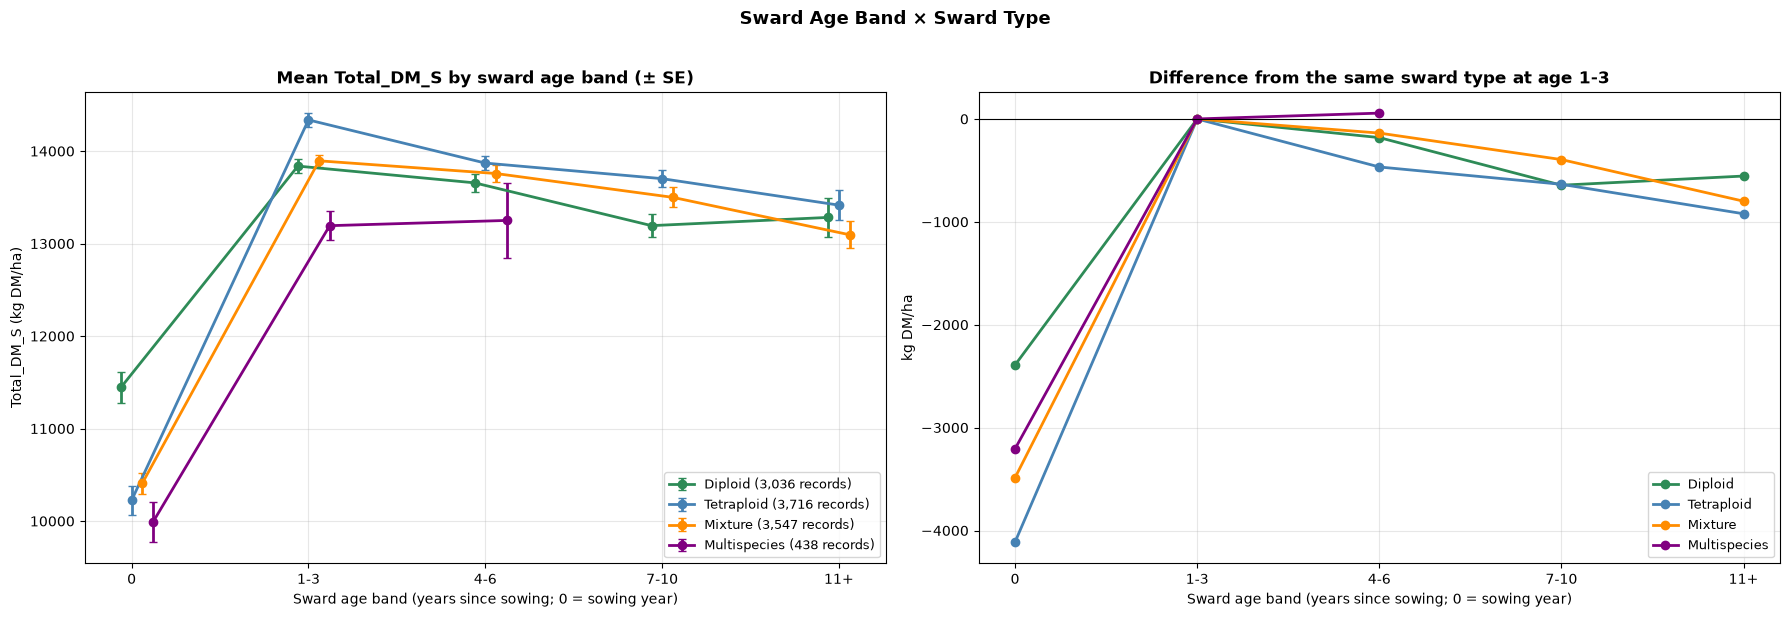

Mean Total_DM_S (kg DM/ha):
AGE_BAND            0      1-3      4-6     7-10      11+
SWARD_TYPE                                               
Diploid       11447.0  13838.0  13657.0  13194.0  13283.0
Mixture       10409.0  13895.0  13758.0  13500.0  13096.0
Multispecies   9988.0  13194.0  13250.0      NaN      NaN
Tetraploid    10225.0  14337.0  13871.0  13702.0  13416.0

Records (farms):
AGE_BAND             0         1-3        4-6      7-10       11+
SWARD_TYPE                                                       
Diploid       320 (61)  1214 (100)   838 (90)  506 (69)  158 (31)
Mixture       516 (61)   1358 (69)   840 (64)  587 (55)  246 (31)
Multispecies  132 (30)    283 (31)     23 (6)       NaN       NaN
Tetraploid    264 (65)  1412 (104)  1107 (90)  696 (73)  237 (30)

Change from age 1-3 (kg DM/ha):
AGE_BAND        4-6   7-10    11+
SWARD_TYPE                       
Diploid      -181.0 -644.0 -555.0
Mixture      -137.0 -395.0 -799.0
Multispecies   57.0    NaN    NaN
Tetrapl

In [44]:
# =============================================================================
# SWARD AGE BAND × SWARD TYPE
# =============================================================================
section("Total_DM_S by sward age band and sward type")
# mean ± SE per age band, one line per sward type; right panel: difference from the type's own 1-3 year mean
type_colours = {"Diploid": "seagreen", "Tetraploid": "steelblue", "Mixture": "darkorange", "Multispecies": "purple"}
eda = df.assign(AGE_BAND=pd.cut(df["age"], **AGE_BANDS).astype(str).replace("nan", np.nan))

age_type = (eda.dropna(subset=["AGE_BAND"]).groupby(["SWARD_TYPE", "AGE_BAND"])
            .agg(records=(TARGET, "size"), farms=("Farm_number", "nunique"), mean=(TARGET, "mean"), sd=(TARGET, "std")))
age_type["se"] = age_type["sd"] / np.sqrt(age_type["records"])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
x = np.arange(len(AGE_BANDS["labels"]))
for k, (sward, colour) in enumerate(type_colours.items()):
    part = age_type.loc[sward].reindex(AGE_BANDS["labels"])
    axes[0].errorbar(x + (k - 1) * 0.06, part["mean"], yerr=part["se"], color=colour, marker="o", lw=2, capsize=3,
                     label=f"{sward} ({int(part['records'].sum()):,} records)")
    axes[1].plot(x, part["mean"] - part.loc["1-3", "mean"], color=colour, marker="o", lw=2, label=sward)
axes[0].set_title("Mean Total_DM_S by sward age band (± SE)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Total_DM_S (kg DM/ha)")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Difference from the same sward type at age 1-3", fontsize=12, fontweight="bold")
axes[1].set_ylabel("kg DM/ha")
for ax in axes:
    ax.set_xticks(x, AGE_BANDS["labels"])
    ax.set_xlabel("Sward age band (years since sowing; 0 = sowing year)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
plt.suptitle("Sward Age Band × Sward Type", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "11_age_band_by_sward_type")
plt.show()

print("Mean Total_DM_S (kg DM/ha):")
print(age_type["mean"].unstack().reindex(columns=AGE_BANDS["labels"]).round(0).to_string())
print("\nRecords (farms):")
print((age_type["records"].astype(str) + " (" + age_type["farms"].astype(str) + ")").unstack().reindex(columns=AGE_BANDS["labels"]).to_string())
decline = age_type["mean"].unstack()
print("\nChange from age 1-3 (kg DM/ha):")
print(decline[["4-6", "7-10", "11+"]].sub(decline["1-3"], axis=0).round(0).to_string())

**Summary:** **tetraploids start highest and decline most with age**: 14,337 kg DM/ha at age 1-3, then −466 kg by age 4-6 and −921 kg by 11+, against −555 kg for diploids and −799 kg for mixtures at 11+. Mixtures lose the least by age 4-6 (−137 kg). In the sowing year diploids grow the most (11,447 against 9,988-10,409). Multispecies swards appear only from 2020 and reach age 4-6 at most; they are the lowest group in the sowing year and at age 1-3 (13,194). The 11+ groups are small (158-246 records, about 30 farms), and these are raw means, not adjusted for farm or year.

In [45]:
# =============================================================================
# YEAR × SWARD AGE BAND AND YEAR × REGION
# =============================================================================
section("Total_DM_S by year, sward age band and region")
# each row of the heatmaps is compared with its own mean over all years, so groups with different levels can be compared;
# blue = above the group's own mean, red = below
def year_heatmap(group_col, order, title, png):
    means = eda.groupby([group_col, "YEAR"])[TARGET].mean().unstack().reindex(order)
    records = eda.groupby([group_col, "YEAR"]).size().unstack().reindex(order)
    deviation = means.sub(means.mean(axis=1), axis=0)
    fig = px.imshow(deviation.round(0), text_auto=True, color_continuous_scale="RdBu", zmin=-3000, zmax=3000, aspect="auto",
                    labels={"x": "Year", "y": group_col, "color": "kg DM/ha vs own mean"}, title=title)
    fig.update_traces(customdata=np.dstack([means.values, records.values]),
                      hovertemplate="%{y} %{x}<br>mean %{customdata[0]:,.0f} kg DM/ha<br>%{customdata[1]} records<extra></extra>")
    fig.update_xaxes(dtick=1)
    save_fig(fig, png)
    fig.show()
    return means, records

age_means, age_records = year_heatmap("AGE_BAND", AGE_BANDS["labels"], "Total_DM_S by year and sward age band: difference from the band's own mean (kg DM/ha)", "12_year_by_age_band")
region_order = eda["REGION"].value_counts().index.tolist()
region_means, region_records = year_heatmap("REGION", region_order, "Total_DM_S by year and region: difference from the region's own mean (kg DM/ha)", "13_year_by_region")

# the 2018 drop in each group: 2018 against 2017 and against the mean of the group's other years
def drop_2018(means, records):
    other = means.drop(columns=2018).mean(axis=1)
    return pd.DataFrame({"records 2018": records[2018], "mean 2017": means[2017], "mean 2018": means[2018],
                         "2018 vs 2017": means[2018] - means[2017], "2018 vs other years": means[2018] - other,
                         "2018 vs other years %": (means[2018] / other - 1) * 100}).round(0)

section("The 2018 drop by sward age band")
print(drop_2018(age_means, age_records).to_string())
section("The 2018 drop by region")
print(drop_2018(region_means, region_records).to_string())
print("\nFarms per region in 2018:", eda[eda["YEAR"] == 2018].groupby("REGION")["Farm_number"].nunique().reindex(region_order).to_dict())


Total_DM_S by year, sward age band and region



The 2018 drop by sward age band
          records 2018  mean 2017  mean 2018  2018 vs 2017  2018 vs other years  2018 vs other years %
AGE_BAND                                                                                              
0                 57.0        NaN     9259.0           NaN              -1279.0                  -12.0
1-3              230.0    15341.0    12242.0       -3099.0              -2024.0                  -14.0
4-6              281.0    15752.0    12535.0       -3217.0              -1427.0                  -10.0
7-10             107.0    16174.0    11896.0       -4278.0              -2749.0                  -19.0
11+               14.0        NaN    12645.0           NaN              -1111.0                   -8.0

The 2018 drop by region
                     records 2018  mean 2017  mean 2018  2018 vs 2017  2018 vs other years  2018 vs other years %
REGION                                                                                                     

**Summary:** **2018 is below the group's own mean in every sward age band and every region**, so the drought hit everywhere, but not equally. Across age bands the drop is 8-19% against the other years, largest for swards aged 7-10 (−2,749 kg DM/ha). In most regions it is 11-16%, while the West lost only 2% (−202 kg). The West, North-west and East and North-east rest on 4 farms each in 2018 (14-63 records), so the regional differences are uncertain. 2017 was a high year everywhere, so the drop from 2017 to 2018 (2,000-4,300 kg) is larger than the drop from an average year. Age band 0 and 11+ have no records in 2017.

### Scatter matrix of the main numeric inputs

The main numeric inputs plotted against each other and against `Total_DM_S`: last year's growth of the same paddock and sowing, sward age, soil pH, P and K, and sowing rate. Below the diagonal each dot is one paddock-year, on the diagonal is each variable's distribution, and above the diagonal the Spearman correlation with the number of paddock-years behind it.

Last year's growth (`PREV_YEAR_DM`) is calculated here for the chart only: the `Total_DM_S` of the same paddock and the same sowing in the year before; it is missing in a sward's first recorded year. For the chart only, sowing rates above 100 kg/ha (34 entry errors, see the outlier checks) and soil pH outside 4.5-8.5 are left out; the data itself is not changed.


Scatter matrix of the main numeric inputs


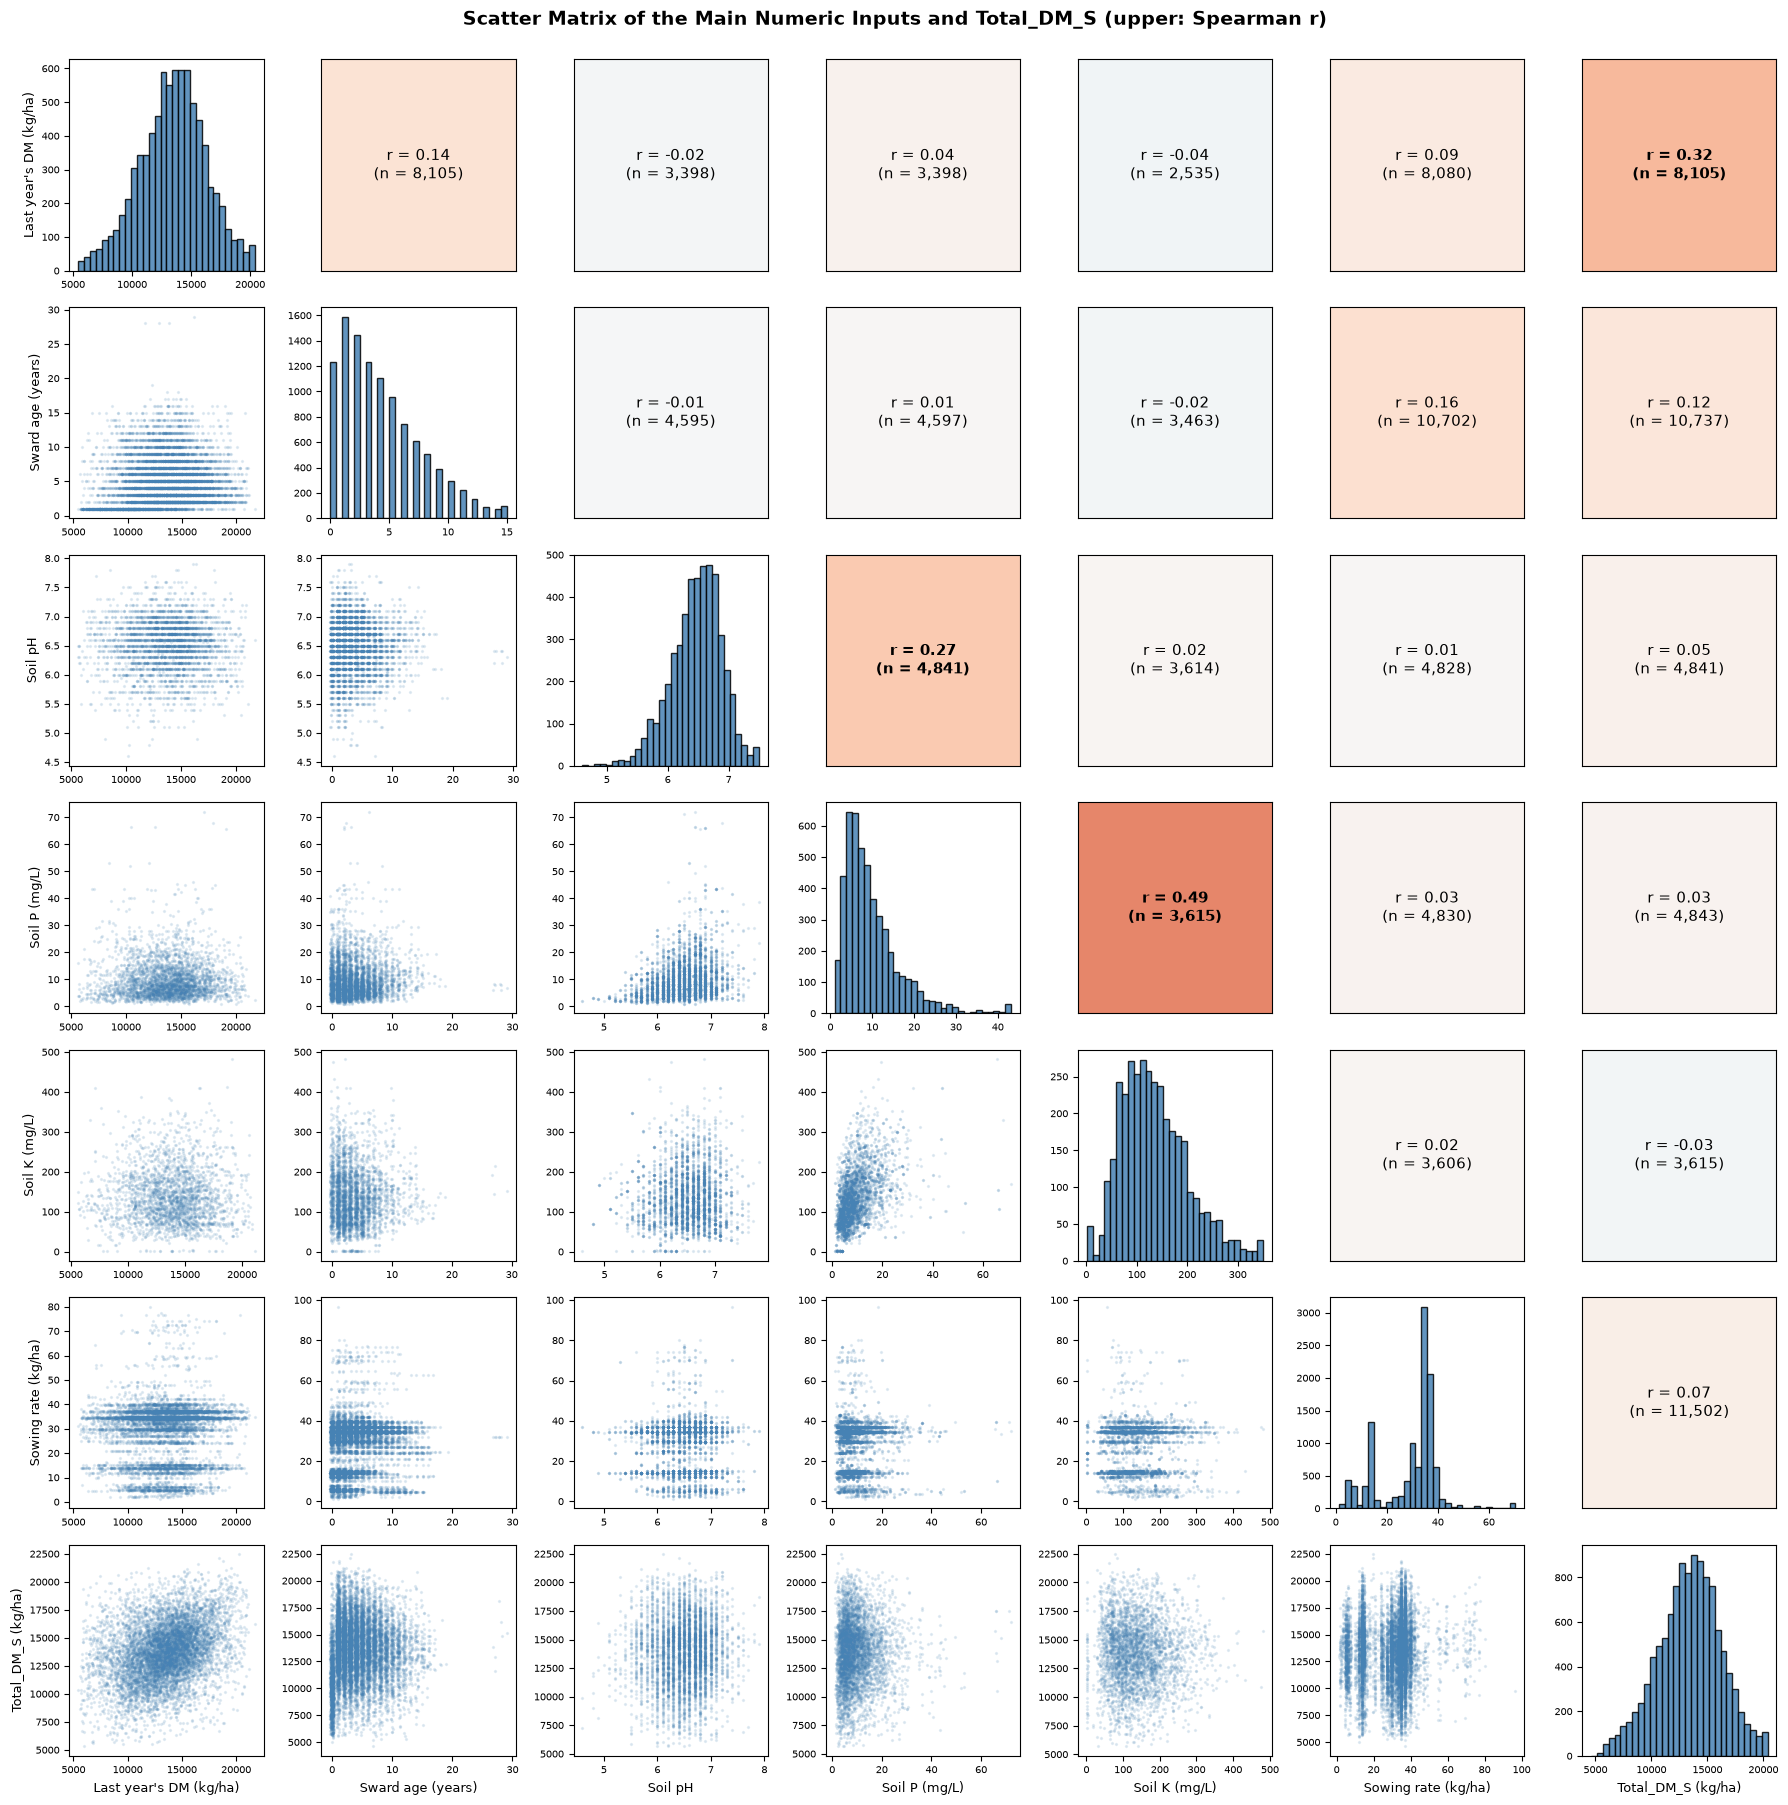

Spearman correlations:
              PREV_YEAR_DM   age  SOILPH  SOILPINDEX  SOILKINDEX  SOWING_RATE  Total_DM_S
PREV_YEAR_DM          1.00  0.14   -0.02        0.04       -0.04         0.09        0.32
age                   0.14  1.00   -0.01        0.01       -0.02         0.16        0.12
SOILPH               -0.02 -0.01    1.00        0.27        0.02         0.01        0.05
SOILPINDEX            0.04  0.01    0.27        1.00        0.49         0.03        0.03
SOILKINDEX           -0.04 -0.02    0.02        0.49        1.00         0.02       -0.03
SOWING_RATE           0.09  0.16    0.01        0.03        0.02         1.00        0.07
Total_DM_S            0.32  0.12    0.05        0.03       -0.03         0.07        1.00

Last year's DM available: 8,105 rows | left out of the chart: 34 sowing rates above 100 kg/ha, 2 pH values outside 4.5-8.5


In [46]:
# =============================================================================
# SCATTER MATRIX: MAIN NUMERIC INPUTS
# =============================================================================
section("Scatter matrix of the main numeric inputs")
# lower triangle: scatter (small random shift for whole-number columns), diagonal: histogram, upper triangle: Spearman r (n)
sm = chart_inputs(df)

sm_vars = {"PREV_YEAR_DM": "Last year's DM (kg/ha)", "age": "Sward age (years)", "SOILPH": "Soil pH",
           "SOILPINDEX": "Soil P (mg/L)", "SOILKINDEX": "Soil K (mg/L)", "SOWING_RATE": "Sowing rate (kg/ha)",
           TARGET: "Total_DM_S (kg/ha)"}
cols = list(sm_vars)
rng = np.random.default_rng(RANDOM_STATE)
spearman = sm[cols].corr(method="spearman")
pair_n = sm[cols].notna().astype(int).T.dot(sm[cols].notna().astype(int))

fig, axes = plt.subplots(len(cols), len(cols), figsize=(18, 18))
for r, y_col in enumerate(cols):
    for c, x_col in enumerate(cols):
        ax = axes[r, c]
        if r == c:
            values = sm[x_col].dropna()
            ax.hist(values.clip(upper=values.quantile(0.995)), bins=30, color="steelblue", edgecolor="black", alpha=0.85)
        elif r > c:
            d = sm[[x_col, y_col]].dropna()
            jitter = rng.uniform(-0.3, 0.3, len(d)) if d[x_col].nunique() < 30 else 0
            ax.scatter(d[x_col] + jitter, d[y_col], s=2, alpha=0.12, color="steelblue")
        else:
            rho = spearman.loc[y_col, x_col]
            ax.set_facecolor(plt.cm.RdBu_r(0.5 + rho / 2))
            ax.text(0.5, 0.5, f"r = {rho:.2f}\n(n = {pair_n.loc[y_col, x_col]:,})", ha="center", va="center",
                    fontsize=11, fontweight="bold" if abs(rho) >= 0.2 else "normal", transform=ax.transAxes)
            ax.set_xticks([])
            ax.set_yticks([])
        if r == len(cols) - 1:
            ax.set_xlabel(sm_vars[x_col], fontsize=9)
        if c == 0:
            ax.set_ylabel(sm_vars[y_col], fontsize=9)
        ax.tick_params(labelsize=7)
plt.suptitle("Scatter Matrix of the Main Numeric Inputs and Total_DM_S (upper: Spearman r)", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "09_scatter_matrix")
plt.show()

print("Spearman correlations:")
print(spearman.round(2).to_string())
print(f"\nLast year's DM available: {sm['PREV_YEAR_DM'].notna().sum():,} rows | left out of the chart: "
      f"{int((df['SOWING_RATE'] > 100).sum())} sowing rates above 100 kg/ha, {int((df['SOILPH'].notna() & ~df['SOILPH'].between(4.5, 8.5)).sum())} pH values outside 4.5-8.5")

**Summary:** **last year's growth has the clearest link with `Total_DM_S`** (Spearman r = 0.32), followed by sward age (0.12, mainly through the low sowing year); soil pH, P, K and sowing rate are each close to zero (−0.03 to 0.07). Among the inputs, soil P goes with K (0.49) and pH (0.27), and sowing rate rises slightly with age (0.16); no two inputs are strongly correlated, so each carries separate information. The scatter clouds are wide at every value, so none of these inputs predicts growth well on its own.

## 7. Location: Map and Grass Type per County

In [47]:
# =============================================================================
# COUNTY BOUNDARIES
# =============================================================================
# county outlines from geojson (Republic of Ireland), merging city/county parts into one county
with open(BOUNDARY_PATH, encoding="utf-8") as f:
    boundaries = json.load(f)

def county_name(name):
    if "Tipperary" in name:
        return "Tipperary"
    if name in ["Dublin City", "Fingal", "South Dublin"] or "Laoghaire" in name:
        return "Dublin"
    return name.replace(" County", "").replace(" City", "")

county_shapes = {}
for feature in boundaries["features"]:
    for polygon in feature["geometry"]["coordinates"]:
        county_shapes.setdefault(county_name(feature["properties"]["name"]), []).append(np.array(polygon[0]))

# borders without the lines between parts of the same county
border_lines = []
for rings in county_shapes.values():
    edges = Counter()
    for ring in rings:
        for a, b in zip(ring[:-1], ring[1:]):
            edges[tuple(sorted([tuple(np.round(a, 5)), tuple(np.round(b, 5))]))] += 1
    border_lines += [e for e, n in edges.items() if n == 1]

def draw_counties(ax, colors_by_county=None, default="whitesmoke"):
    patches, facecolors = [], []
    for name, rings in county_shapes.items():
        for ring in rings:
            patches.append(Polygon(ring))
            facecolors.append((colors_by_county or {}).get(name, default))
    ax.add_collection(PatchCollection(patches, facecolor=facecolors, edgecolor=facecolors, linewidth=0.3))
    ax.add_collection(LineCollection(border_lines, color="grey", linewidth=0.6))
    ax.set_xlim(-10.8, -5.8)
    ax.set_ylim(51.3, 55.5)
    ax.set_aspect(1 / np.cos(np.radians(53.5)))
    ax.axis("off")

rng = np.random.default_rng(RANDOM_STATE)
def random_point_in(name):
    # random point inside the county's largest part
    ring = max(county_shapes[name], key=len)
    path = MplPath(ring)
    (x0, y0), (x1, y1) = ring.min(axis=0), ring.max(axis=0)
    while True:
        point = (rng.uniform(x0, x1), rng.uniform(y0, y1))
        if path.contains_point(point):
            return point

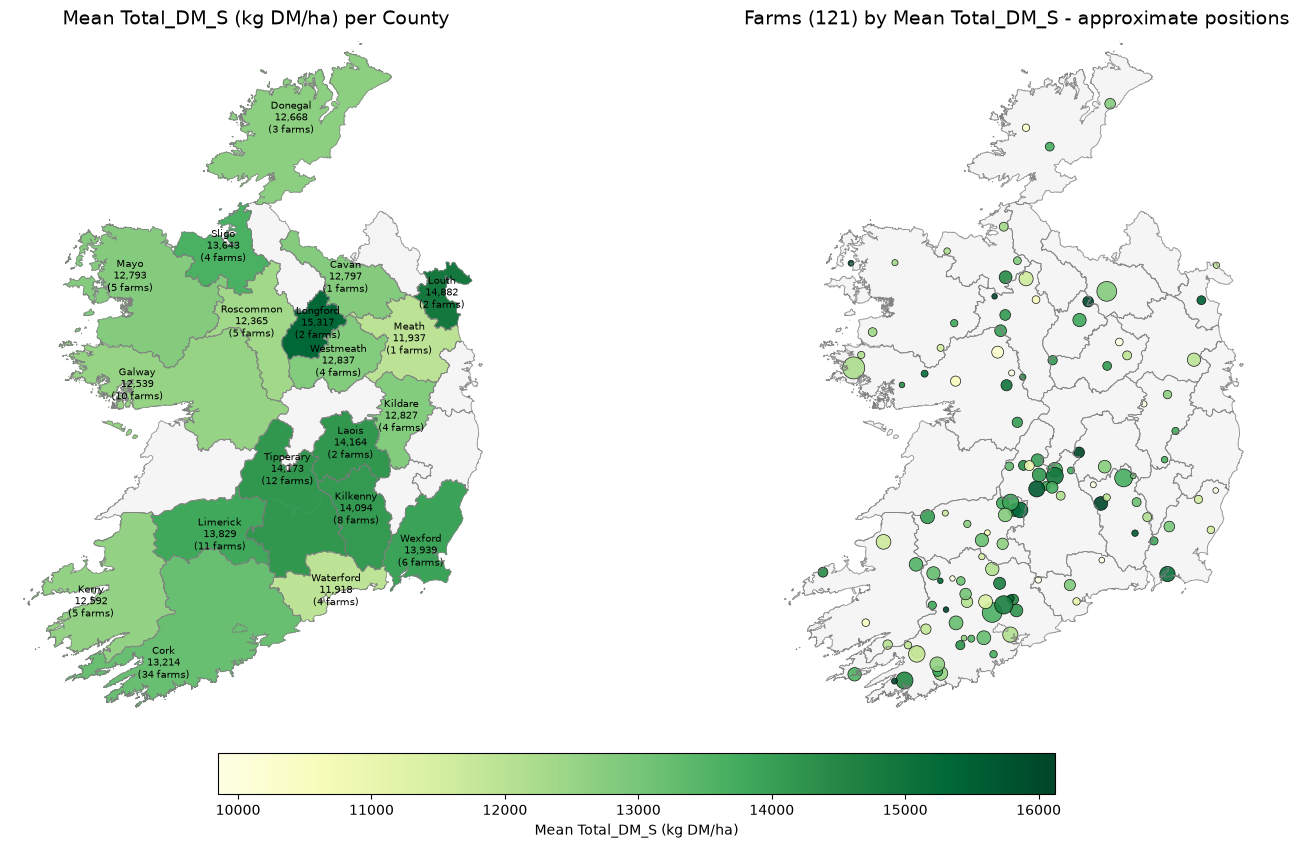

In [48]:
# =============================================================================
# MAP: MEAN TOTAL_DM PER COUNTY AND FARMS
# =============================================================================
# farms have no coordinates, so each farm is placed at a random point inside its county (approximate)
county_stats = df.groupby("COUNTY").agg(mean_dm=(TARGET, "mean"), farms=("Farm_number", "nunique"))
farm_stats = df.groupby(["Farm_number", "COUNTY"]).agg(mean_dm=(TARGET, "mean"), records=(TARGET, "size")).reset_index()
farm_stats[["lon", "lat"]] = [random_point_in(c) for c in farm_stats["COUNTY"]]

norm = mcolors.Normalize(vmin=farm_stats["mean_dm"].quantile(0.05), vmax=farm_stats["mean_dm"].quantile(0.95))
cmap = plt.cm.YlGn

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 11))
draw_counties(ax1, {c: cmap(norm(v)) for c, v in county_stats["mean_dm"].items()})
for county, row in county_stats.iterrows():
    x, y = max(county_shapes[county], key=len).mean(axis=0)
    ax1.annotate(f"{county}\n{row['mean_dm']:,.0f}\n({int(row['farms'])} farms)", (x, y), ha="center", va="center", fontsize=7)
ax1.set_title("Mean Total_DM_S (kg DM/ha) per County", fontsize=14)

draw_counties(ax2)
ax2.scatter(farm_stats["lon"], farm_stats["lat"], c=farm_stats["mean_dm"], cmap=cmap, norm=norm,
            s=farm_stats["records"] / 2 + 15, edgecolor="black", linewidth=0.5, alpha=0.9)
ax2.set_title(f"Farms ({farm_stats['Farm_number'].nunique()}) by Mean Total_DM_S - approximate positions", fontsize=14)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=[ax1, ax2], shrink=0.6, location="bottom", pad=0.03)
cbar.set_label("Mean Total_DM_S (kg DM/ha)")
save_fig(fig, "14_county_map")
plt.show()

In [49]:
# =============================================================================
# GRASS TYPE PER COUNTY
# =============================================================================
section("Sward type per county")
# each sowing (paddock + YEAR_SOW) counted once
sowings = df.drop_duplicates(["PADDOCK", "YEAR_SOW"])
county_order = sowings["COUNTY"].value_counts().index.tolist()
type_order = ["Diploid", "Tetraploid", "Mixture", "Multispecies"]

county_type = pd.crosstab(sowings["COUNTY"], sowings["SWARD_TYPE"]).reindex(index=county_order, columns=type_order)
county_type_pct = pct(county_type.div(county_type.sum(axis=1), axis=0)).round(0)
print(county_type_pct.to_string())

fig = px.bar(county_type_pct.reset_index().melt(id_vars="COUNTY", var_name="sward type", value_name="pct"),
             x="COUNTY", y="pct", color="sward type", title="Sward type per county (% of sowings)",
             category_orders={"COUNTY": county_order}, color_discrete_sequence=["skyblue", "lightgreen", "khaki", "plum"])
fig.show()

singles = sowings[sowings["SWARD_TYPE"].isin(["Diploid", "Tetraploid"])]
top15 = singles["VARIETY"].value_counts().head(15).index
county_variety = pd.crosstab(singles["COUNTY"], singles["VARIETY"])
county_variety_pct = pct(county_variety.div(county_variety.sum(axis=1), axis=0))[top15].reindex(county_order).round(0)
fig = px.imshow(county_variety_pct, text_auto=True, color_continuous_scale="Greens", aspect="auto",
                title="Top 15 varieties per county (% of single-variety sowings)")
fig.update_layout(height=700)
fig.show()

county_type_dm = df.pivot_table(index="COUNTY", columns="SWARD_TYPE", values=TARGET, aggfunc="mean").reindex(index=county_order, columns=type_order)
county_type_n = df.pivot_table(index="COUNTY", columns="SWARD_TYPE", values=TARGET, aggfunc="size").reindex(index=county_order, columns=type_order)
fig = px.imshow(county_type_dm.where(county_type_n >= 10).round(0), text_auto=True, color_continuous_scale="YlGn",
                aspect="auto", title="Mean Total_DM_S per county and sward type (blank = fewer than 10 records)")
fig.update_layout(height=700)
save_fig(fig, "15_dm_by_county_and_sward_type")
fig.show()


Sward type per county
SWARD_TYPE  Diploid  Tetraploid  Mixture  Multispecies
COUNTY                                                
Cork           26.0        29.0     38.0           7.0
Limerick       31.0        38.0     24.0           7.0
Galway         26.0        18.0     46.0          10.0
Tipperary      24.0        35.0     38.0           3.0
Kilkenny       28.0        42.0     30.0           0.0
Wexford        44.0        20.0     33.0           2.0
Cavan           8.0         9.0     82.0           0.0
Kerry          26.0        37.0     32.0           5.0
Laois          40.0        28.0      5.0          28.0
Longford       16.0        56.0     18.0           9.0
Roscommon      33.0        46.0     21.0           0.0
Meath          12.0        28.0     60.0           0.0
Sligo          32.0        22.0     45.0           0.0
Waterford       6.0        42.0     53.0           0.0
Donegal        37.0         9.0     31.0          23.0
Westmeath      23.0        35.0     32.0  

**Summary:** Longford, Louth, Tipperary and Laois have the highest county means and Waterford, Meath, Roscommon and Galway the lowest; farm positions on the map are approximate (only the county is real). Tetraploids grow the most overall (about 13,650 kg DM/ha), then diploids and ryegrass mixtures, with multispecies swards lowest (about 12,230), but the order changes by county.